# ML model development — section 04 + final evaluation (steps 24–32)

> **Development notebook.** Converted to `util/ml_model_development.py` (same code, one function per step) and called from `script/mlpipeline.ipynb`. Change this notebook first, then re-convert and check the outputs are identical.

V6.6 section 04: *keep baseline and AutoML as separate checkpoints; compare fairly using identical folds and metrics.*

| Step | Section | Main output (`datamart/ml/model_development/v1/`) |
|---|---|---|
| **24** | Define and train baseline | `metric_contract.yaml`, `cv_folds.csv`, `baseline_metrics.csv`, `baseline_summary.json` |
| **25** | Candidates: LR, RF, XGB × A_raw / A_fe / B_raw / B_fe | `leaderboard.csv`, `candidate_predictions.parquet` |
| **26** | Class imbalance | `imbalance_results.csv`, `imbalance_decision.yaml` |
| **27** | Explainability (permutation importance, SHAP) | `feature_importance_table.csv`, `shortlist_decision.yaml` |
| **28** | Feature reduction (one-standard-error rule) | `reduced_features.json`, `reduction_curve.csv` |
| **29** | Hyperparameter tuning (Optuna) | `tuning_trials.csv`, `best_params.yaml` |
| **30** | Final fit, threshold, sign-off | `final/` (models, model cards, sign-off) |
| **31** | Final evaluation on test + OOT (once) | `final_evaluation.yaml`, `final_comparison.csv` |
| **32** | Error and robustness analysis | `error_segments.csv`, `robustness_*.csv`, `error_robustness_summary.yaml` |

**Data rule:** models are developed on **train** (cross-validation) and **validation** only. **Test and OOT are used only in step 31** (final evaluation).

In [1]:
import os, sys, json, hashlib, warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import yaml
import joblib

PROJECT_DIR = os.environ.get("PROJECT_DIR") or ("/app" if os.path.isdir("/app/data") else os.path.abspath(".."))
sys.path.insert(0, PROJECT_DIR)
from util import dataprocessing_bronze as bronze
from util import dataprocessing_gold as gold
from util import ml_feature_engineering as fe

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, log_loss,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             precision_recall_curve, roc_curve)
from sklearn.calibration import calibration_curve

MD_VERSION = "v1"
MD_DIR = os.path.join(PROJECT_DIR, "datamart", "ml", "model_development", MD_VERSION)
ART_DIR = os.path.join(MD_DIR, "artifacts")
CHART_DIR = os.path.join(MD_DIR, "charts")
for d in (MD_DIR, ART_DIR, CHART_DIR):
    os.makedirs(d, exist_ok=True)
SEED = 42

spark = bronze.get_spark("ml_model_development")

## Model table

Joins, per loan: Gold feature store v1 (68 features) + generated features (step 21) + split partition (step 14) + label (mature labels only). Train and validation are loaded here; test and OOT are loaded in step 31.

In [2]:
def build_model_table(partitions=("train", "validation")):
    ctx = gold.load_eda_data(spark)                       # features for every loan (+ partition), flags as 0/1
    afe = pd.read_parquet(os.path.join(fe.FE_DIR, "autofe_features.parquet")).drop(columns="partition")
    labels = (spark.read.parquet(gold.LABEL_STORE_PATH).filter("maturity_status = 'mature'")
              .select("loan_id", "label").toPandas())
    df = ctx["data"].merge(afe, on="loan_id", how="left")
    df = df[df["partition"].isin(partitions)].merge(labels, on="loan_id", how="inner")
    manifest = pd.read_csv(os.path.join(gold.SPLIT_DIR, "split_manifest.csv"), usecols=["loan_id", "partition"])
    expected = manifest["partition"].isin(partitions).sum()
    assert df["loan_id"].is_unique and len(df) == expected, "model table must have one row per loan, none lost"
    return {p: df[df["partition"] == p].reset_index(drop=True) for p in partitions}, ctx

tables, ctx = build_model_table()
train_df, val_df = tables["train"], tables["validation"]
print(f"train {len(train_df):,} loans (default {train_df['label'].mean():.2%}) | "
      f"validation {len(val_df):,} loans (default {val_df['label'].mean():.2%})")

FEATURE_SETS = fe.load_feature_sets()
CAT, BINARY = ctx["categorical"], ctx["binary"]
FLAGGED = {c[: -len("_invalid")] for c in ctx["features_a"] if c.endswith("_invalid")}

train 6,281 loans (default 28.86%) | validation 1,346 loans (default 28.90%)


---

## Step 24 — Define and train baseline

### Metric contract (fixed before any candidate model)

| Item | Decision | Why |
|---|---|---|
| **Primary metric** | **PR-AUC** (average precision) | Defaults are the minority (~29%); PR-AUC focuses on how well defaulters are ranked, unlike accuracy |
| Secondary | ROC-AUC, Brier score (calibration), log loss, precision / recall / F1 at the threshold | Ranking, probability quality and decision quality |
| Threshold | 0.5 for the baseline report; the operating threshold is chosen on **validation** later — the threshold that **maximises F1** (user decision) | Never tuned on test / OOT. No misclassification cost is assumed — there is no business basis for one |
| **Minimum improvement** | a candidate must beat the logistic-regression baseline by **≥ 0.02 PR-AUC** (5-fold CV mean) **and** by more than the baseline's fold standard deviation | Ignore gains within noise |
| Protocol | 5-fold stratified CV on train (seed 42, folds saved), then fit on all of train and score validation | Identical folds for every later step |

### Baselines

| Baseline | Features | Purpose |
|---|---|---|
| `dummy_prior` | none | Always predicts the training default rate — the floor (PR-AUC ≈ prevalence, ROC-AUC = 0.5) |
| `logreg_A_raw` | **A_raw linear list** (original features only) + the step-18 linear preprocessing | Simple, explainable ML baseline every candidate must beat |

In [3]:
METRIC_CONTRACT = {
    "version": MD_VERSION,
    "label": gold.LABEL_DEF,
    "positive_class": 1,
    "primary_metric": "pr_auc",
    "secondary_metrics": ["roc_auc", "brier", "log_loss", "precision", "recall", "f1"],
    "report_threshold": 0.5,
    "threshold_policy": {"rule": "threshold that maximises F1 on validation probabilities", "decided_by": "user (2026-10-19)", "never_on": ["test", "oot"]},
    "operational_cost": "none assumed (no business basis); revisit if the business provides FN/FP costs",
    "minimum_improvement": {"metric": "pr_auc", "versus": "logreg_A_raw", "statistic": "5-fold CV mean",
                            "absolute": 0.02, "also_exceed_baseline_cv_std": True},
    "protocol": {"cv": "StratifiedKFold", "n_splits": 5, "shuffle": True, "seed": SEED, "fit_partition": "train",
                 "evaluation_partitions": ["cv on train", "validation"], "final_evaluation_only": ["test", "oot"]},
    "created_ts": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
}
with open(os.path.join(MD_DIR, "metric_contract.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(METRIC_CONTRACT, f, sort_keys=False)

def evaluate(y, p, threshold=0.5):
    y, p = np.asarray(y), np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(pr_auc=average_precision_score(y, p), roc_auc=roc_auc_score(y, p), brier=brier_score_loss(y, p),
                log_loss=log_loss(y, p), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0),
                tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn))

In [4]:
# Fixed CV folds on train (saved; every later step reuses them)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = np.zeros(len(train_df), dtype=int)
for k, (_, idx) in enumerate(skf.split(train_df, train_df["label"])):
    folds[idx] = k
cv_folds = pd.DataFrame({"loan_id": train_df["loan_id"], "fold": folds, "label": train_df["label"]})
cv_folds.to_csv(os.path.join(MD_DIR, "cv_folds.csv"), index=False)
fold_rates = cv_folds.groupby("fold")["label"].agg(["size", "mean"])
assert (fold_rates["mean"] - train_df["label"].mean()).abs().max() < 0.01, "folds not stratified"
print("Fold sizes:", fold_rates["size"].tolist(), "| default rate per fold:", (fold_rates["mean"] * 100).round(2).tolist())

Fold sizes: [1257, 1256, 1256, 1256, 1256] | default rate per fold: [28.88, 28.82, 28.82, 28.9, 28.9]


In [5]:
A_RAW_LINEAR = FEATURE_SETS["A_raw"]["linear"]
BASELINES = {
    "dummy_prior": (A_RAW_LINEAR, lambda: Pipeline([("model", DummyClassifier(strategy="prior"))])),
    "logreg_A_raw": (A_RAW_LINEAR, lambda: Pipeline([
        ("pre", fe.build_preprocessor(A_RAW_LINEAR, "linear", CAT, BINARY, FLAGGED)),
        ("model", LogisticRegression(max_iter=5000, C=1.0))])),
}

rows, oof, val_pred, fitted = [], {}, {}, {}
for name, (feats, make) in BASELINES.items():
    p_oof = np.zeros(len(train_df))
    for k in range(5):
        tr, te = folds != k, folds == k
        m = make()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m.fit(train_df.loc[tr, feats], train_df.loc[tr, "label"])
        p_oof[te] = m.predict_proba(train_df.loc[te, feats])[:, 1]
        rows.append(dict(model=name, evaluation=f"cv_fold_{k}", **evaluate(train_df.loc[te, "label"], p_oof[te])))
    oof[name] = p_oof
    m = make()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m.fit(train_df[feats], train_df["label"])          # preprocessing fitted inside, on train only
    fitted[name] = m
    val_pred[name] = m.predict_proba(val_df[feats])[:, 1]
    rows.append(dict(model=name, evaluation="validation", **evaluate(val_df["label"], val_pred[name])))
    joblib.dump(m, os.path.join(ART_DIR, f"baseline_{name}.joblib"))

metrics_long = pd.DataFrame(rows)
cv = metrics_long[metrics_long["evaluation"].str.startswith("cv_fold")]
metric_cols = ["pr_auc", "roc_auc", "brier", "log_loss", "precision", "recall", "f1"]
summary = pd.concat([
    cv.groupby("model")[metric_cols].mean().assign(evaluation="cv_mean"),
    cv.groupby("model")[metric_cols].std().assign(evaluation="cv_std"),
]).reset_index()
baseline_metrics = pd.concat([metrics_long, summary], ignore_index=True)    # per fold + validation + CV mean/std
summary = pd.concat([summary, metrics_long[metrics_long["evaluation"] == "validation"][["model", "evaluation"] + metric_cols]],
                    ignore_index=True)
baseline_metrics.to_csv(os.path.join(MD_DIR, "baseline_metrics.csv"), index=False)

pd.concat([
    pd.DataFrame({"loan_id": train_df["loan_id"], "partition": "train", "source": "out-of-fold", "fold": folds,
                  "label": train_df["label"], **{f"p_{k}": v for k, v in oof.items()}}),
    pd.DataFrame({"loan_id": val_df["loan_id"], "partition": "validation", "source": "fit on train", "fold": -1,
                  "label": val_df["label"], **{f"p_{k}": v for k, v in val_pred.items()}}),
]).to_csv(os.path.join(MD_DIR, "baseline_predictions.csv"), index=False)

view = summary.pivot_table(index="model", columns="evaluation", values=["pr_auc", "roc_auc", "brier"]).round(4)
view

brier                     pr_auc                    roc_auc  \
evaluation   cv_mean  cv_std validation cv_mean  cv_std validation cv_mean   
model                                                                        
dummy_prior   0.2053  0.0002     0.2055  0.2886  0.0004     0.2890   0.500   
logreg_A_raw  0.1667  0.0032     0.1669  0.5640  0.0101     0.5772   0.763   

                                 
evaluation    cv_std validation  
model                            
dummy_prior   0.0000     0.5000  
logreg_A_raw  0.0141     0.7603

In [6]:
# Minimum-improvement target for step 25 (derived from the frozen baseline)
lr_cv = cv[cv["model"] == "logreg_A_raw"]["pr_auc"]
target = lr_cv.mean() + max(METRIC_CONTRACT["minimum_improvement"]["absolute"], lr_cv.std())
print(f"logreg_A_raw CV PR-AUC {lr_cv.mean():.4f} ± {lr_cv.std():.4f}  ->  a candidate needs CV PR-AUC >= {target:.4f}")
print(f"dummy_prior  CV PR-AUC {cv[cv['model'] == 'dummy_prior']['pr_auc'].mean():.4f} (= prevalence)")
summary[summary["evaluation"].isin(["cv_mean", "validation"])][["model", "evaluation"] + metric_cols].style.hide(
    axis="index").format({c: "{:.4f}" for c in metric_cols})

logreg_A_raw CV PR-AUC 0.5640 ± 0.0101  ->  a candidate needs CV PR-AUC >= 0.5840
dummy_prior  CV PR-AUC 0.2886 (= prevalence)


model,evaluation,pr_auc,roc_auc,brier,log_loss,precision,recall,f1
dummy_prior,cv_mean,0.2886,0.5000,0.2053,0.6009,0.0000,0.0000,0.0000
logreg_A_raw,cv_mean,0.5640,0.7630,0.1667,0.5088,0.6152,0.4203,0.4991
dummy_prior,validation,0.2890,0.5000,0.2055,0.6013,0.0000,0.0000,0.0000
logreg_A_raw,validation,0.5772,0.7603,0.1669,0.5104,0.6008,0.3907,0.4735


### Baseline charts

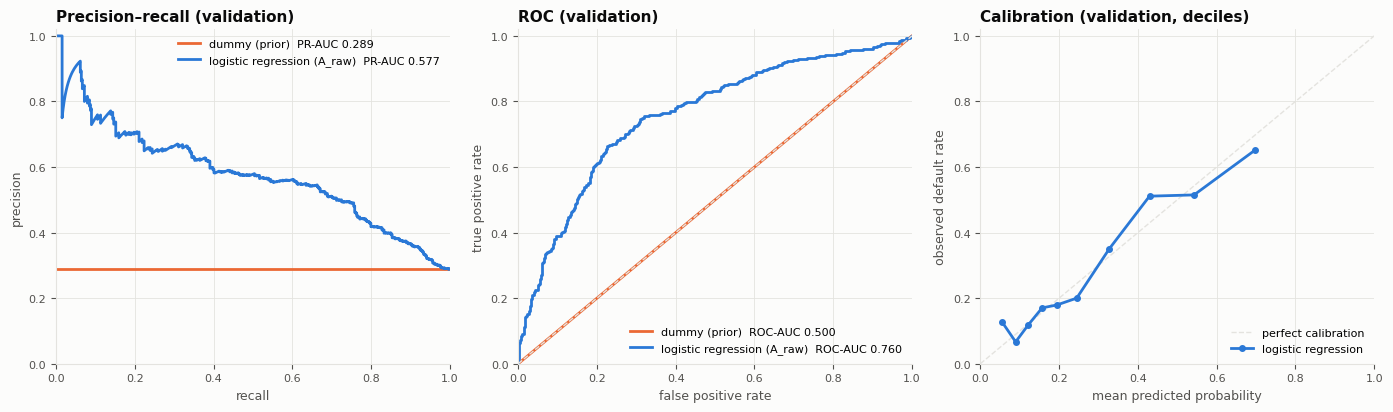

In [7]:
import matplotlib.pyplot as plt
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "legend.fontsize": 8, "font.size": 9, "lines.linewidth": 2})

y_val = val_df["label"].values
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
names = {"dummy_prior": "dummy (prior)", "logreg_A_raw": "logistic regression (A_raw)"}
for color, (name, p) in zip([SERIES[1], SERIES[0]], val_pred.items()):
    if name == "dummy_prior":      # constant score: precision = prevalence at every recall
        axes[0].axhline(y_val.mean(), color=color, label=f"{names[name]}  PR-AUC {average_precision_score(y_val, p):.3f}")
    else:
        prec, rec, _ = precision_recall_curve(y_val, p)
        axes[0].plot(rec, prec, color=color, label=f"{names[name]}  PR-AUC {average_precision_score(y_val, p):.3f}")
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[1].plot(fpr, tpr, color=color, label=f"{names[name]}  ROC-AUC {roc_auc_score(y_val, p):.3f}")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_title("Precision–recall (validation)")
axes[1].plot([0, 1], [0, 1], color=GRID, linestyle="--", linewidth=1)
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC (validation)")
frac, mean_p = calibration_curve(y_val, val_pred["logreg_A_raw"], n_bins=10, strategy="quantile")
axes[2].plot([0, 1], [0, 1], color=GRID, linestyle="--", linewidth=1, label="perfect calibration")
axes[2].plot(mean_p, frac, color=SERIES[0], marker="o", markersize=4, label="logistic regression")
axes[2].set_xlabel("mean predicted probability"); axes[2].set_ylabel("observed default rate")
axes[2].set_title("Calibration (validation, deciles)")
for ax in axes:
    ax.legend(loc="lower right" if ax is not axes[0] else "upper right")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "24_1_baseline_curves.png"), dpi=130, bbox_inches="tight")
plt.show()

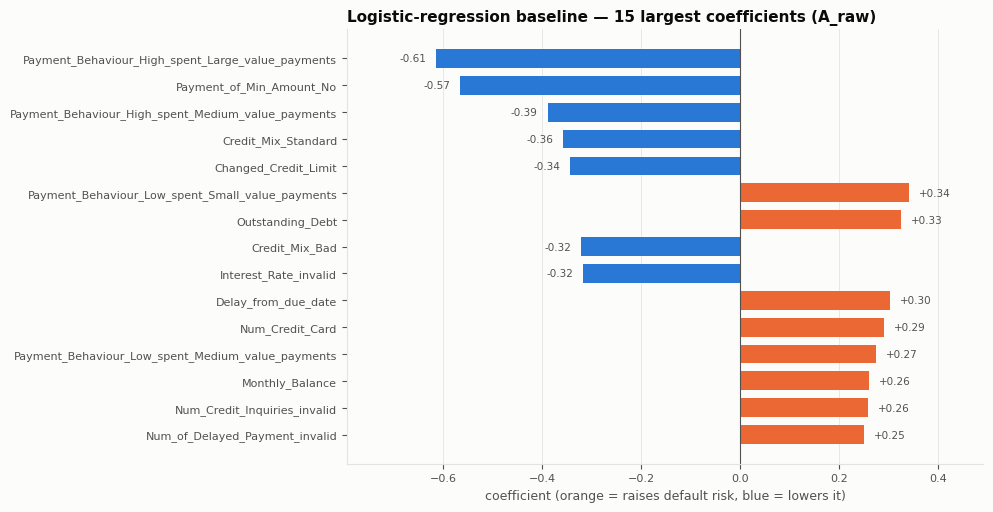

In [8]:
# Logistic-regression coefficients (standardised inputs after the quantile transform): what the baseline relies on
lr = fitted["logreg_A_raw"]
coef = pd.Series(lr.named_steps["model"].coef_[0], index=lr.named_steps["pre"].get_feature_names_out())
coef.index = [c.split("__", 1)[1] for c in coef.index]
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)[::-1]
coef.rename("coefficient").to_frame().to_csv(os.path.join(MD_DIR, "baseline_logreg_coefficients.csv"))

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(top.index, top.values, color=[SERIES[1] if v > 0 else SERIES[0] for v in top.values], height=0.7)
ax.axvline(0, color=INK_2, linewidth=0.8)
for yv, v in enumerate(top.values):
    ax.text(v + (0.02 if v > 0 else -0.02), yv, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right",
            fontsize=7.5, color=INK_2)
ax.set_xlim(top.min() - 0.18, top.max() + 0.15)
ax.set_xlabel("coefficient (orange = raises default risk, blue = lowers it)")
ax.grid(axis="y", visible=False)
ax.set_title("Logistic-regression baseline — 15 largest coefficients (A_raw)")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "24_2_baseline_coefficients.png"), dpi=130, bbox_inches="tight")
plt.show()

**Reading the coefficients:** inputs are quantile-transformed, so numeric coefficients are comparable in size. Every category level is one-hot encoded (including `Missing`), so category coefficients are **relative to the other levels of the same feature** — e.g. `Credit_Mix_Bad` can be negative overall while still being riskier than `Good`. Importance is analysed properly (SHAP / permutation) in step 27.

### Baseline summary (reference for step 25)

The baseline's CV result and the resulting candidate target are saved for step 25.

In [9]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

# Reproducibility: refitting the logistic baseline gives the same validation predictions
m2 = BASELINES["logreg_A_raw"][1]()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m2.fit(train_df[A_RAW_LINEAR], train_df["label"])
assert np.allclose(m2.predict_proba(val_df[A_RAW_LINEAR])[:, 1], val_pred["logreg_A_raw"]), "baseline not reproducible"

BASE = {"step": 24, "version": MD_VERSION, "created_ts": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
        "baseline_model": "logreg_A_raw", "baseline_cv_pr_auc_mean": float(lr_cv.mean()),
        "baseline_cv_pr_auc_std": float(lr_cv.std()), "candidate_target_cv_pr_auc": float(target)}
with open(os.path.join(MD_DIR, "baseline_summary.json"), "w", encoding="utf-8") as f:
    json.dump(BASE, f, indent=1)
print("Baseline summary:", json.dumps(BASE, indent=1))

Baseline summary: {
 "step": 24,
 "version": "v1",
 "created_ts": "2026-10-21T03:59:23Z",
 "baseline_model": "logreg_A_raw",
 "baseline_cv_pr_auc_mean": 0.5639780985657941,
 "baseline_cv_pr_auc_std": 0.010068362925379923,
 "candidate_target_cv_pr_auc": 0.5839780985657941
}


### Step 24 summary

- **Metric contract** fixed (PR-AUC primary; no misclassification cost assumed) and **5 CV folds** saved — identical for every later step.
- **Baselines** trained on train, evaluated by CV and on validation; test / OOT are not used until step 31.
- Step 25 must beat the logistic baseline by the minimum improvement on the same folds (`baseline_summary.json`).

---

## Step 25 — Candidate training: LR, RF, XGB on four feature sets

**Fair comparison (V6.6):** same 5 fixed folds, same metric contract, same feature policy. Each model uses the step-23 list **for its model type** and the matching step-18 preprocessing, refitted **inside every fold**.

| | Feature set | Contents | OOT-evaluable |
|---|---|---|---|
| model A | `A_raw` | original attributes + financials (raw-only baseline set) | yes |
| model A | `A_fe` | `A_raw` + OpenFE generated features | yes |
| model B | `B_raw` | `A_raw` + 20 clickstream features | **no** (no clickstream after 2024-06) |
| model B | `B_fe` | `A_fe` + clickstream | **no** |

| Model | Preprocessing | Settings (fixed, not tuned — tuning is step 29) |
|---|---|---|
| `LR` logistic regression | linear (median impute + quantile → normal, one-hot) | C = 1.0, L2 — identical to the baseline |
| `RF` random forest | tree (median impute + indicators, one-hot) | 500 trees, min 5 rows per leaf, √features per split |
| `XGB` XGBoost | tree | 400 trees, depth 4, learning rate 0.05, subsample / colsample 0.8 |

No class weights or resampling here (step 26). Candidates are chosen from **CV and validation only**; test and OOT are used only in step 31.

In [10]:
import time, io
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import sklearn, xgboost

# 1. Baseline reference and metric contract from step 24
with open(os.path.join(MD_DIR, "baseline_summary.json"), encoding="utf-8") as f:
    BASELINE = json.load(f)
with open(os.path.join(MD_DIR, "metric_contract.yaml"), encoding="utf-8") as f:
    CONTRACT = yaml.safe_load(f)
cv_saved = pd.read_csv(os.path.join(MD_DIR, "cv_folds.csv"))
assert cv_saved["loan_id"].tolist() == train_df["loan_id"].tolist() and (cv_saved["fold"].values == folds).all()
TARGET = BASELINE["candidate_target_cv_pr_auc"]
BASE_CV = cv[cv["model"] == "logreg_A_raw"].sort_values("evaluation")["pr_auc"].values      # per fold, for fold wins
print(f"Primary metric: {CONTRACT['primary_metric']}. "
      f"Baseline CV PR-AUC {BASELINE['baseline_cv_pr_auc_mean']:.4f}; candidate target {TARGET:.4f}")

MODELS = {
    "LR":  ("linear", lambda: LogisticRegression(max_iter=5000, C=1.0)),
    "RF":  ("tree", lambda: RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features="sqrt",
                                                   n_jobs=-1, random_state=SEED)),
    "XGB": ("tree", lambda: XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                                          colsample_bytree=0.8, min_child_weight=1, reg_lambda=1.0,
                                          tree_method="hist", eval_metric="aucpr", n_jobs=-1, random_state=SEED)),
}
SETS = ["A_raw", "A_fe", "B_raw", "B_fe"]

def make_pipeline(model_name, set_name):
    model_type, make_model = MODELS[model_name]
    feats = FEATURE_SETS[set_name][model_type]
    pipe = Pipeline([("pre", fe.build_preprocessor(feats, model_type, CAT, BINARY, FLAGGED)), ("model", make_model())])
    return pipe, feats

Primary metric: pr_auc. Baseline CV PR-AUC 0.5640; candidate target 0.5840


In [11]:
lb_rows, fold_rows, cand_oof, cand_val, cand_fitted = [], [], {}, {}, {}
for set_name in SETS:
    for model_name in MODELS:
        key = f"{model_name}__{set_name}"
        pipe, feats = make_pipeline(model_name, set_name)
        p_oof, fit_secs = np.zeros(len(train_df)), []
        for k in range(5):
            tr, te = folds != k, folds == k
            m, _ = make_pipeline(model_name, set_name)
            t0 = time.time()
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                m.fit(train_df.loc[tr, feats], train_df.loc[tr, "label"])
            fit_secs.append(time.time() - t0)
            p_oof[te] = m.predict_proba(train_df.loc[te, feats])[:, 1]
            fold_rows.append(dict(candidate=key, model=model_name, feature_set=set_name, fold=k,
                                  **evaluate(train_df.loc[te, "label"], p_oof[te])))
        # final fit on all of train -> validation
        t0 = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pipe.fit(train_df[feats], train_df["label"])
        full_fit = time.time() - t0
        t0 = time.time()
        p_val = pipe.predict_proba(val_df[feats])[:, 1]
        latency_ms_per_1k = (time.time() - t0) / len(val_df) * 1000 * 1000
        buf = io.BytesIO(); joblib.dump(pipe, buf)
        joblib.dump(pipe, os.path.join(ART_DIR, f"candidate_{key}.joblib"))
        cand_oof[key], cand_val[key], cand_fitted[key] = p_oof, p_val, pipe

        f_cv = pd.DataFrame([r for r in fold_rows if r["candidate"] == key])
        v = evaluate(val_df["label"], p_val)
        lb_rows.append(dict(
            candidate=key, model=model_name, feature_set=set_name,
            clickstream="yes" if set_name.startswith("B") else "no",
            generated_features="yes" if set_name.endswith("fe") else "no",
            features=len(feats), cv_pr_auc=f_cv["pr_auc"].mean(), cv_pr_auc_std=f_cv["pr_auc"].std(),
            cv_roc_auc=f_cv["roc_auc"].mean(), cv_brier=f_cv["brier"].mean(),
            fold_wins_vs_baseline=int((f_cv.sort_values("fold")["pr_auc"].values > BASE_CV).sum()),
            val_pr_auc=v["pr_auc"], val_roc_auc=v["roc_auc"], val_brier=v["brier"], val_log_loss=v["log_loss"],
            val_recall_at_0_5=v["recall"], val_precision_at_0_5=v["precision"],
            val_f1_at_0_5=v["f1"],
            delta_cv_pr_auc_vs_baseline=f_cv["pr_auc"].mean() - BASELINE["baseline_cv_pr_auc_mean"],
            meets_minimum_improvement=bool(f_cv["pr_auc"].mean() >= TARGET),
            oot_evaluable=not set_name.startswith("B"),
            fit_seconds_per_fold=float(np.mean(fit_secs)), full_fit_seconds=full_fit,
            latency_ms_per_1k_rows=latency_ms_per_1k, model_size_kb=len(buf.getvalue()) / 1024))
        print(f"{key:12s} CV PR-AUC {f_cv['pr_auc'].mean():.4f} ± {f_cv['pr_auc'].std():.4f} | "
              f"val PR-AUC {v['pr_auc']:.4f} | fit {np.mean(fit_secs):.1f}s/fold")

leaderboard = pd.DataFrame(lb_rows).sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)
leaderboard.insert(0, "rank", range(1, len(leaderboard) + 1))
leaderboard.to_csv(os.path.join(MD_DIR, "leaderboard.csv"), index=False)
pd.DataFrame(fold_rows).to_csv(os.path.join(MD_DIR, "candidate_cv_folds_metrics.csv"), index=False)
pd.concat([
    pd.DataFrame({"loan_id": train_df["loan_id"], "partition": "train", "fold": folds, "label": train_df["label"],
                  **{f"p_{k}": v for k, v in cand_oof.items()}}),
    pd.DataFrame({"loan_id": val_df["loan_id"], "partition": "validation", "fold": -1, "label": val_df["label"],
                  **{f"p_{k}": v for k, v in cand_val.items()}}),
]).to_parquet(os.path.join(MD_DIR, "candidate_predictions.parquet"), index=False)

# Sanity: LR on A_raw is the baseline configuration -> must reproduce the baseline
lr_a = leaderboard.set_index("candidate").loc["LR__A_raw"]
assert abs(lr_a["cv_pr_auc"] - BASELINE["baseline_cv_pr_auc_mean"]) < 1e-9, "LR__A_raw does not reproduce the baseline"
print("Sanity check passed: LR__A_raw reproduces the baseline exactly")

LR__A_raw    CV PR-AUC 0.5640 ± 0.0101 | val PR-AUC 0.5772 | fit 0.1s/fold


RF__A_raw    CV PR-AUC 0.6212 ± 0.0346 | val PR-AUC 0.6037 | fit 0.5s/fold


XGB__A_raw   CV PR-AUC 0.6280 ± 0.0321 | val PR-AUC 0.6169 | fit 0.6s/fold


LR__A_fe     CV PR-AUC 0.5679 ± 0.0118 | val PR-AUC 0.5844 | fit 0.1s/fold


RF__A_fe     CV PR-AUC 0.6316 ± 0.0248 | val PR-AUC 0.6060 | fit 0.5s/fold


...

RF__B_raw    CV PR-AUC 0.6445 ± 0.0311 | val PR-AUC 0.6132 | fit 0.5s/fold


XGB__B_raw   CV PR-AUC 0.6575 ± 0.0227 | val PR-AUC 0.6258 | fit 0.2s/fold


LR__B_fe     CV PR-AUC 0.6217 ± 0.0170 | val PR-AUC 0.6017 | fit 0.1s/fold


RF__B_fe     CV PR-AUC 0.6548 ± 0.0290 | val PR-AUC 0.6293 | fit 0.5s/fold


XGB__B_fe    CV PR-AUC 0.6666 ± 0.0270 | val PR-AUC 0.6331 | fit 0.3s/fold
Sanity check passed: LR__A_raw reproduces the baseline exactly


### Leaderboard

In [12]:
cols = ["rank", "candidate", "clickstream", "generated_features", "features", "cv_pr_auc", "cv_pr_auc_std",
        "delta_cv_pr_auc_vs_baseline", "fold_wins_vs_baseline", "meets_minimum_improvement", "val_pr_auc",
        "val_roc_auc", "val_brier", "oot_evaluable", "fit_seconds_per_fold", "latency_ms_per_1k_rows", "model_size_kb"]
leaderboard[cols].style.hide(axis="index").format(
    {"cv_pr_auc": "{:.4f}", "cv_pr_auc_std": "{:.4f}", "delta_cv_pr_auc_vs_baseline": "{:+.4f}", "val_pr_auc": "{:.4f}",
     "val_roc_auc": "{:.4f}", "val_brier": "{:.4f}", "fit_seconds_per_fold": "{:.1f}", "latency_ms_per_1k_rows": "{:.1f}",
     "model_size_kb": "{:,.0f}"})

rank,candidate,clickstream,generated_features,features,cv_pr_auc,cv_pr_auc_std,delta_cv_pr_auc_vs_baseline,fold_wins_vs_baseline,meets_minimum_improvement,val_pr_auc,val_roc_auc,val_brier,oot_evaluable,fit_seconds_per_fold,latency_ms_per_1k_rows,model_size_kb
1,XGB__B_fe,yes,yes,86,0.6666,0.0270,+0.1027,5,True,0.6331,0.8091,0.1515,False,0.3,6.2,639
2,XGB__B_raw,yes,no,66,0.6575,0.0227,+0.0935,5,True,0.6258,0.8133,0.1505,False,0.2,5.6,636
3,RF__B_fe,yes,yes,86,0.6548,0.0290,+0.0908,5,True,0.6293,0.8005,0.1510,False,0.5,49.0,"31,288"
4,RF__B_raw,yes,no,66,0.6445,0.0311,+0.0805,5,True,0.6132,0.8023,0.1541,False,0.5,47.9,"33,226"
5,XGB__A_fe,no,yes,66,0.6331,0.0190,+0.0692,5,True,0.6163,0.7979,0.1545,True,0.2,6.0,632
6,RF__A_fe,no,yes,66,0.6316,0.0248,+0.0677,5,True,0.6060,0.7883,0.1535,True,0.5,49.0,"33,093"
7,XGB__A_raw,no,no,46,0.6280,0.0321,+0.0640,5,True,0.6169,0.8029,0.1517,True,0.6,5.4,631
8,LR__B_fe,yes,yes,71,0.6217,0.0170,+0.0578,5,True,0.6017,0.7741,0.1624,False,0.1,11.8,365
9,RF__A_raw,no,no,46,0.6212,0.0346,+0.0572,5,True,0.6037,0.7926,0.1550,True,0.5,47.0,"35,535"
10,LR__B_raw,yes,no,63,0.6137,0.0161,+0.0497,5,True,0.5962,0.7716,0.1627,False,0.1,13.4,300


In [13]:
# Effects, read off the same folds: algorithm, generated features, clickstream
pv = leaderboard.pivot_table(index="model", columns="feature_set", values="cv_pr_auc")[SETS]
effects = pd.DataFrame({
    "A_raw (CV PR-AUC)": pv["A_raw"],
    "generated features effect (A_fe - A_raw)": pv["A_fe"] - pv["A_raw"],
    "clickstream effect (B_raw - A_raw)": pv["B_raw"] - pv["A_raw"],
    "both (B_fe - A_raw)": pv["B_fe"] - pv["A_raw"],
}).loc[list(MODELS)]
effects.to_csv(os.path.join(MD_DIR, "leaderboard_effects.csv"))
effects.style.format("{:+.4f}").format({"A_raw (CV PR-AUC)": "{:.4f}"})

,A_raw (CV PR-AUC),generated features effect (A_fe - A_raw),clickstream effect (B_raw - A_raw),both (B_fe - A_raw)
model,,,,
LR,0.5640,0.003922,0.049741,0.057766
RF,0.6212,0.010467,0.023323,0.033591
XGB,0.6280,0.005149,0.029489,0.038659


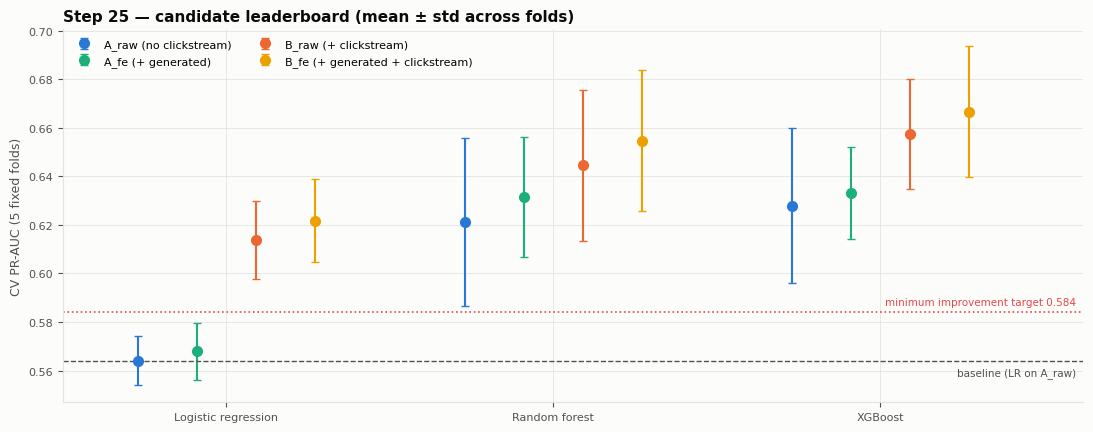

In [14]:
# Chart 1: CV PR-AUC (mean ± std over the 5 fixed folds) per model and feature set, vs baseline and target
fig, ax = plt.subplots(figsize=(11, 4.4))
offsets = {"A_raw": -0.27, "A_fe": -0.09, "B_raw": 0.09, "B_fe": 0.27}
colors = {"A_raw": SERIES[0], "A_fe": SERIES[2], "B_raw": SERIES[1], "B_fe": SERIES[3]}
labels_ = {"A_raw": "A_raw (no clickstream)", "A_fe": "A_fe (+ generated)", "B_raw": "B_raw (+ clickstream)",
           "B_fe": "B_fe (+ generated + clickstream)"}
for set_name in SETS:
    d = leaderboard[leaderboard["feature_set"] == set_name].set_index("model").loc[list(MODELS)]
    x = np.arange(len(MODELS)) + offsets[set_name]
    ax.errorbar(x, d["cv_pr_auc"], yerr=d["cv_pr_auc_std"], fmt="o", color=colors[set_name], ecolor=colors[set_name],
                elinewidth=1.5, capsize=3, markersize=7, label=labels_[set_name])
ax.axhline(BASELINE["baseline_cv_pr_auc_mean"], color=INK_2, linestyle="--", linewidth=1)
ax.axhline(TARGET, color="#e34948", linestyle=":", linewidth=1.2)
ax.set_xlim(-0.5, 2.62)
ax.text(2.6, BASELINE["baseline_cv_pr_auc_mean"] - 0.006, "baseline (LR on A_raw)", fontsize=7.5, color=INK_2, ha="right")
ax.text(2.6, TARGET + 0.003, f"minimum improvement target {TARGET:.3f}", fontsize=7.5, color="#e34948", ha="right")
ax.set_xticks(range(len(MODELS)), ["Logistic regression", "Random forest", "XGBoost"])
ax.set_ylabel("CV PR-AUC (5 fixed folds)")
ax.legend(loc="upper left", ncol=2)
ax.set_title("Step 25 — candidate leaderboard (mean ± std across folds)")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "25_1_leaderboard.png"), dpi=130, bbox_inches="tight")
plt.show()

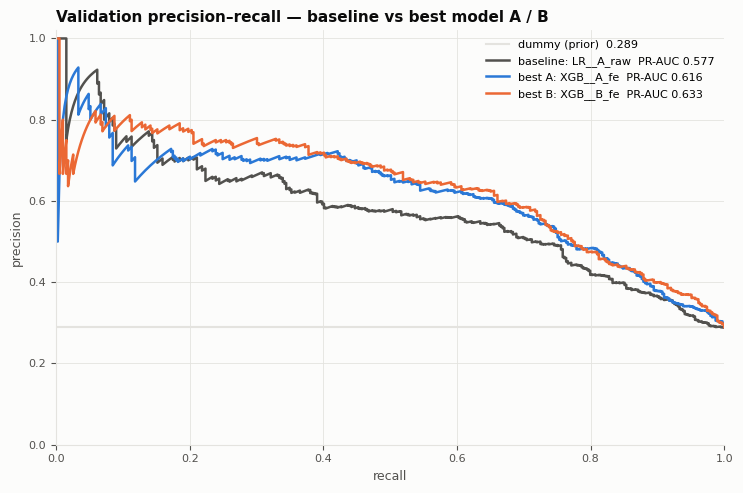

In [15]:
# Chart 2: validation precision-recall curves — baseline vs best model A (champion) vs best model B (challenger)
best_a = leaderboard[leaderboard["oot_evaluable"]].iloc[0]["candidate"]
best_b = leaderboard[~leaderboard["oot_evaluable"]].iloc[0]["candidate"]
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.axhline(y_val.mean(), color=GRID, linewidth=1.5, label=f"dummy (prior)  {y_val.mean():.3f}")
for color, key, role in [(INK_2, "LR__A_raw", "baseline"), (SERIES[0], best_a, "best A"), (SERIES[1], best_b, "best B")]:
    prec, rec, _ = precision_recall_curve(y_val, cand_val[key])
    ax.plot(rec, prec, color=color, linewidth=1.8,
            label=f"{role}: {key}  PR-AUC {average_precision_score(y_val, cand_val[key]):.3f}")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(loc="upper right")
ax.set_title("Validation precision–recall — baseline vs best model A / B")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "25_2_validation_pr_curves.png"), dpi=130, bbox_inches="tight")
plt.show()

In [16]:
# Run configuration (reproducibility) + shortlist for steps 26-30 (from CV / validation only)
run_config = {
    "step": 25, "version": MD_VERSION, "seed": SEED, "folds": "cv_folds.csv (saved in step 24)",
    "metric_contract": "metric_contract.yaml", "feature_lists": "filtered_features.json (step 23)",
    "preprocessing": "fe.build_preprocessor, refitted inside every fold",
    "models": {"LR": "LogisticRegression(max_iter=5000, C=1.0)",
               "RF": "RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features='sqrt')",
               "XGB": "XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, "
                      "colsample_bytree=0.8, tree_method='hist')"},
    "class_weighting": "none (decided in step 26)", "tuning": "none (step 29)",
    "versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "numpy": np.__version__,
                 "pandas": pd.__version__},
    "created_ts": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
}
with open(os.path.join(MD_DIR, "run_config.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(run_config, f, sort_keys=False)

a_only = leaderboard[leaderboard["oot_evaluable"]]
shortlist = pd.concat([
    a_only.head(1).assign(role="champion candidate (best model A; OOT-evaluable)"),
    leaderboard[~leaderboard["oot_evaluable"]].head(1).assign(role="challenger (best model B; in-time only)"),
    leaderboard[leaderboard["candidate"] == "LR__A_raw"].assign(role="baseline"),
])[["role", "candidate", "cv_pr_auc", "cv_pr_auc_std", "delta_cv_pr_auc_vs_baseline", "meets_minimum_improvement",
    "val_pr_auc"]]
shortlist.to_csv(os.path.join(MD_DIR, "shortlist.csv"), index=False)
shortlist.style.hide(axis="index").format({"cv_pr_auc": "{:.4f}", "cv_pr_auc_std": "{:.4f}",
                                          "delta_cv_pr_auc_vs_baseline": "{:+.4f}", "val_pr_auc": "{:.4f}"})

role,candidate,cv_pr_auc,cv_pr_auc_std,delta_cv_pr_auc_vs_baseline,meets_minimum_improvement,val_pr_auc
champion candidate (best model A; OOT-evaluable),XGB__A_fe,0.6331,0.0190,+0.0692,True,0.6163
challenger (best model B; in-time only),XGB__B_fe,0.6666,0.0270,+0.1027,True,0.6331
baseline,LR__A_raw,0.5640,0.0101,+0.0000,False,0.5772


---

## Step 26 — Handle class imbalance

**Question:** does weighting the minority class (defaulters) improve the shortlisted models on the fixed folds?

| Weight on defaulters | Value (per training fold) | Meaning |
|---|---|---|
| `none` | 1.0 | every loan counts the same (step-25 setting) |
| `sqrt` | √(non-defaulters ÷ defaulters) ≈ 1.6 | middle option |
| `balanced` | non-defaulters ÷ defaulters ≈ 2.5 | both classes carry equal total weight |

- Applied as `sample_weight` at fit time, computed **inside each training fold** (no information from the scored rows).
- Models: shortlist from step 25 (champion candidate, challenger) + the logistic baseline.
- **Not tested:** undersampling (discards ~2,700 of 6,281 training rows) and SMOTE / oversampling (synthetic rows; little expected benefit at 29% prevalence). Recorded as not adopted.
- **Decision rule (metric contract):** adopt a weight only if it beats `none` by **≥ 0.02 CV PR-AUC and more than the fold std**. Calibration (Brier, mean predicted probability vs actual rate) is reported because weighting inflates probabilities.

In [17]:
# Class balance (train + validation only; test / OOT not used here)
balance = pd.DataFrame({p: {"loans": len(d), "defaults": int(d["label"].sum()), "default_rate": d["label"].mean(),
                            "non_default_per_default": (1 - d["label"].mean()) / d["label"].mean()}
                        for p, d in [("train", train_df), ("validation", val_df)]}).T
balance.to_csv(os.path.join(MD_DIR, "class_balance.csv"))
balance.style.format({"loans": "{:,.0f}", "defaults": "{:,.0f}", "default_rate": "{:.1%}", "non_default_per_default": "{:.2f}"})

,loans,defaults,default_rate,non_default_per_default
train,"6,281","1,813",28.9%,2.46
validation,"1,346",389,28.9%,2.46


In [18]:
WEIGHTINGS = {"none": lambda r: 1.0, "sqrt": lambda r: float(np.sqrt(r)), "balanced": lambda r: float(r)}
IMB_CANDIDATES = list(shortlist["candidate"])          # champion, challenger, baseline (from step 25)

def sample_weights(y, scheme):
    y = np.asarray(y)
    w_pos = WEIGHTINGS[scheme]((y == 0).sum() / (y == 1).sum())
    return np.where(y == 1, w_pos, 1.0), w_pos

def best_f1(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return float(thr[i]), float(f1[i]), float(prec[i]), float(rec[i])

imb_rows, imb_fold_rows, imb_val = [], [], {}
for key in IMB_CANDIDATES:
    model_name, set_name = key.split("__")
    for scheme in WEIGHTINGS:
        p_oof = np.zeros(len(train_df))
        for k in range(5):
            tr, te = folds != k, folds == k
            m, feats = make_pipeline(model_name, set_name)
            sw, _ = sample_weights(train_df.loc[tr, "label"], scheme)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                m.fit(train_df.loc[tr, feats], train_df.loc[tr, "label"], model__sample_weight=sw)
            p_oof[te] = m.predict_proba(train_df.loc[te, feats])[:, 1]
            imb_fold_rows.append(dict(candidate=key, weighting=scheme, fold=k,
                                      **evaluate(train_df.loc[te, "label"], p_oof[te])))
        m, feats = make_pipeline(model_name, set_name)
        sw, w_pos = sample_weights(train_df["label"], scheme)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m.fit(train_df[feats], train_df["label"], model__sample_weight=sw)
        p_val = m.predict_proba(val_df[feats])[:, 1]
        imb_val[(key, scheme)] = p_val
        if scheme != "none":
            joblib.dump(m, os.path.join(ART_DIR, f"imbalance_{key}__{scheme}.joblib"))
        f_cv = pd.DataFrame([r for r in imb_fold_rows if r["candidate"] == key and r["weighting"] == scheme])
        v = evaluate(y_val, p_val)
        thr, f1b, pb, rb = best_f1(y_val, p_val)
        imb_rows.append(dict(candidate=key, weighting=scheme, weight_on_default=w_pos,
                             cv_pr_auc=f_cv["pr_auc"].mean(), cv_pr_auc_std=f_cv["pr_auc"].std(),
                             cv_roc_auc=f_cv["roc_auc"].mean(), cv_brier=f_cv["brier"].mean(),
                             cv_log_loss=f_cv["log_loss"].mean(),
                             val_pr_auc=v["pr_auc"], val_brier=v["brier"],
                             val_mean_predicted=float(p_val.mean()), val_actual_rate=float(y_val.mean()),
                             val_recall_at_0_5=v["recall"], val_precision_at_0_5=v["precision"],
                             val_best_f1_threshold=thr, val_best_f1=f1b,
                             val_precision_at_best_f1=pb, val_recall_at_best_f1=rb))
        print(f"{key:10s} {scheme:9s} w={w_pos:.2f} | CV PR-AUC {f_cv['pr_auc'].mean():.4f} ± {f_cv['pr_auc'].std():.4f}"
              f" | CV Brier {f_cv['brier'].mean():.4f} | val mean p {p_val.mean():.3f} (actual {y_val.mean():.3f})"
              f" | val best F1 {f1b:.3f} @ {thr:.2f}")

imb = pd.DataFrame(imb_rows)
base = imb[imb["weighting"] == "none"].set_index("candidate")
imb["delta_cv_pr_auc_vs_none"] = imb["cv_pr_auc"] - imb["candidate"].map(base["cv_pr_auc"])
imb["delta_cv_brier_vs_none"] = imb["cv_brier"] - imb["candidate"].map(base["cv_brier"])
imb["passes_minimum_improvement"] = (imb["weighting"] != "none") & \
    (imb["delta_cv_pr_auc_vs_none"] >= CONTRACT["minimum_improvement"]["absolute"]) & \
    (imb["delta_cv_pr_auc_vs_none"] > imb["candidate"].map(base["cv_pr_auc_std"]))
imb.to_csv(os.path.join(MD_DIR, "imbalance_results.csv"), index=False)
pd.DataFrame(imb_fold_rows).to_csv(os.path.join(MD_DIR, "imbalance_cv_folds_metrics.csv"), index=False)

# Sanity: 'none' reproduces step 25 exactly (same folds, same pipelines)
for key in IMB_CANDIDATES:
    assert abs(base.loc[key, "cv_pr_auc"] - leaderboard.set_index("candidate").loc[key, "cv_pr_auc"]) < 1e-9, key
print("Sanity check passed: 'none' reproduces the step-25 leaderboard")

XGB__A_fe  none      w=1.00 | CV PR-AUC 0.6331 ± 0.0190 | CV Brier 0.1504 | val mean p 0.282 (actual 0.289) | val best F1 0.632 @ 0.32


XGB__A_fe  sqrt      w=1.57 | CV PR-AUC 0.6350 ± 0.0201 | CV Brier 0.1531 | val mean p 0.334 (actual 0.289) | val best F1 0.637 @ 0.34


XGB__A_fe  balanced  w=2.46 | CV PR-AUC 0.6375 ± 0.0176 | CV Brier 0.1619 | val mean p 0.389 (actual 0.289) | val best F1 0.632 @ 0.42


XGB__B_fe  none      w=1.00 | CV PR-AUC 0.6666 ± 0.0270 | CV Brier 0.1455 | val mean p 0.279 (actual 0.289) | val best F1 0.641 @ 0.27


XGB__B_fe  sqrt      w=1.57 | CV PR-AUC 0.6715 ± 0.0285 | CV Brier 0.1464 | val mean p 0.325 (actual 0.289) | val best F1 0.652 @ 0.37


XGB__B_fe  balanced  w=2.46 | CV PR-AUC 0.6670 ± 0.0252 | CV Brier 0.1547 | val mean p 0.372 (actual 0.289) | val best F1 0.646 @ 0.39


LR__A_raw  none      w=1.00 | CV PR-AUC 0.5640 ± 0.0101 | CV Brier 0.1667 | val mean p 0.286 (actual 0.289) | val best F1 0.599 @ 0.32


LR__A_raw  sqrt      w=1.57 | CV PR-AUC 0.5605 ± 0.0112 | CV Brier 0.1737 | val mean p 0.364 (actual 0.289) | val best F1 0.595 @ 0.42


LR__A_raw  balanced  w=2.46 | CV PR-AUC 0.5562 ± 0.0122 | CV Brier 0.1956 | val mean p 0.449 (actual 0.289) | val best F1 0.593 @ 0.53
Sanity check passed: 'none' reproduces the step-25 leaderboard


### Results

In [19]:
show = ["candidate", "weighting", "weight_on_default", "cv_pr_auc", "cv_pr_auc_std", "delta_cv_pr_auc_vs_none",
        "cv_brier", "delta_cv_brier_vs_none", "val_pr_auc", "val_mean_predicted", "val_actual_rate",
        "val_recall_at_0_5", "val_best_f1_threshold", "val_best_f1", "passes_minimum_improvement"]
imb[show].style.hide(axis="index").format(
    {"weight_on_default": "{:.2f}", "cv_pr_auc": "{:.4f}", "cv_pr_auc_std": "{:.4f}", "delta_cv_pr_auc_vs_none": "{:+.4f}",
     "cv_brier": "{:.4f}", "delta_cv_brier_vs_none": "{:+.4f}", "val_pr_auc": "{:.4f}", "val_mean_predicted": "{:.3f}",
     "val_actual_rate": "{:.3f}", "val_recall_at_0_5": "{:.3f}", "val_best_f1_threshold": "{:.3f}", "val_best_f1": "{:.4f}"})

candidate,weighting,weight_on_default,cv_pr_auc,cv_pr_auc_std,delta_cv_pr_auc_vs_none,cv_brier,delta_cv_brier_vs_none,val_pr_auc,val_mean_predicted,val_actual_rate,val_recall_at_0_5,val_best_f1_threshold,val_best_f1,passes_minimum_improvement
XGB__A_fe,none,1.00,0.6331,0.0190,+0.0000,0.1504,+0.0000,0.6163,0.282,0.289,0.509,0.322,0.6318,False
XGB__A_fe,sqrt,1.57,0.6350,0.0201,+0.0018,0.1531,+0.0027,0.6025,0.334,0.289,0.576,0.342,0.6371,False
XGB__A_fe,balanced,2.46,0.6375,0.0176,+0.0044,0.1619,+0.0116,0.6089,0.389,0.289,0.658,0.420,0.6319,False
XGB__B_fe,none,1.00,0.6666,0.0270,+0.0000,0.1455,+0.0000,0.6331,0.279,0.289,0.519,0.272,0.6411,False
XGB__B_fe,sqrt,1.57,0.6715,0.0285,+0.0048,0.1464,+0.0010,0.6222,0.325,0.289,0.589,0.372,0.6518,False
XGB__B_fe,balanced,2.46,0.6670,0.0252,+0.0004,0.1547,+0.0092,0.6345,0.372,0.289,0.671,0.395,0.6464,False
LR__A_raw,none,1.00,0.5640,0.0101,+0.0000,0.1667,+0.0000,0.5772,0.286,0.289,0.391,0.324,0.5986,False
LR__A_raw,sqrt,1.57,0.5605,0.0112,-0.0034,0.1737,+0.0070,0.5753,0.364,0.289,0.555,0.422,0.5950,False
LR__A_raw,balanced,2.46,0.5562,0.0122,-0.0078,0.1956,+0.0288,0.5726,0.449,0.289,0.684,0.525,0.5932,False


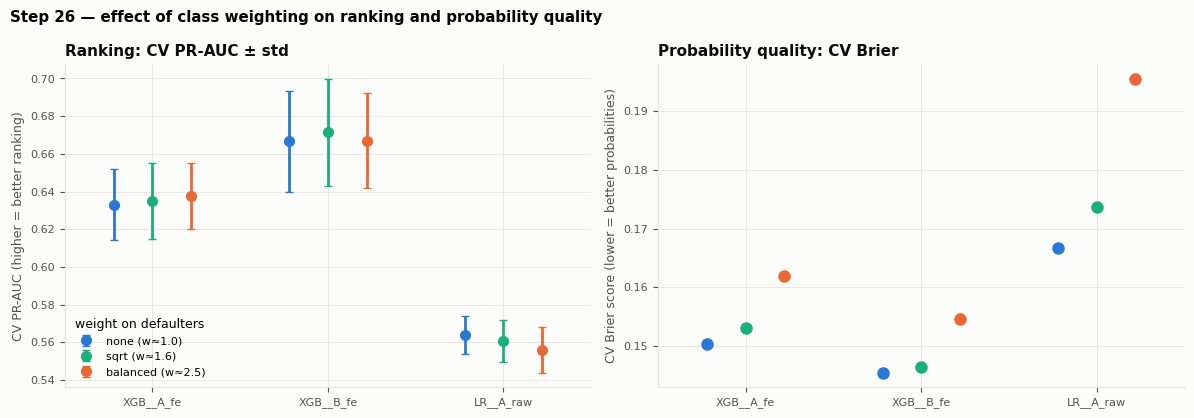

In [20]:
# Chart 1: ranking (CV PR-AUC) vs probability quality (CV Brier) per weighting
from sklearn.calibration import calibration_curve
W_COLORS = {"none": SERIES[0], "sqrt": SERIES[2], "balanced": SERIES[1]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(IMB_CANDIDATES))
for j, scheme in enumerate(WEIGHTINGS):
    d = imb[imb["weighting"] == scheme].set_index("candidate").loc[IMB_CANDIDATES]
    xo = x + (j - 1) * 0.22
    axes[0].errorbar(xo, d["cv_pr_auc"], yerr=d["cv_pr_auc_std"], fmt="o", color=W_COLORS[scheme], capsize=3,
                     markersize=7, label=f"{scheme} (w≈{d['weight_on_default'].mean():.1f})")
    axes[1].plot(xo, d["cv_brier"], "o", color=W_COLORS[scheme], markersize=8, label=scheme)
for ax in axes:
    ax.set_xticks(x, IMB_CANDIDATES)
    ax.set_xlim(-0.5, len(IMB_CANDIDATES) - 0.5)
axes[0].set_ylabel("CV PR-AUC (higher = better ranking)")
axes[0].set_title("Ranking: CV PR-AUC ± std")
axes[0].legend(loc="lower left", title="weight on defaulters")
axes[1].set_ylabel("CV Brier score (lower = better probabilities)")
axes[1].set_title("Probability quality: CV Brier")
fig.suptitle("Step 26 — effect of class weighting on ranking and probability quality", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "26_1_weighting_effect.png"), dpi=130, bbox_inches="tight")
plt.show()

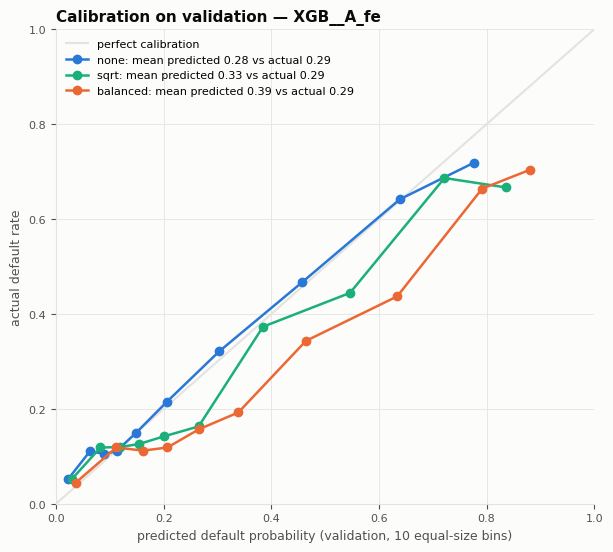

In [21]:
# Chart 2: calibration on validation for the champion candidate — does weighting push probabilities above reality?
champ = IMB_CANDIDATES[0]
fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.plot([0, 1], [0, 1], color=GRID, linewidth=1.5, label="perfect calibration")
for scheme in WEIGHTINGS:
    pv = imb_val[(champ, scheme)]
    frac, mean_p = calibration_curve(y_val, pv, n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, "o-", color=W_COLORS[scheme], linewidth=1.8, markersize=6,
            label=f"{scheme}: mean predicted {pv.mean():.2f} vs actual {y_val.mean():.2f}")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("predicted default probability (validation, 10 equal-size bins)")
ax.set_ylabel("actual default rate")
ax.legend(loc="upper left", fontsize=8)
ax.set_title(f"Calibration on validation — {champ}")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "26_2_calibration_by_weighting.png"), dpi=130, bbox_inches="tight")
plt.show()

In [22]:
# Decision (recorded; read by later steps)
adopted = {}
for key in IMB_CANDIDATES:
    passing = imb[(imb["candidate"] == key) & imb["passes_minimum_improvement"]].sort_values("cv_pr_auc", ascending=False)
    adopted[key] = passing.iloc[0]["weighting"] if len(passing) else "none"
decision = {
    "step": 26, "version": MD_VERSION,
    "class_balance": {"train_default_rate": round(float(train_df["label"].mean()), 4),
                      "non_default_per_default": round(float((1 - train_df["label"].mean()) / train_df["label"].mean()), 3),
                      "severity": "mild"},
    "tested": {"weightings": {"none": "1.0", "sqrt": "sqrt(neg/pos) per training fold", "balanced": "neg/pos per training fold"},
               "method": "sample_weight at fit, inside each CV training fold", "candidates": IMB_CANDIDATES},
    "not_tested": {"undersampling": "discards ~40% of training rows; data too small",
                   "smote_oversampling": "synthetic rows; little expected benefit at 29% prevalence; leakage risk if misapplied"},
    "rule": "adopt only if CV PR-AUC gain >= 0.02 and > fold std of 'none'",
    "results": {key: {s: {"cv_pr_auc": round(float(r["cv_pr_auc"]), 4), "cv_brier": round(float(r["cv_brier"]), 4)}
                      for s, r in imb[imb["candidate"] == key].set_index("weighting").iterrows()} for key in IMB_CANDIDATES},
    "adopted_weighting": adopted,
    "consequence": "precision/recall balance handled by the max-F1 threshold chosen on validation",
    "created_ts": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
}
with open(os.path.join(MD_DIR, "imbalance_decision.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(decision, f, sort_keys=False)
pd.DataFrame([{"candidate": k, "adopted_weighting": v} for k, v in adopted.items()])

,candidate,adopted_weighting
0,XGB__A_fe,none
1,XGB__B_fe,none
2,LR__A_raw,none


---

## Step 27 — Explainability: permutation importance and SHAP

**Shortlist carried forward (user decision, 2026-10-19):**

| Role | Model | Why |
|---|---|---|
| Champion candidate | **XGB on model A** (no clickstream) | best model A in step 25; OOT-evaluable |
| Challenger | **XGB on model B** (with clickstream) | best overall; measures what clickstream adds |
| Reference | LR__A_raw | baseline |
| Not carried forward | RF | CV PR-AUC tied with XGB (0.632 vs 0.633) but ~8× slower to score, larger, no native SHAP; recorded as an equivalent alternative |

The feature set (raw vs generated) is still open — step 28 decides it.

| Method | Question it answers | Data |
|---|---|---|
| **Permutation importance** | How much does CV PR-AUC drop when this feature is shuffled? (model reliance) | held-out part of each of the 5 fixed folds (train only) |
| **SHAP** (XGBoost built-in TreeSHAP, `pred_contribs`) | How much and in which direction does this feature push each prediction? | model fitted on all of train; global charts on train rows |

SHAP values come out per model input column (one-hot categories, missing indicators); they are **summed back to the original feature**. SHAP is in **log-odds** (the model's raw score): positive = raises default risk.

In [23]:
from sklearn.inspection import permutation_importance
import xgboost as xgb

# Shortlist rule (user decision): XGB is carried forward for model A and model B — the XGB feature set with the best
# CV PR-AUC within each (A = no clickstream, B = with clickstream). Chosen by rule, not hard-coded, so a rerun on another
# machine (e.g. Docker / Linux) cannot break if tiny numeric differences reorder the leaderboard.
xgb_lb = leaderboard[leaderboard["model"] == "XGB"]                     # leaderboard is sorted by CV PR-AUC
SHORTLIST = {"A": xgb_lb[xgb_lb["oot_evaluable"]].iloc[0]["candidate"],
             "B": xgb_lb[~xgb_lb["oot_evaluable"]].iloc[0]["candidate"]}
print("Shortlist (best XGB per model):", SHORTLIST)
with open(os.path.join(MD_DIR, "shortlist_decision.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump({
        "step": 27, "decided_by": "user (2026-10-19)",
        "carried_forward": {"champion_candidate": "XGB on model A (feature set decided in step 28)",
                            "challenger": "XGB on model B (feature set decided in step 28)",
                            "reference": "LR__A_raw baseline"},
        "not_carried_forward": {"RF": "CV PR-AUC equivalent to XGB (A_fe 0.632 vs 0.633) but ~8x slower scoring, "
                                      "larger artefact, no native SHAP; recorded as equivalent alternative",
                                "LR (other sets)": "below the tree models by ~0.04-0.06 CV PR-AUC"},
        "weighting": "none (step 26)"}, f, sort_keys=False)

GROUP_COLORS = {"financials": SERIES[0], "attributes": SERIES[1], "gold-derived": SERIES[2],
                "clickstream": SERIES[3], "OpenFE generated": "#8a5cd1"}
def group_name(feat):
    return "OpenFE generated" if feat.startswith("afe_") else ctx["group_of"](feat)

def output_to_feature(pre, feats):
    # map every transformed column of the step-18 ColumnTransformer back to its original feature
    cats = sorted([c for c in feats if c in CAT], key=len, reverse=True)
    out = []
    for name in pre.get_feature_names_out():
        part, col = name.split("__", 1)
        if part == "missing_ind":
            col = col[len("missingindicator_"):]
        elif part == "cat":
            col = next(c for c in cats if col.startswith(c + "_"))
        assert col in feats, name
        out.append(col)
    return np.array(out)

def shap_by_feature(pipe, X, feats):
    # TreeSHAP contributions (log-odds) per original feature; returns (DataFrame n x feats, bias)
    pre, model = pipe.named_steps["pre"], pipe.named_steps["model"]
    contrib = model.get_booster().predict(xgb.DMatrix(pre.transform(X[feats])), pred_contribs=True)
    owner = output_to_feature(pre, feats)
    per_feat = pd.DataFrame({f: contrib[:, :-1][:, owner == f].sum(axis=1) for f in feats}, index=X.index)
    return per_feat, contrib[:, -1]

Shortlist (best XGB per model): {'A': 'XGB__A_fe', 'B': 'XGB__B_fe'}


In [24]:
# Permutation importance on the held-out part of each fixed fold (train only)
perm_rows = []
for tag, key in SHORTLIST.items():
    model_name, set_name = key.split("__")
    for k in range(5):
        tr, te = folds != k, folds == k
        m, feats = make_pipeline(model_name, set_name)
        m.fit(train_df.loc[tr, feats], train_df.loc[tr, "label"])
        r = permutation_importance(m, train_df.loc[te, feats], train_df.loc[te, "label"], scoring="average_precision",
                                   n_repeats=5, random_state=SEED, n_jobs=1)
        perm_rows += [dict(model=tag, candidate=key, fold=k, feature=f, drop_pr_auc=r.importances_mean[i])
                      for i, f in enumerate(feats)]
perm = (pd.DataFrame(perm_rows).groupby(["model", "candidate", "feature"])["drop_pr_auc"]
        .agg(perm_mean="mean", perm_std="std").reset_index())
perm["group"] = perm["feature"].map(group_name)
perm["perm_rank"] = perm.groupby("model")["perm_mean"].rank(ascending=False, method="first").astype(int)
perm = perm.sort_values(["model", "perm_rank"]).reset_index(drop=True)
perm.to_csv(os.path.join(MD_DIR, "permutation_importance.csv"), index=False)

# SHAP on the step-25 models fitted on all of train
shap_vals, shap_bias, shap_rows = {}, {}, []
for tag, key in SHORTLIST.items():
    feats = FEATURE_SETS[key.split("__")[1]]["tree"]
    sv, bias = shap_by_feature(cand_fitted[key], train_df, feats)
    # check: contributions + bias reproduce the model's own log-odds
    p = cand_fitted[key].predict_proba(train_df[feats])[:, 1]
    assert np.allclose(1 / (1 + np.exp(-(sv.sum(axis=1).values + bias))), p, atol=1e-4)
    shap_vals[tag], shap_bias[tag] = sv, bias
    for f in feats:
        shap_rows.append(dict(model=tag, candidate=key, feature=f, group=group_name(f),
                              mean_abs_shap=float(sv[f].abs().mean())))
shap_imp = pd.DataFrame(shap_rows)
shap_imp["shap_rank"] = shap_imp.groupby("model")["mean_abs_shap"].rank(ascending=False, method="first").astype(int)
shap_imp = shap_imp.sort_values(["model", "shap_rank"]).reset_index(drop=True)
shap_imp.to_csv(os.path.join(MD_DIR, "shap_importance.csv"), index=False)
print("SHAP additivity check passed (contributions + bias = model log-odds)")
both = perm.merge(shap_imp[["model", "feature", "shap_rank"]], on=["model", "feature"])
for tag in SHORTLIST:
    b = both[both["model"] == tag]
    print(f"model {tag}: rank agreement permutation vs SHAP (Spearman) = "
          f"{b['perm_rank'].corr(b['shap_rank'], method='spearman'):.2f}")

SHAP additivity check passed (contributions + bias = model log-odds)
model A: rank agreement permutation vs SHAP (Spearman) = 0.73
model B: rank agreement permutation vs SHAP (Spearman) = 0.64


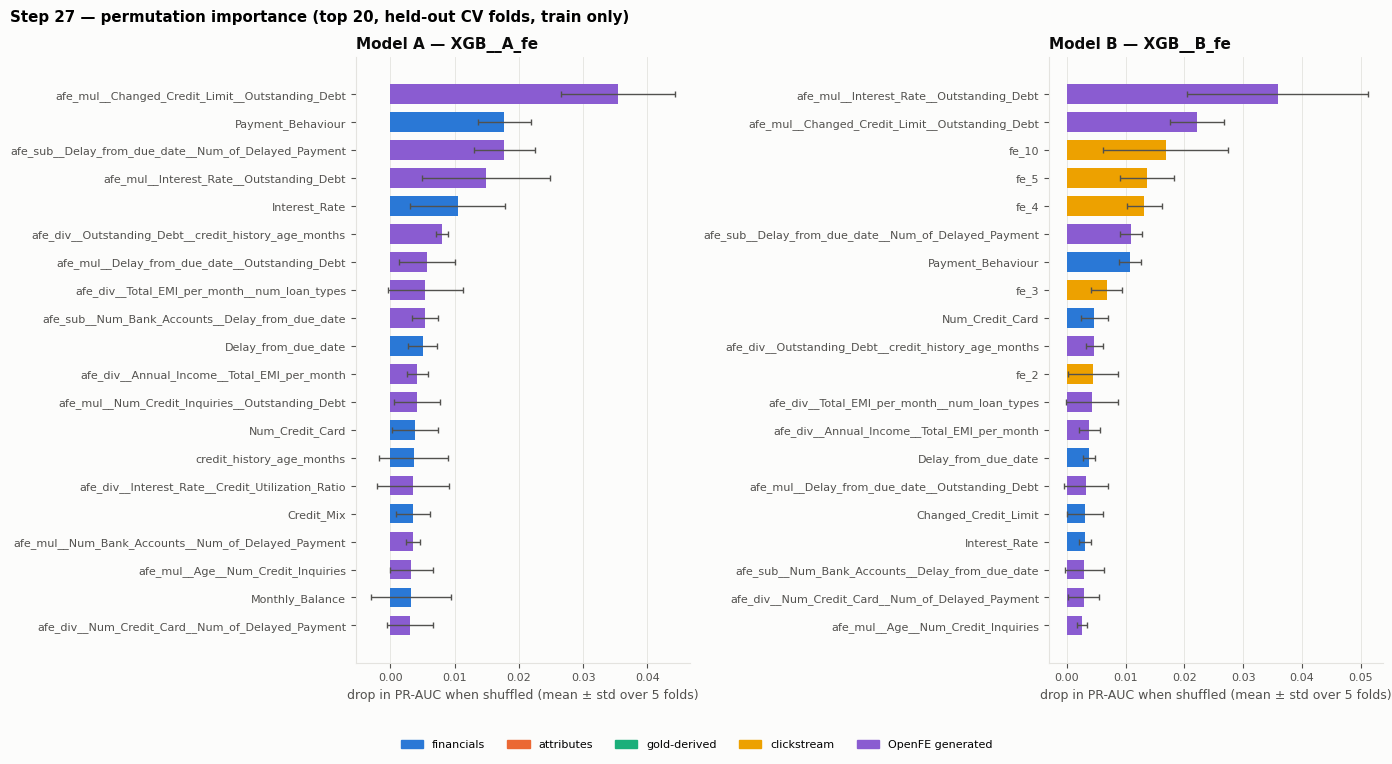

In [25]:
# Chart 1: permutation importance (top 20) — model A and model B
def importance_panel(ax, d, value, err, title, xlabel):
    d = d.head(20).iloc[::-1]
    ax.barh(d["feature"], d[value], xerr=d[err] if err else None, color=[GROUP_COLORS[g] for g in d["group"]],
            height=0.7, error_kw=dict(ecolor=INK_2, elinewidth=1, capsize=2))
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)

def group_legend(fig):
    from matplotlib.patches import Patch
    fig.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLORS.items()], loc="lower center", ncol=5,
               frameon=False, bbox_to_anchor=(0.5, -0.02))

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
for ax, tag in zip(axes, SHORTLIST):
    importance_panel(ax, perm[perm["model"] == tag], "perm_mean", "perm_std", f"Model {tag} — {SHORTLIST[tag]}",
                     "drop in PR-AUC when shuffled (mean ± std over 5 folds)")
group_legend(fig)
fig.suptitle("Step 27 — permutation importance (top 20, held-out CV folds, train only)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(os.path.join(CHART_DIR, "27_1_permutation_importance.png"), dpi=130, bbox_inches="tight")
plt.show()

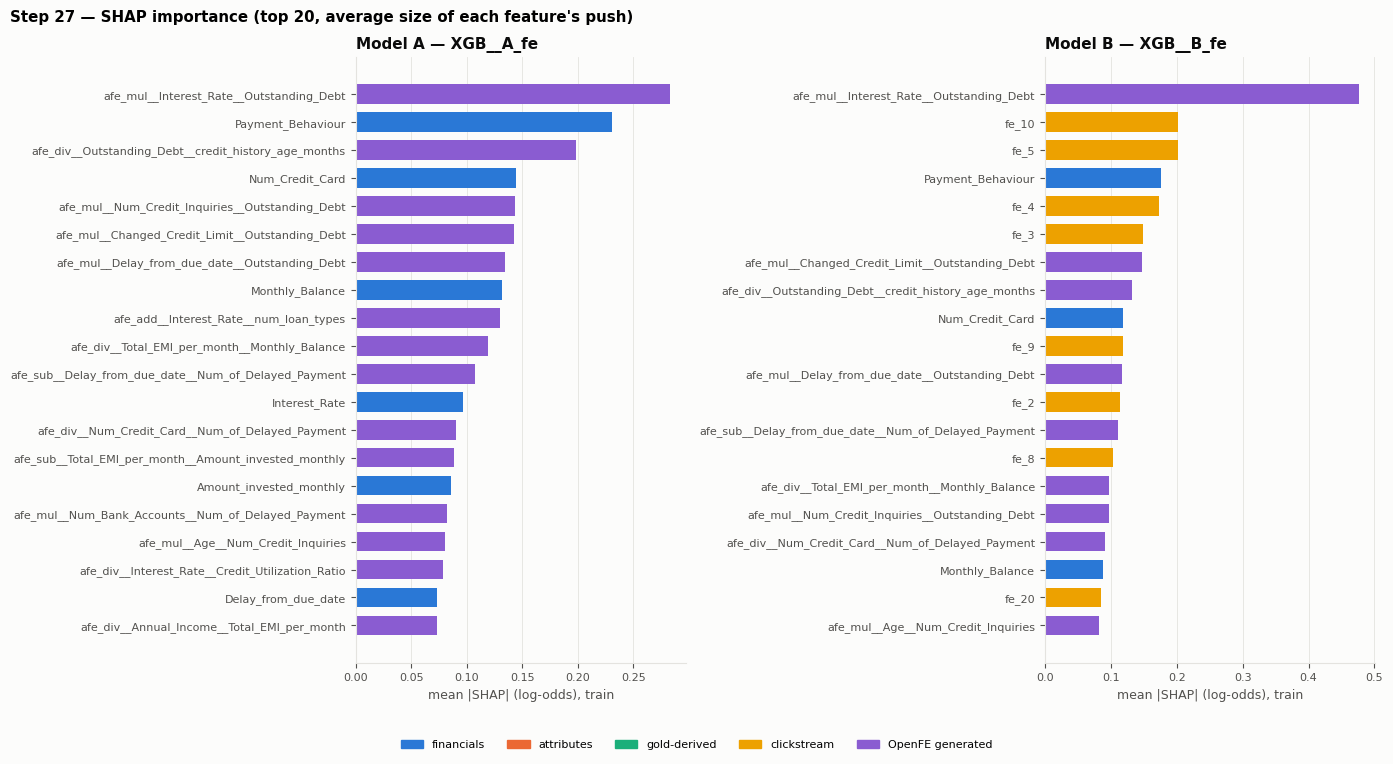

In [26]:
# Chart 2: SHAP importance (mean |SHAP|, top 20) — model A and model B
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
for ax, tag in zip(axes, SHORTLIST):
    importance_panel(ax, shap_imp[shap_imp["model"] == tag], "mean_abs_shap", None, f"Model {tag} — {SHORTLIST[tag]}",
                     "mean |SHAP| (log-odds), train")
group_legend(fig)
fig.suptitle("Step 27 — SHAP importance (top 20, average size of each feature's push)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(os.path.join(CHART_DIR, "27_2_shap_importance.png"), dpi=130, bbox_inches="tight")
plt.show()

### Feature importance table (SHAP and permutation, top 20 per model)

In [27]:
imp_table = (shap_imp.merge(perm[["model", "feature", "perm_mean", "perm_std", "perm_rank"]], on=["model", "feature"])
             .assign(shap_share=lambda d: d["mean_abs_shap"] / d.groupby("model")["mean_abs_shap"].transform("sum")))
imp_table = imp_table[["model", "shap_rank", "feature", "group", "mean_abs_shap", "shap_share", "perm_rank", "perm_mean",
                       "perm_std"]].sort_values(["model", "shap_rank"])
imp_table.to_csv(os.path.join(MD_DIR, "feature_importance_table.csv"), index=False)
fmt = {"mean_abs_shap": "{:.3f}", "shap_share": "{:.1%}", "perm_mean": "{:.4f}", "perm_std": "{:.4f}"}
for tag in SHORTLIST:
    display(imp_table[imp_table["model"] == tag].head(20).drop(columns="model").style.hide(axis="index").format(fmt)
            .set_caption(f"Model {tag} — {SHORTLIST[tag]}: top 20 by SHAP (mean |SHAP| in log-odds; share of total; "
                         f"permutation = drop in CV PR-AUC when shuffled)"))

shap_rank,feature,group,mean_abs_shap,shap_share,perm_rank,perm_mean,perm_std
1,afe_mul__Interest_Rate__Outstanding_Debt,OpenFE generated,0.283,7.9%,4,0.0149,0.0100
2,Payment_Behaviour,financials,0.231,6.5%,2,0.0178,0.0041
3,afe_div__Outstanding_Debt__credit_history_age_months,OpenFE generated,0.198,5.5%,6,0.0080,0.0010
4,Num_Credit_Card,financials,0.144,4.0%,13,0.0038,0.0036
5,afe_mul__Num_Credit_Inquiries__Outstanding_Debt,OpenFE generated,0.144,4.0%,12,0.0041,0.0036
6,afe_mul__Changed_Credit_Limit__Outstanding_Debt,OpenFE generated,0.143,4.0%,1,0.0354,0.0088
7,afe_mul__Delay_from_due_date__Outstanding_Debt,OpenFE generated,0.135,3.8%,7,0.0058,0.0044
8,Monthly_Balance,financials,0.132,3.7%,19,0.0032,0.0062
9,afe_add__Interest_Rate__num_loan_types,OpenFE generated,0.130,3.6%,22,0.0023,0.0028
10,afe_div__Total_EMI_per_month__Monthly_Balance,OpenFE generated,0.119,3.3%,23,0.0022,0.0037


shap_rank,feature,group,mean_abs_shap,shap_share,perm_rank,perm_mean,perm_std
1,afe_mul__Interest_Rate__Outstanding_Debt,OpenFE generated,0.477,10.2%,1,0.0359,0.0154
2,fe_10,clickstream,0.202,4.3%,3,0.0168,0.0106
3,fe_5,clickstream,0.201,4.3%,4,0.0137,0.0046
4,Payment_Behaviour,financials,0.176,3.8%,7,0.0107,0.0019
5,fe_4,clickstream,0.173,3.7%,5,0.0131,0.0030
6,fe_3,clickstream,0.148,3.2%,8,0.0068,0.0026
7,afe_mul__Changed_Credit_Limit__Outstanding_Debt,OpenFE generated,0.148,3.1%,2,0.0222,0.0046
8,afe_div__Outstanding_Debt__credit_history_age_months,OpenFE generated,0.132,2.8%,10,0.0047,0.0014
9,Num_Credit_Card,financials,0.119,2.5%,9,0.0047,0.0024
10,fe_9,clickstream,0.118,2.5%,22,0.0020,0.0027


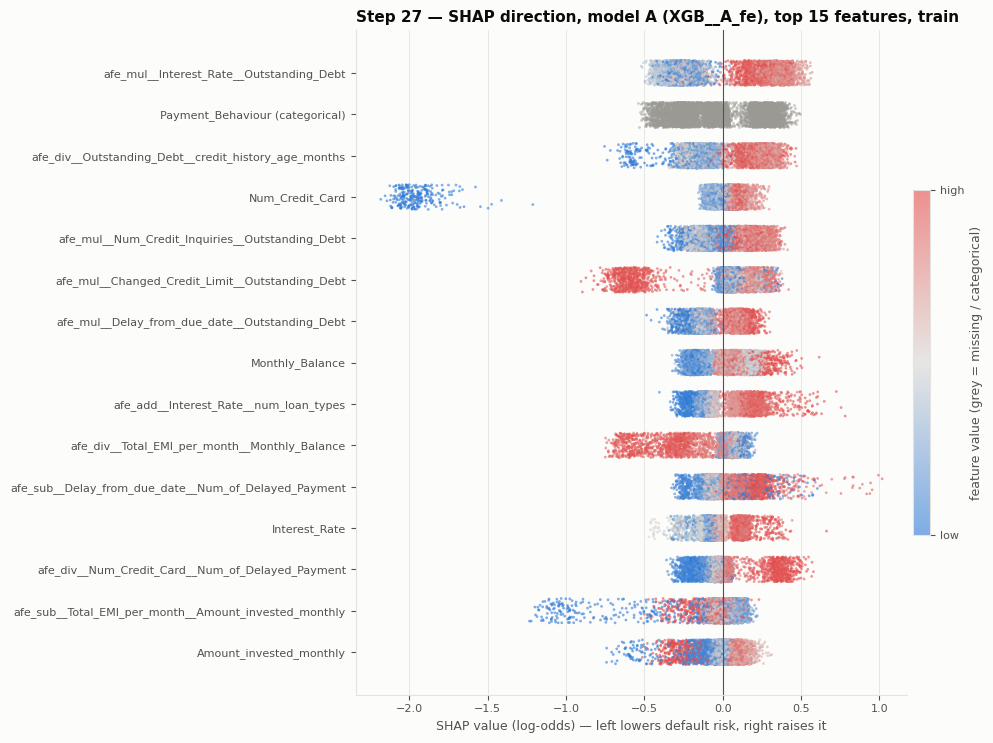

In [28]:
# Chart 3: SHAP beeswarm for the champion candidate (model A) — direction of each feature's effect
from matplotlib.colors import LinearSegmentedColormap
LOWHIGH = LinearSegmentedColormap.from_list("lowhigh", [SERIES[0], "#d9d8d4", "#e34948"])
tag = "A"; sv = shap_vals[tag]
top = shap_imp[shap_imp["model"] == tag].head(15)["feature"].tolist()
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(10, 7.5))
for i, f in enumerate(top[::-1]):
    x = sv[f].values
    raw = train_df[f]
    if f in CAT:
        colors = np.full(len(x), "#9a9994")
        c = None
    else:
        c = raw.rank(pct=True).values
    y = i + rng.uniform(-0.3, 0.3, len(x))
    if c is None:
        ax.scatter(x, y, s=4, color="#9a9994", alpha=0.5, linewidths=0)
    else:
        nan = np.isnan(c)
        ax.scatter(x[nan], y[nan], s=4, color="#9a9994", alpha=0.5, linewidths=0)
        sc = ax.scatter(x[~nan], y[~nan], s=4, c=c[~nan], cmap=LOWHIGH, vmin=0, vmax=1, alpha=0.6, linewidths=0)
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.set_yticks(range(len(top)), [f + (" (categorical)" if f in CAT else "") for f in top[::-1]], fontsize=8)
ax.set_xlabel("SHAP value (log-odds) — left lowers default risk, right raises it")
cb = fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.01)
cb.set_ticks([0, 1], labels=["low", "high"]); cb.set_label("feature value (grey = missing / categorical)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Step 27 — SHAP direction, model A ({SHORTLIST['A']}), top 15 features, train", loc="left",
             fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "27_3_shap_beeswarm_A.png"), dpi=130, bbox_inches="tight")
plt.show()

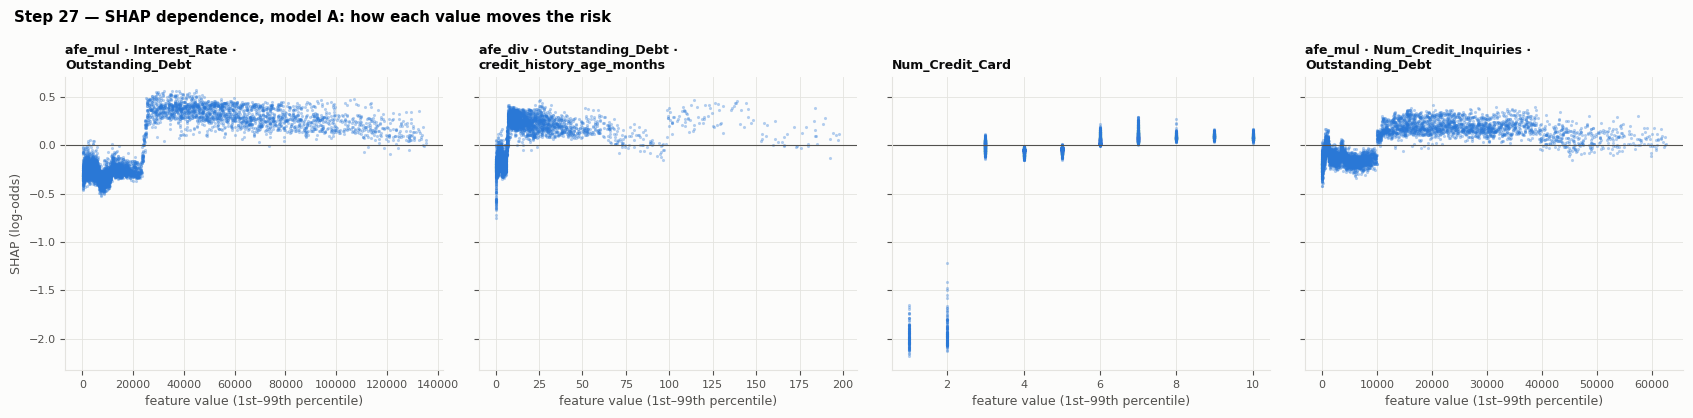

In [29]:
# Chart 4: SHAP dependence for the 4 strongest numeric features (model A)
import textwrap
top_num = [f for f in shap_imp[shap_imp["model"] == "A"]["feature"] if f not in CAT and f not in BINARY][:4]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, f in zip(axes, top_num):
    x = train_df[f]
    lo, hi = np.nanpercentile(x, [1, 99])
    keep = x.between(lo, hi)
    ax.scatter(x[keep], shap_vals["A"].loc[keep, f], s=5, alpha=0.35, color=SERIES[0], linewidths=0)
    ax.axhline(0, color=INK_2, linewidth=0.8)
    ax.set_title(textwrap.fill(f.replace("__", " · "), 32), loc="left", fontsize=9)
    ax.set_xlabel("feature value (1st–99th percentile)")
axes[0].set_ylabel("SHAP (log-odds)")
fig.suptitle("Step 27 — SHAP dependence, model A: how each value moves the risk", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "27_4_shap_dependence_A.png"), dpi=130, bbox_inches="tight")
plt.show()

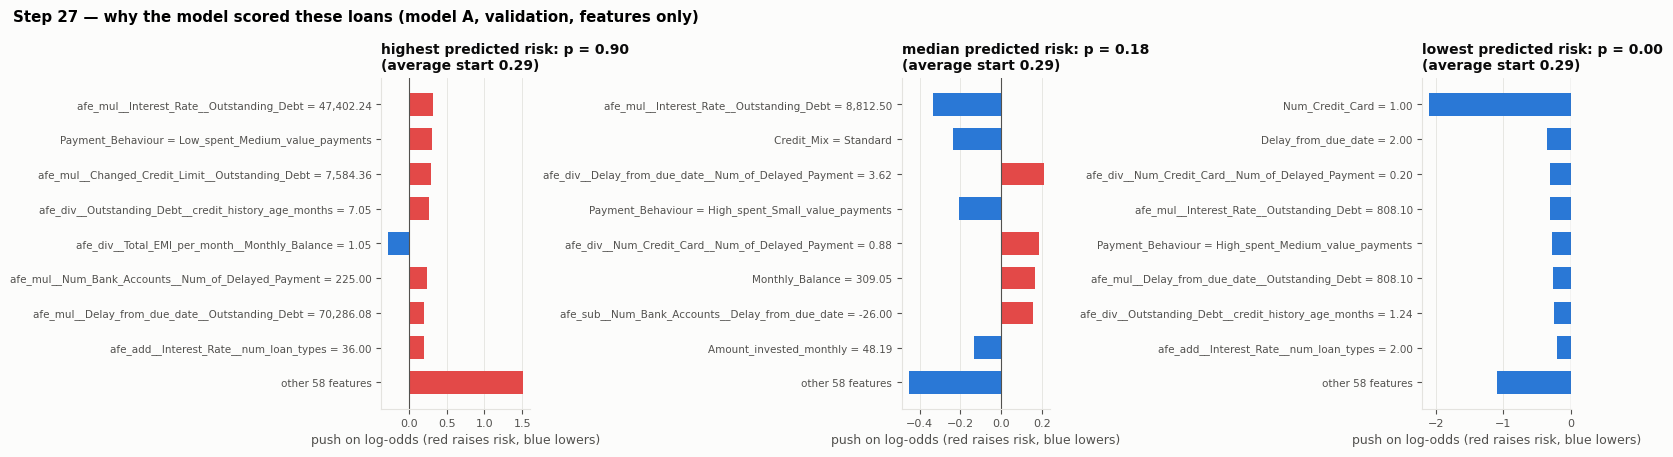

In [30]:
# Chart 5: single-loan explanations — 3 validation loans (highest, median, lowest predicted risk; labels not used)
featsA = FEATURE_SETS[SHORTLIST["A"].split("__")[1]]["tree"]
pA = cand_fitted[SHORTLIST["A"]].predict_proba(val_df[featsA])[:, 1]
order = np.argsort(pA)
picks = {"highest predicted risk": order[-1], "median predicted risk": order[len(order) // 2],
         "lowest predicted risk": order[0]}
sv_val, bias_val = shap_by_feature(cand_fitted[SHORTLIST["A"]], val_df, featsA)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (title, i) in zip(axes, picks.items()):
    s = sv_val.iloc[i]
    top8 = s.abs().sort_values(ascending=False).index[:8]
    vals = pd.concat([s[top8], pd.Series({f"other {len(s) - 8} features": s.drop(top8).sum()})]).iloc[::-1]
    def fmt(f):
        if f.startswith("other"): return f
        v = val_df.iloc[i][f]
        return f"{f} = {v if isinstance(v, str) else ('missing' if pd.isna(v) else f'{v:,.2f}')}"
    ax.barh([fmt(f) for f in vals.index], vals.values,
            color=["#e34948" if v > 0 else SERIES[0] for v in vals.values], height=0.65)
    ax.axvline(0, color=INK_2, linewidth=0.8)
    ax.tick_params(axis="y", labelsize=7.5)
    ax.set_xlabel("push on log-odds (red raises risk, blue lowers)")
    ax.set_title(f"{title}: p = {pA[i]:.2f}\n(average start {1 / (1 + np.exp(-bias_val[i])):.2f})", loc="left",
                 fontsize=10)
    ax.grid(axis="y", visible=False)
fig.suptitle("Step 27 — why the model scored these loans (model A, validation, features only)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "27_5_single_loan_explanations_A.png"), dpi=130, bbox_inches="tight")
plt.show()

In [31]:
# Sense checks: direction vs EDA, dominance, group contributions
checks = []
for tag in SHORTLIST:
    sv = shap_vals[tag]
    imp = shap_imp[shap_imp["model"] == tag]
    for f in imp.head(15)["feature"]:
        if f in CAT:
            model_dir = eda_dir = "n/a (categorical)"
        else:
            model_dir = "raises risk" if train_df[f].corr(sv[f], method="spearman") > 0 else "lowers risk"
            eda_dir = "raises risk" if train_df[f].corr(train_df["label"], method="spearman") > 0 else "lowers risk"
        checks.append(dict(model=tag, feature=f, group=group_name(f),
                           shap_rank=int(imp.set_index("feature").loc[f, "shap_rank"]),
                           share_of_total_shap=imp.set_index("feature").loc[f, "mean_abs_shap"] / imp["mean_abs_shap"].sum(),
                           higher_value_in_model=model_dir, higher_value_in_eda=eda_dir,
                           direction_consistent=(model_dir == eda_dir) if f not in CAT else None))
checks = pd.DataFrame(checks)
checks.to_csv(os.path.join(MD_DIR, "explain_sense_checks.csv"), index=False)

group_share = (shap_imp.groupby(["model", "group"])["mean_abs_shap"].sum()
               / shap_imp.groupby("model")["mean_abs_shap"].sum()).unstack("model").fillna(0)
group_share.to_csv(os.path.join(MD_DIR, "shap_group_share.csv"))
top_share = checks.groupby("model")["share_of_total_shap"].max()
print("Largest single-feature share of total |SHAP|:", top_share.round(3).to_dict(),
      "-> dominance flag (> 0.5):", bool((top_share > 0.5).any()))
print("Direction inconsistent with EDA:", checks.loc[checks["direction_consistent"] == False, ["model", "feature"]]
      .values.tolist())
display(group_share.style.format("{:.1%}").set_caption("Share of total |SHAP| by feature group"))
checks[checks["model"] == "A"].style.hide(axis="index").format({"share_of_total_shap": "{:.1%}"})

Largest single-feature share of total |SHAP|: {'A': 0.079, 'B': 0.102} -> dominance flag (> 0.5): False
Direction inconsistent with EDA: [['A', 'Monthly_Balance'], ['A', 'afe_div__Total_EMI_per_month__Monthly_Balance'], ['A', 'afe_sub__Total_EMI_per_month__Amount_invested_monthly'], ['A', 'Amount_invested_monthly'], ['B', 'afe_mul__Changed_Credit_Limit__Outstanding_Debt'], ['B', 'afe_div__Total_EMI_per_month__Monthly_Balance']]


model,A,B
group,,
OpenFE generated,58.2%,40.8%
attributes,1.8%,0.8%
clickstream,0.0%,36.3%
financials,37.4%,21.0%
gold-derived,2.6%,1.1%


model,feature,group,shap_rank,share_of_total_shap,higher_value_in_model,higher_value_in_eda,direction_consistent
A,afe_mul__Interest_Rate__Outstanding_Debt,OpenFE generated,1,7.9%,raises risk,raises risk,True
A,Payment_Behaviour,financials,2,6.5%,n/a (categorical),n/a (categorical),None
A,afe_div__Outstanding_Debt__credit_history_age_months,OpenFE generated,3,5.5%,raises risk,raises risk,True
A,Num_Credit_Card,financials,4,4.0%,raises risk,raises risk,True
A,afe_mul__Num_Credit_Inquiries__Outstanding_Debt,OpenFE generated,5,4.0%,raises risk,raises risk,True
A,afe_mul__Changed_Credit_Limit__Outstanding_Debt,OpenFE generated,6,4.0%,raises risk,raises risk,True
A,afe_mul__Delay_from_due_date__Outstanding_Debt,OpenFE generated,7,3.8%,raises risk,raises risk,True
A,Monthly_Balance,financials,8,3.7%,raises risk,lowers risk,False
A,afe_add__Interest_Rate__num_loan_types,OpenFE generated,9,3.6%,raises risk,raises risk,True
A,afe_div__Total_EMI_per_month__Monthly_Balance,OpenFE generated,10,3.3%,lowers risk,raises risk,False


---

## Step 28 — Feature reduction (one-standard-error rule)

**Rule (user decision):** among all candidate feature sets, find the best CV PR-AUC; draw a bar **one standard error** below it (SE = fold std ÷ √5); choose the **fewest features** whose CV PR-AUC is above the bar (Hastie, Tibshirani & Friedman, *Elements of Statistical Learning*, §7.10).

**Candidates per model** (same 5 fixed folds, XGB settings unchanged, no weighting):
- `raw` — the original feature set without OpenFE features (A_raw 46 / B_raw 66): *do the generated features earn their place?*
- `top-k` — the k most important features, for a grid of k from the full set down to 10.

**No selection leakage:** in each fold, features are ranked by SHAP from a model fitted **on that fold's training part only**; the held-out part never influences which features are kept. The final list for the chosen k uses the ranking from the model fitted on all of train (step 27).

In [32]:
REDUCTION_STEPS = {"A": [55, 46, 40, 35, 30, 25, 20, 15, 10], "B": [75, 66, 60, 50, 40, 30, 25, 20, 15, 10]}
N_FULL = {tag: len(FEATURE_SETS[key.split("__")[1]]["tree"]) for tag, key in SHORTLIST.items()}
REDUCTION_GRID = {tag: [N_FULL[tag]] + [k for k in REDUCTION_STEPS[tag] if k < N_FULL[tag]] for tag in SHORTLIST}
print("Reduction grid:", REDUCTION_GRID)
RAW_SET = {"A": "A_raw", "B": "B_raw"}

def fit_xgb(feats, X, y):
    _, make_model = MODELS["XGB"]
    pipe = Pipeline([("pre", fe.build_preprocessor(feats, "tree", CAT, BINARY, FLAGGED)), ("model", make_model())])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pipe.fit(X[feats], y)
    return pipe

red_rows = []
for tag, key in SHORTLIST.items():
    full = FEATURE_SETS[key.split("__")[1]]["tree"]
    raw = FEATURE_SETS[RAW_SET[tag]]["tree"]
    assert set(raw) <= set(full) and len(full) == REDUCTION_GRID[tag][0]
    for k in range(5):
        tr, te = folds != k, folds == k
        Xtr, ytr = train_df.loc[tr], train_df.loc[tr, "label"]
        # ranking from this fold's training part only
        m_full = fit_xgb(full, Xtr, ytr)
        sv_tr, _ = shap_by_feature(m_full, Xtr, full)
        ranking = sv_tr.abs().mean().sort_values(ascending=False).index.tolist()
        cands = {f"top{n}": ranking[:n] for n in REDUCTION_GRID[tag]}
        cands["raw"] = raw
        for name, feats in cands.items():
            m = m_full if name == f"top{len(full)}" else fit_xgb(feats, Xtr, ytr)
            p = m.predict_proba(train_df.loc[te, feats])[:, 1]
            red_rows.append(dict(model=tag, candidate=name, n_features=len(feats), fold=k,
                                 pr_auc=average_precision_score(train_df.loc[te, "label"], p),
                                 n_openfe=sum(f.startswith("afe_") for f in feats),
                                 n_clickstream=sum(f.startswith("fe_") for f in feats)))
red_folds = pd.DataFrame(red_rows)
red_folds.to_csv(os.path.join(MD_DIR, "reduction_cv_folds.csv"), index=False)
curve = (red_folds.groupby(["model", "candidate", "n_features"])
         .agg(cv_pr_auc=("pr_auc", "mean"), cv_pr_auc_std=("pr_auc", "std"),
              avg_openfe=("n_openfe", "mean"), avg_clickstream=("n_clickstream", "mean")).reset_index())
for tag in SHORTLIST:                                                     # full set = step 25 result
    assert np.allclose(curve.set_index(["model", "candidate"]).loc[(tag, f"top{N_FULL[tag]}"), "cv_pr_auc"],
                       leaderboard.set_index("candidate").loc[SHORTLIST[tag], "cv_pr_auc"])

# one-standard-error rule
decisions = {}
for tag in SHORTLIST:
    c = curve[curve["model"] == tag]
    best = c.loc[c["cv_pr_auc"].idxmax()]
    se = best["cv_pr_auc_std"] / np.sqrt(5)
    bar = best["cv_pr_auc"] - se
    ok = c[c["cv_pr_auc"] >= bar].sort_values(["n_features", "cv_pr_auc"], ascending=[True, False])
    chosen = ok.iloc[0]
    decisions[tag] = dict(best=best["candidate"], best_cv=float(best["cv_pr_auc"]), se=float(se), bar=float(bar),
                          chosen=chosen["candidate"], chosen_n=int(chosen["n_features"]),
                          chosen_cv=float(chosen["cv_pr_auc"]), chosen_std=float(chosen["cv_pr_auc_std"]))
    curve.loc[curve["model"] == tag, "above_1se_bar"] = curve.loc[curve["model"] == tag, "cv_pr_auc"] >= bar
    curve.loc[curve["model"] == tag, "chosen"] = curve.loc[curve["model"] == tag, "candidate"] == chosen["candidate"]
    print(f"model {tag}: best {best['candidate']} CV {best['cv_pr_auc']:.4f} ± {best['cv_pr_auc_std']:.4f}; "
          f"SE {se:.4f}; bar {bar:.4f} -> chosen {chosen['candidate']} ({int(chosen['n_features'])} features, "
          f"CV {chosen['cv_pr_auc']:.4f})")
curve = curve.sort_values(["model", "n_features"], ascending=[True, False]).reset_index(drop=True)
curve.to_csv(os.path.join(MD_DIR, "reduction_curve.csv"), index=False)
curve.style.hide(axis="index").format({"cv_pr_auc": "{:.4f}", "cv_pr_auc_std": "{:.4f}", "avg_openfe": "{:.1f}",
                                       "avg_clickstream": "{:.1f}"})

Reduction grid: {'A': [66, 55, 46, 40, 35, 30, 25, 20, 15, 10], 'B': [86, 75, 66, 60, 50, 40, 30, 25, 20, 15, 10]}


model A: best top30 CV 0.6398 ± 0.0193; SE 0.0087; bar 0.6312 -> chosen top25 (25 features, CV 0.6326)
model B: best top66 CV 0.6682 ± 0.0243; SE 0.0109; bar 0.6573 -> chosen top25 (25 features, CV 0.6597)


model,candidate,n_features,cv_pr_auc,cv_pr_auc_std,avg_openfe,avg_clickstream,above_1se_bar,chosen
A,top66,66,0.6331,0.0190,20.0,0.0,True,False
A,top55,55,0.6377,0.0166,20.0,0.0,True,False
A,raw,46,0.6280,0.0321,0.0,0.0,False,False
A,top46,46,0.6320,0.0181,20.0,0.0,True,False
A,top40,40,0.6360,0.0192,20.0,0.0,True,False
A,top35,35,0.6355,0.0131,19.4,0.0,True,False
A,top30,30,0.6398,0.0193,17.8,0.0,True,False
A,top25,25,0.6326,0.0201,16.0,0.0,True,True
A,top20,20,0.6297,0.0162,13.4,0.0,False,False
A,top15,15,0.6186,0.0116,10.4,0.0,False,False


In [33]:
# Final reduced lists (ranking from the all-train model, step 27) and validation confirmation
# USER_OVERRIDE: model A's rule choice (top25) failed validation (-0.026, bootstrap 95% CI excludes 0);
# user chose the CV-best set top30 instead (2026-10-20). Chosen after seeing validation -> validation is no longer an
# untouched check for A; the test set and OOT (step 31) are the independent confirmation.
USER_OVERRIDE = {"A": {"candidate": "top30", "decided_by": "user (2026-10-20)",
                       "reason": "rule choice top25 failed validation confirmation (val PR-AUC -0.026, bootstrap 95% CI "
                                 "excludes 0); top30 = best CV PR-AUC (0.640), above the 1-SE bar",
                       "caveat": "selected after seeing validation; independent check is test / OOT in step 31"}}

def ranked_list(tag, cand):
    if cand == "raw":
        return FEATURE_SETS[RAW_SET[tag]]["tree"]
    n = int(cand[len("top"):])
    return shap_imp[shap_imp["model"] == tag].sort_values("shap_rank")["feature"].head(n).tolist()

def val_row(tag, version, cand, pipe, fl):
    p = pipe.predict_proba(val_df[fl])[:, 1]
    v = evaluate(y_val, p)
    thr, f1b, _, _ = best_f1(y_val, p)
    cvv = curve[(curve["model"] == tag) & (curve["candidate"] == cand)]
    return dict(model=tag, version=version, candidate=cand, n_features=len(fl),
                n_openfe=sum(f.startswith("afe_") for f in fl), n_clickstream=sum(f.startswith("fe_") for f in fl),
                cv_pr_auc=float(cvv["cv_pr_auc"].iloc[0]), val_pr_auc=v["pr_auc"], val_roc_auc=v["roc_auc"],
                val_brier=v["brier"], val_best_f1=f1b)

reduced, final_choice, val_cmp = {}, {}, []
for tag, key in SHORTLIST.items():
    full = FEATURE_SETS[key.split("__")[1]]["tree"]
    rule_cand = decisions[tag]["chosen"]
    val_cmp.append(val_row(tag, "full", f"top{len(full)}", cand_fitted[key], full))
    rule_feats = ranked_list(tag, rule_cand)
    m_rule = fit_xgb(rule_feats, train_df, train_df["label"])
    val_cmp.append(val_row(tag, "1-SE rule", rule_cand, m_rule, rule_feats))
    final_cand, m_final, feats = rule_cand, m_rule, rule_feats
    if tag in USER_OVERRIDE and USER_OVERRIDE[tag]["candidate"] not in set(curve.loc[curve["model"] == tag, "candidate"]):
        print(f"WARNING: override {USER_OVERRIDE[tag]['candidate']} not in the grid for model {tag}; rule choice kept")
    elif tag in USER_OVERRIDE:
        final_cand = USER_OVERRIDE[tag]["candidate"]
        feats = ranked_list(tag, final_cand)
        m_final = fit_xgb(feats, train_df, train_df["label"])
        val_cmp.append(val_row(tag, "final (user)", final_cand, m_final, feats))
    reduced[tag], final_choice[tag] = feats, final_cand
    joblib.dump(m_final, os.path.join(ART_DIR, f"reduced_XGB__{tag}.joblib"))
val_cmp = pd.DataFrame(val_cmp)
val_cmp.to_csv(os.path.join(MD_DIR, "reduction_validation.csv"), index=False)

full_lists = {tag: FEATURE_SETS[key.split("__")[1]]["tree"] for tag, key in SHORTLIST.items()}
with open(os.path.join(MD_DIR, "reduced_features.json"), "w", encoding="utf-8") as f:
    json.dump({"step": 28, "version": MD_VERSION, "rule": "one-standard-error rule on 5-fold CV PR-AUC",
               "models": {tag: {"algorithm": "XGB", "base_set": SHORTLIST[tag].split("__")[1],
                                "rule_result": decisions[tag], "final_candidate": final_choice[tag],
                                "override": USER_OVERRIDE.get(tag), "n_features": len(reduced[tag]),
                                "features": reduced[tag],
                                "dropped": [f for f in full_lists[tag] if f not in reduced[tag]]}
                          for tag in SHORTLIST}}, f, indent=2)
print({tag: f"{final_choice[tag]} ({len(reduced[tag])} features)" for tag in SHORTLIST})
val_cmp.style.hide(axis="index").format({"cv_pr_auc": "{:.4f}", "val_pr_auc": "{:.4f}", "val_roc_auc": "{:.4f}",
                                         "val_brier": "{:.4f}", "val_best_f1": "{:.4f}"})

{'A': 'top30 (30 features)', 'B': 'top25 (25 features)'}


model,version,candidate,n_features,n_openfe,n_clickstream,cv_pr_auc,val_pr_auc,val_roc_auc,val_brier,val_best_f1
A,full,top66,66,20,0,0.6331,0.6163,0.7979,0.1545,0.6318
A,1-SE rule,top25,25,16,0,0.6326,0.5905,0.7917,0.1578,0.6178
A,final (user),top30,30,18,0,0.6398,0.6009,0.7940,0.1559,0.6213
B,full,top86,86,20,20,0.6666,0.6331,0.8091,0.1515,0.6411
B,1-SE rule,top25,25,11,10,0.6597,0.6472,0.8051,0.1515,0.6293


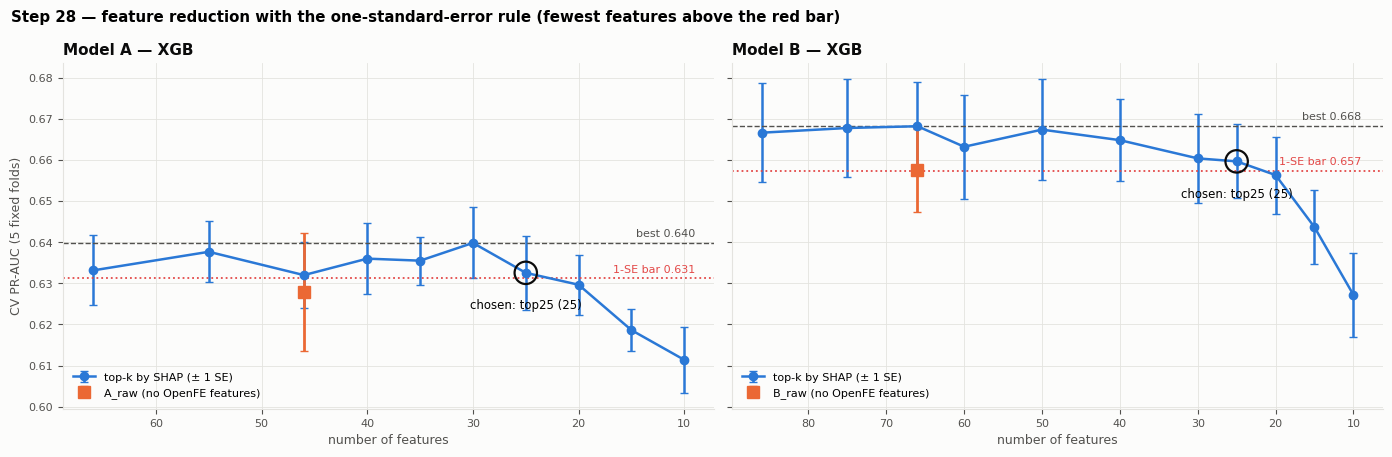

In [34]:
# Chart 1: CV PR-AUC vs number of features, with the one-standard-error bar
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, tag in zip(axes, SHORTLIST):
    c = curve[(curve["model"] == tag) & (curve["candidate"] != "raw")].sort_values("n_features")
    r = curve[(curve["model"] == tag) & (curve["candidate"] == "raw")].iloc[0]
    d = decisions[tag]
    ax.errorbar(c["n_features"], c["cv_pr_auc"], yerr=c["cv_pr_auc_std"] / np.sqrt(5), fmt="o-", color=SERIES[0],
                capsize=3, markersize=6, linewidth=1.8, label="top-k by SHAP (± 1 SE)")
    ax.errorbar([r["n_features"]], [r["cv_pr_auc"]], yerr=[r["cv_pr_auc_std"] / np.sqrt(5)], fmt="s",
                color=SERIES[1], capsize=3, markersize=8, label=f"{RAW_SET[tag]} (no OpenFE features)")
    ax.axhline(d["best_cv"], color=INK_2, linestyle="--", linewidth=1)
    ax.axhline(d["bar"], color="#e34948", linestyle=":", linewidth=1.3)
    x_txt = c["n_features"].min() - 1          # right edge (x axis is inverted)
    ax.text(x_txt, d["best_cv"] + 0.0015, f"best {d['best_cv']:.3f}", ha="right", fontsize=8, color=INK_2)
    ax.text(x_txt, d["bar"] + 0.0015, f"1-SE bar {d['bar']:.3f}", ha="right", fontsize=8, color="#e34948")
    ch = curve[(curve["model"] == tag) & (curve["chosen"] == True)].iloc[0]
    ax.scatter([ch["n_features"]], [ch["cv_pr_auc"]], s=260, facecolors="none", edgecolors=INK, linewidths=1.6, zorder=5)
    ax.annotate(f"chosen: {ch['candidate']} ({int(ch['n_features'])})", (ch["n_features"], ch["cv_pr_auc"]),
                xytext=(0, -26), textcoords="offset points", ha="center", fontsize=8.5)
    ax.set_title(f"Model {tag} — {SHORTLIST[tag].split('__')[0]}", loc="left")
    ax.set_xlabel("number of features"); ax.invert_xaxis()
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("CV PR-AUC (5 fixed folds)")
fig.suptitle("Step 28 — feature reduction with the one-standard-error rule (fewest features above the red bar)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "28_1_reduction_curve.png"), dpi=130, bbox_inches="tight")
plt.show()

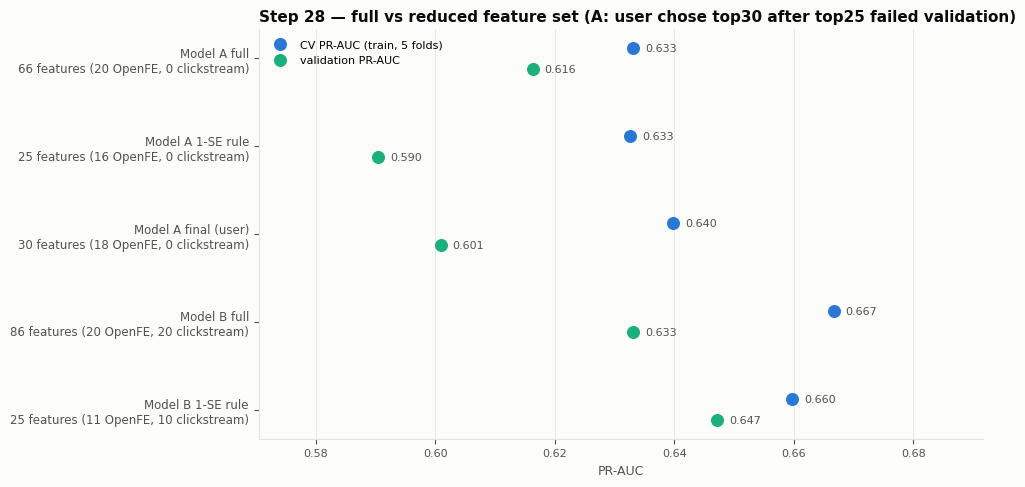

In [35]:
# Chart 2: full vs reduced — CV and validation PR-AUC, feature counts
fig, ax = plt.subplots(figsize=(10, 0.75 * len(val_cmp) + 1.2))
labels_, cvs, vals_ = [], [], []
for _, r in val_cmp.iterrows():
    labels_.append(f"Model {r['model']} {r['version']}\n{r['n_features']} features "
                   f"({r['n_openfe']} OpenFE, {r['n_clickstream']} clickstream)")
    cvs.append(r["cv_pr_auc"]); vals_.append(r["val_pr_auc"])
y = np.arange(len(labels_))[::-1]
ax.scatter(cvs, y + 0.12, s=70, color=SERIES[0], label="CV PR-AUC (train, 5 folds)", zorder=3)
ax.scatter(vals_, y - 0.12, s=70, color=SERIES[2], label="validation PR-AUC", zorder=3)
for yi, a, b in zip(y, cvs, vals_):
    ax.text(a + 0.002, yi + 0.12, f"{a:.3f}", va="center", fontsize=8, color=INK_2)
    ax.text(b + 0.002, yi - 0.12, f"{b:.3f}", va="center", fontsize=8, color=INK_2)
ax.set_yticks(y, labels_, fontsize=8.5)
ax.set_xlabel("PR-AUC")
ax.set_xlim(min(cvs + vals_) - 0.02, max(cvs + vals_) + 0.025)
ax.legend(loc="upper left", fontsize=8)
ax.grid(axis="y", visible=False)
ax.set_title("Step 28 — full vs reduced feature set (A: user chose top30 after top25 failed validation)", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "28_2_full_vs_reduced.png"), dpi=130, bbox_inches="tight")
plt.show()

---

## Step 29 — Hyperparameter tuning (Optuna)

**Scope (user decision):** tune XGB on the **chosen features only** — model A 30 features, model B 25 features (step 28). Features are fixed; only XGB settings change. No class weighting (step 26).

| Item | Setting |
|---|---|
| Search | Optuna TPE sampler, seed 42, **60 trials per model**; trial 0 = the current default settings (reference) |
| Score per trial | mean PR-AUC on the **same 5 fixed CV folds** (train only); preprocessing fitted inside each fold |
| Search space | trees 100–1000, learning rate 0.01–0.3 (log), depth 2–8, min child weight 1–20 (log), row sample 0.5–1.0, column sample 0.4–1.0, L2 0.001–10 (log), L1 1e-8–10 (log), min split gain 0–5 |
| Adoption rule (metric contract) | adopt tuned settings only if **CV PR-AUC gain ≥ 0.02 and > the default's fold std**; otherwise keep the defaults |
| Check | tuned vs default refitted on all of train and scored on validation (confirmation only — validation does not pick trials) |

*Caveat:* the best of 60 trials is chosen on the same folds it is scored on, so its CV score is slightly optimistic. The adoption rule and the validation check guard against reading too much into small gains.

In [36]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 60
DEFAULT_XGB = dict(n_estimators=400, learning_rate=0.05, max_depth=4, min_child_weight=1.0, subsample=0.8,
                   colsample_bytree=0.8, reg_lambda=1.0, reg_alpha=1e-8, gamma=0.0)   # step-25 settings (L1 ~ 0)
TUNE_FEATS = {tag: reduced[tag] for tag in SHORTLIST}                                    # step-28 final lists

def make_xgb(params):
    return XGBClassifier(**params, tree_method="hist", eval_metric="aucpr", n_jobs=-1, random_state=SEED)

def fold_matrices(feats):
    # preprocessing fitted inside each fold once; reused by every trial (same result, faster)
    mats = []
    for k in range(5):
        tr, te = folds != k, folds == k
        pre = fe.build_preprocessor(feats, "tree", CAT, BINARY, FLAGGED)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            Xtr = pre.fit_transform(train_df.loc[tr, feats])
        mats.append((Xtr, train_df.loc[tr, "label"].values, pre.transform(train_df.loc[te, feats]),
                     train_df.loc[te, "label"].values))
    return mats

def cv_params(params, mats):
    s = [average_precision_score(yte, make_xgb(params).fit(Xtr, ytr).predict_proba(Xte)[:, 1])
         for Xtr, ytr, Xte, yte in mats]
    return float(np.mean(s)), float(np.std(s, ddof=1)), s

def suggest(trial):
    return dict(n_estimators=trial.suggest_int("n_estimators", 100, 1000, step=50),
                learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                max_depth=trial.suggest_int("max_depth", 2, 8),
                min_child_weight=trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
                subsample=trial.suggest_float("subsample", 0.5, 1.0),
                colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
                reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
                reg_alpha=trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
                gamma=trial.suggest_float("gamma", 0.0, 5.0))

studies, trial_tables = {}, []
for tag in SHORTLIST:
    feats = TUNE_FEATS[tag]
    mats = fold_matrices(feats)
    # check: fold-matrix CV with default settings == pipeline CV (same folds, same preprocessing)
    pipe_scores = []
    for k in range(5):
        tr, te = folds != k, folds == k
        m = fit_xgb(feats, train_df.loc[tr], train_df.loc[tr, "label"])
        pipe_scores.append(average_precision_score(train_df.loc[te, "label"], m.predict_proba(train_df.loc[te, feats])[:, 1]))
    assert abs(np.mean(pipe_scores) - cv_params(DEFAULT_XGB, mats)[0]) < 1e-3

    def objective(trial, mats=mats):
        mean, std, scores = cv_params(suggest(trial), mats)
        trial.set_user_attr("cv_std", std)
        trial.set_user_attr("fold_scores", [round(x, 5) for x in scores])
        return mean

    t0 = time.time()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                                study_name=f"xgb_{tag}")
    study.enqueue_trial(DEFAULT_XGB)                      # trial 0 = current defaults
    study.optimize(objective, n_trials=N_TRIALS)
    studies[tag] = study
    t = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "duration"))
    t.insert(0, "model", tag)
    trial_tables.append(t)
    d0, best = study.trials[0], study.best_trial
    print(f"model {tag} ({len(feats)} features): default CV {d0.value:.4f} ± {d0.user_attrs['cv_std']:.4f} | "
          f"best trial #{best.number} CV {best.value:.4f} ± {best.user_attrs['cv_std']:.4f} | "
          f"{N_TRIALS} trials in {time.time() - t0:.0f}s")

trials_all = pd.concat(trial_tables, ignore_index=True)
trials_all["duration"] = trials_all["duration"].dt.total_seconds()
trials_all.to_csv(os.path.join(MD_DIR, "tuning_trials.csv"), index=False)

C:\Users\alber\Documents\Github\CS_611\Assignment 2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


model A (30 features): default CV 0.6402 ± 0.0155 | best trial #29 CV 0.6481 ± 0.0184 | 60 trials in 42s


model B (25 features): default CV 0.6656 ± 0.0200 | best trial #19 CV 0.6745 ± 0.0171 | 60 trials in 35s


In [37]:
# Adoption rule + validation check (tuned vs default, both refitted on all of train with the chosen features)
min_abs = CONTRACT["minimum_improvement"]["absolute"]
tuning_rows, tuned_params, final_params = [], {}, {}
for tag, study in studies.items():
    feats = TUNE_FEATS[tag]
    d0, best = study.trials[0], study.best_trial
    gain = best.value - d0.value
    adopt = bool(gain >= min_abs and gain > d0.user_attrs["cv_std"])
    tuned_params[tag] = {k: (float(v) if isinstance(v, float) else int(v)) for k, v in best.params.items()}
    final_params[tag] = tuned_params[tag] if adopt else DEFAULT_XGB
    for version, params, tr_ in [("default", DEFAULT_XGB, d0), ("tuned (best trial)", best.params, best)]:
        pipe = Pipeline([("pre", fe.build_preprocessor(feats, "tree", CAT, BINARY, FLAGGED)), ("model", make_xgb(params))])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pipe.fit(train_df[feats], train_df["label"])
        if version.startswith("tuned"):
            joblib.dump(pipe, os.path.join(ART_DIR, f"tuned_XGB__{tag}.joblib"))
        p = pipe.predict_proba(val_df[feats])[:, 1]
        v = evaluate(y_val, p)
        thr, f1b, _, _ = best_f1(y_val, p)
        tuning_rows.append(dict(model=tag, version=version, trial=tr_.number, n_features=len(feats),
                                cv_pr_auc=tr_.value, cv_pr_auc_std=tr_.user_attrs["cv_std"],
                                cv_gain_vs_default=tr_.value - d0.value, val_pr_auc=v["pr_auc"],
                                val_roc_auc=v["roc_auc"], val_brier=v["brier"], val_best_f1=f1b,
                                adopted=(adopt if version.startswith("tuned") else not adopt)))
tuning_cmp = pd.DataFrame(tuning_rows)
tuning_cmp.to_csv(os.path.join(MD_DIR, "tuning_validation.csv"), index=False)

with open(os.path.join(MD_DIR, "best_params.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump({
        "step": 29, "version": MD_VERSION, "sampler": "optuna TPESampler(seed=42)", "n_trials": N_TRIALS,
        "optuna_version": optuna.__version__, "objective": "mean PR-AUC over the 5 fixed CV folds (train)",
        "rule": f"adopt tuned only if CV gain >= {min_abs} and > default fold std",
        "models": {tag: {"features": f"step-28 final list ({len(TUNE_FEATS[tag])} features)",
                         "default_cv_pr_auc": round(studies[tag].trials[0].value, 4),
                         "best_trial": studies[tag].best_trial.number,
                         "best_cv_pr_auc": round(studies[tag].best_value, 4),
                         "cv_gain": round(studies[tag].best_value - studies[tag].trials[0].value, 4),
                         "adopted": "tuned" if final_params[tag] is not DEFAULT_XGB else "default",
                         "tuned_params": tuned_params[tag],
                         "final_params_for_step_30": {k: (float(v) if isinstance(v, float) else int(v))
                                                      for k, v in final_params[tag].items()}}
                   for tag in SHORTLIST},
        "created_ts": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")}, f, sort_keys=False)
tuning_cmp.style.hide(axis="index").format({"cv_pr_auc": "{:.4f}", "cv_pr_auc_std": "{:.4f}", "cv_gain_vs_default": "{:+.4f}",
                                            "val_pr_auc": "{:.4f}", "val_roc_auc": "{:.4f}", "val_brier": "{:.4f}",
                                            "val_best_f1": "{:.4f}"})

model,version,trial,n_features,cv_pr_auc,cv_pr_auc_std,cv_gain_vs_default,val_pr_auc,val_roc_auc,val_brier,val_best_f1,adopted
A,default,0,30,0.6402,0.0155,+0.0000,0.6009,0.7940,0.1559,0.6213,True
A,tuned (best trial),29,30,0.6481,0.0184,+0.0080,0.5946,0.7977,0.1538,0.6359,False
B,default,0,25,0.6656,0.0200,+0.0000,0.6472,0.8051,0.1515,0.6293,True
B,tuned (best trial),19,25,0.6745,0.0171,+0.0088,0.6554,0.8109,0.1493,0.6423,False


In [38]:
# Best settings found vs defaults
pd.DataFrame({**{"default": DEFAULT_XGB}, **{f"tuned model {t}": tuned_params[t] for t in SHORTLIST}}).style.format(
    lambda v: f"{v:.4g}" if isinstance(v, float) else v)

,default,tuned model A,tuned model B
n_estimators,400,500,300
learning_rate,0.05,0.05013,0.06853
max_depth,4,5,4
min_child_weight,1,1.324,1.347
subsample,0.8,0.6559,0.9182
colsample_bytree,0.8,0.6922,0.5094
reg_lambda,1,0.8908,2.662
reg_alpha,1e-08,0.7691,0.4075
gamma,0,4.692,3.066


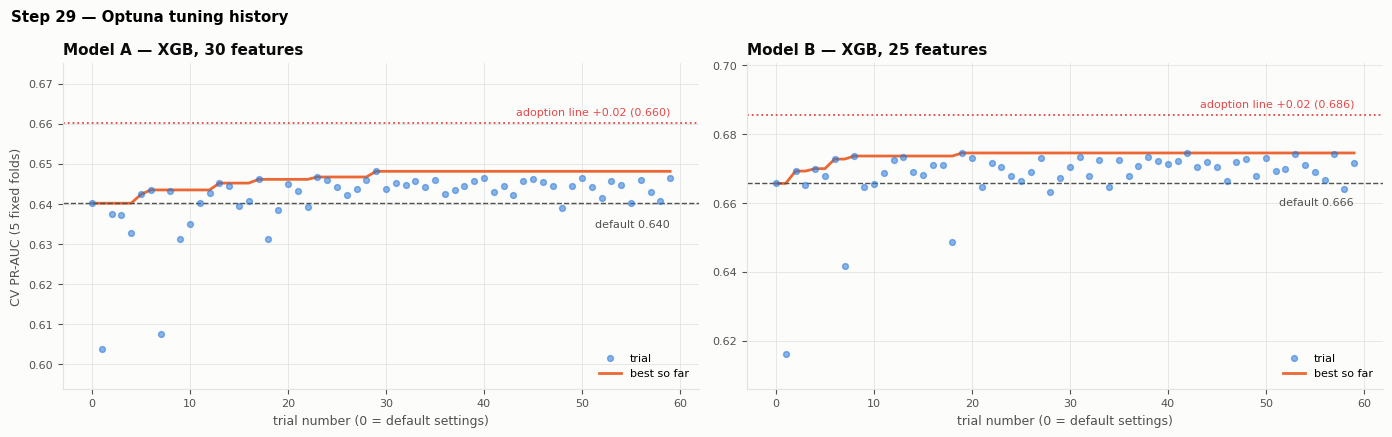

In [39]:
# Chart 1: optimisation history — every trial's CV PR-AUC, best so far, default and the +0.02 adoption line
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, (tag, study) in zip(axes, studies.items()):
    vals = np.array([t.value for t in study.trials])
    d0 = vals[0]
    ax.scatter(range(len(vals)), vals, s=18, color=SERIES[0], alpha=0.55, label="trial", zorder=3)
    ax.plot(range(len(vals)), np.maximum.accumulate(vals), color=SERIES[1], linewidth=2, label="best so far")
    ax.axhline(d0, color=INK_2, linestyle="--", linewidth=1)
    ax.axhline(d0 + min_abs, color="#e34948", linestyle=":", linewidth=1.3)
    ax.text(len(vals) - 1, d0 - 0.004, f"default {d0:.3f}", ha="right", va="top", fontsize=8, color=INK_2)
    ax.text(len(vals) - 1, d0 + min_abs + 0.002, f"adoption line +{min_abs:.2f} ({d0 + min_abs:.3f})", ha="right",
            fontsize=8, color="#e34948")
    ax.set_ylim(max(vals.min() - 0.01, d0 - 0.08), d0 + min_abs + 0.015)
    ax.set_title(f"Model {tag} — XGB, {len(TUNE_FEATS[tag])} features", loc="left")
    ax.set_xlabel("trial number (0 = default settings)")
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("CV PR-AUC (5 fixed folds)")
fig.suptitle("Step 29 — Optuna tuning history", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "29_1_tuning_history.png"), dpi=130, bbox_inches="tight")
plt.show()

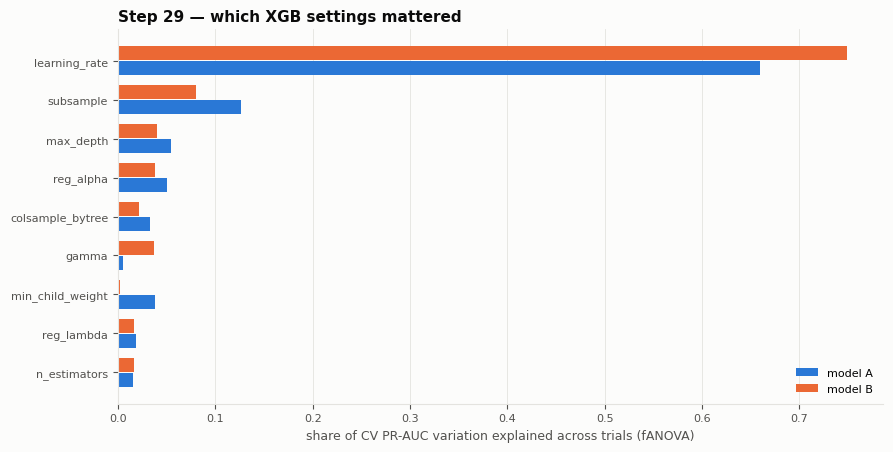

In [40]:
# Chart 2: which settings mattered (fANOVA importance of each hyperparameter for CV PR-AUC)
imp_rows = []
for tag, study in studies.items():
    imp = optuna.importance.get_param_importances(study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
    imp_rows += [dict(model=tag, param=k, importance=v) for k, v in imp.items()]
param_imp = pd.DataFrame(imp_rows)
param_imp.to_csv(os.path.join(MD_DIR, "tuning_param_importance.csv"), index=False)
order = param_imp.groupby("param")["importance"].mean().sort_values().index
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(order))
for j, tag in enumerate(SHORTLIST):
    d = param_imp[param_imp["model"] == tag].set_index("param").reindex(order)["importance"].fillna(0)
    ax.barh(y + (j - 0.5) * 0.38, d.values, height=0.36, color=SERIES[j], label=f"model {tag}")
ax.set_yticks(y, order)
ax.set_xlabel("share of CV PR-AUC variation explained across trials (fANOVA)")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
ax.set_title("Step 29 — which XGB settings mattered", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "29_2_param_importance.png"), dpi=130, bbox_inches="tight")
plt.show()

---

## Step 30 — Final model fit, operating threshold and selection sign-off

| Item | Model A — **champion** | Model B — **challenger** |
|---|---|---|
| Algorithm | XGBoost | XGBoost |
| Features | step-28 final list (30; user chose top30) | step-28 final list (25; 1-SE rule) |
| Settings | defaults (step 29: tuning gain < 0.02) — read from `best_params.yaml` | same |
| Class weighting | none (step 26) | none |
| Fit | once, on **all 6,281 training loans** | same |
| Threshold | the probability that **maximises F1 on validation** (metric contract, user decision) | same |
| Role | deployable; evaluated on test **and OOT** in step 31 | clickstream ended 2024-06 → in-time test only |

Then: SHAP re-run on the final models, a model card per model and a sign-off record (**approval by the user**). Test / OOT are used next, in step 31.

In [41]:
with open(os.path.join(MD_DIR, "best_params.yaml"), encoding="utf-8") as f:
    BEST = yaml.safe_load(f)["models"]
FINAL = {"A": {"role": "champion", "features": reduced["A"], "params": BEST["A"]["final_params_for_step_30"]},
         "B": {"role": "challenger", "features": reduced["B"], "params": BEST["B"]["final_params_for_step_30"]}}

final_models, final_val_p = {}, {}
for tag, spec in FINAL.items():
    feats = spec["features"]
    pipe = Pipeline([("pre", fe.build_preprocessor(feats, "tree", CAT, BINARY, FLAGGED)), ("model", make_xgb(spec["params"]))])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pipe.fit(train_df[feats], train_df["label"])
    final_models[tag] = pipe
    final_val_p[tag] = pipe.predict_proba(val_df[feats])[:, 1]
    # same features + same settings as the step-28 model -> identical predictions
    ref = joblib.load(os.path.join(ART_DIR, f"reduced_XGB__{tag}.joblib"))
    assert np.allclose(ref.predict_proba(val_df[feats])[:, 1], final_val_p[tag], atol=1e-6)
    print(f"model {tag} ({spec['role']}): {len(feats)} features, fitted on {len(train_df):,} training loans; "
          f"matches step-28 model")

# baseline for comparison (step 24 artefact)
base_pipe = joblib.load(os.path.join(ART_DIR, "baseline_logreg_A_raw.joblib"))
final_val_p["baseline"] = base_pipe.predict_proba(val_df[A_RAW_LINEAR])[:, 1]

model A (champion): 30 features, fitted on 6,281 training loans; matches step-28 model
model B (challenger): 25 features, fitted on 6,281 training loans; matches step-28 model


In [42]:
# Operating threshold = max F1 on validation; metrics at that threshold
CV_REF = {"A": studies["A"].trials[0].value, "B": studies["B"].trials[0].value,
          "baseline": BASELINE["baseline_cv_pr_auc_mean"]}
rows, THRESHOLD = [], {}
for tag, label_ in [("baseline", "LR__A_raw (baseline)"), ("A", "XGB model A (champion)"), ("B", "XGB model B (challenger)")]:
    p = final_val_p[tag]
    thr, f1b, _, _ = best_f1(y_val, p)
    thr = round(thr, 4)                               # stored threshold = the one evaluated
    THRESHOLD[tag] = thr
    v = evaluate(y_val, p, threshold=thr)
    rows.append(dict(model=label_, features=len(A_RAW_LINEAR) if tag == "baseline" else len(FINAL[tag]["features"]),
                     cv_pr_auc=CV_REF[tag], val_pr_auc=v["pr_auc"], val_roc_auc=v["roc_auc"], val_brier=v["brier"],
                     val_mean_predicted=float(p.mean()), threshold=thr, precision=v["precision"], recall=v["recall"],
                     f1=v["f1"], flagged_share=(v["tp"] + v["fp"]) / len(p), tp=v["tp"], fp=v["fp"], fn=v["fn"],
                     tn=v["tn"], oot_evaluable=tag != "B"))
final_val = pd.DataFrame(rows)
final_val.to_csv(os.path.join(MD_DIR, "final_validation.csv"), index=False)
print(f"Validation default rate {y_val.mean():.3f} ({int(y_val.sum())} of {len(y_val):,} loans)")
final_val.style.hide(axis="index").format(
    {"cv_pr_auc": "{:.4f}", "val_pr_auc": "{:.4f}", "val_roc_auc": "{:.4f}", "val_brier": "{:.4f}",
     "val_mean_predicted": "{:.3f}", "threshold": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}",
     "flagged_share": "{:.1%}"})

Validation default rate 0.289 (389 of 1,346 loans)


model,features,cv_pr_auc,val_pr_auc,val_roc_auc,val_brier,val_mean_predicted,threshold,precision,recall,f1,flagged_share,tp,fp,fn,tn,oot_evaluable
LR__A_raw (baseline),43,0.5640,0.5772,0.7603,0.1669,0.286,0.324,0.544,0.661,0.597,35.1%,257,215,132,742,True
XGB model A (champion),30,0.6402,0.6009,0.7940,0.1559,0.282,0.287,0.555,0.702,0.620,36.6%,273,219,116,738,True
XGB model B (challenger),25,0.6656,0.6472,0.8051,0.1515,0.279,0.308,0.587,0.679,0.629,33.4%,264,186,125,771,False


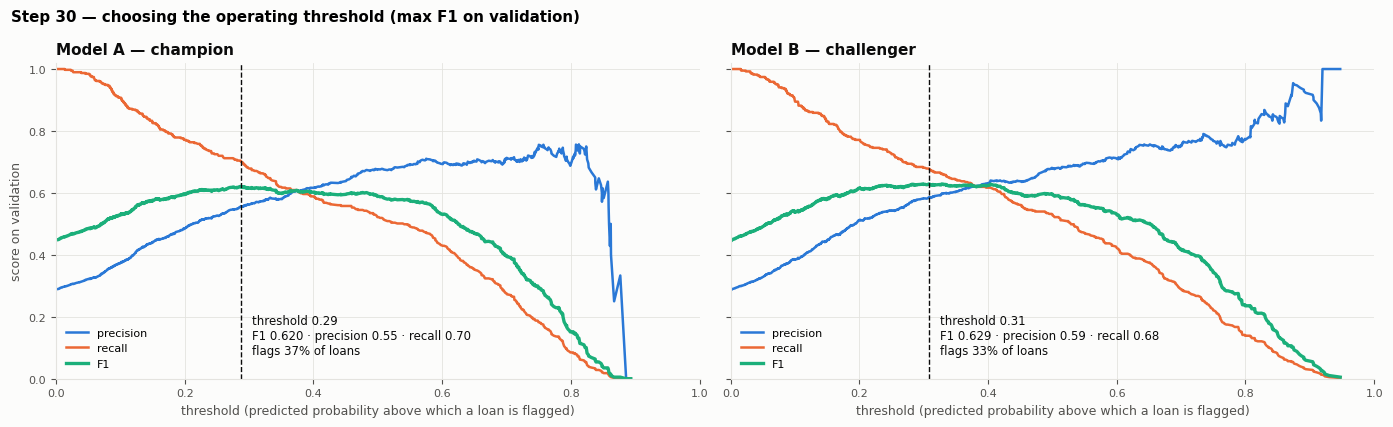

In [43]:
# Chart 1: precision, recall and F1 across thresholds (validation) — chosen threshold marked
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
for ax, tag in zip(axes, FINAL):
    p = final_val_p[tag]
    prec, rec, thr = precision_recall_curve(y_val, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    ax.plot(thr, prec[:-1], color=SERIES[0], linewidth=1.8, label="precision")
    ax.plot(thr, rec[:-1], color=SERIES[1], linewidth=1.8, label="recall")
    ax.plot(thr, f1, color=SERIES[2], linewidth=2.4, label="F1")
    t = THRESHOLD[tag]
    r = final_val[final_val["model"].str.contains(f"model {tag}")].iloc[0]
    ax.axvline(t, color=INK, linestyle="--", linewidth=1)
    ax.annotate(f"threshold {t:.2f}\nF1 {r['f1']:.3f} · precision {r['precision']:.2f} · recall {r['recall']:.2f}\n"
                f"flags {r['flagged_share']:.0%} of loans", (t, 0.08), xytext=(8, 0), textcoords="offset points",
                fontsize=8.5, color=INK)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_xlabel("threshold (predicted probability above which a loan is flagged)")
    ax.set_title(f"Model {tag} — {FINAL[tag]['role']}", loc="left")
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("score on validation")
fig.suptitle("Step 30 — choosing the operating threshold (max F1 on validation)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "30_1_threshold_selection.png"), dpi=130, bbox_inches="tight")
plt.show()

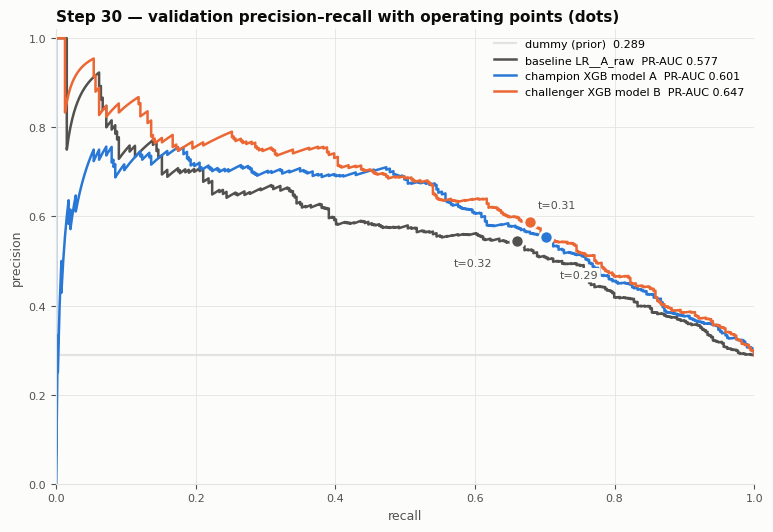

In [44]:
# Chart 2: validation precision-recall curves with each model's operating point
fig, ax = plt.subplots(figsize=(7.8, 5.4))
ax.axhline(y_val.mean(), color=GRID, linewidth=1.5, label=f"dummy (prior)  {y_val.mean():.3f}")
for color, tag, name in [(INK_2, "baseline", "baseline LR__A_raw"), (SERIES[0], "A", "champion XGB model A"),
                         (SERIES[1], "B", "challenger XGB model B")]:
    p = final_val_p[tag]
    prec, rec, _ = precision_recall_curve(y_val, p)
    ax.plot(rec, prec, color=color, linewidth=1.8, label=f"{name}  PR-AUC {average_precision_score(y_val, p):.3f}")
    v = evaluate(y_val, p, threshold=THRESHOLD[tag])
    ax.scatter([v["recall"]], [v["precision"]], s=90, color=color, edgecolors=SURFACE, linewidths=2, zorder=5)
    ax.annotate(f"t={THRESHOLD[tag]:.2f}", (v["recall"], v["precision"]),
                xytext={"baseline": (-46, -18), "A": (10, -30), "B": (6, 10)}[tag], textcoords="offset points",
                fontsize=8, color=INK_2, bbox=dict(boxstyle="round,pad=0.2", fc=SURFACE, ec="none"))
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Step 30 — validation precision–recall with operating points (dots)", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "30_2_final_pr_curves.png"), dpi=130, bbox_inches="tight")
plt.show()

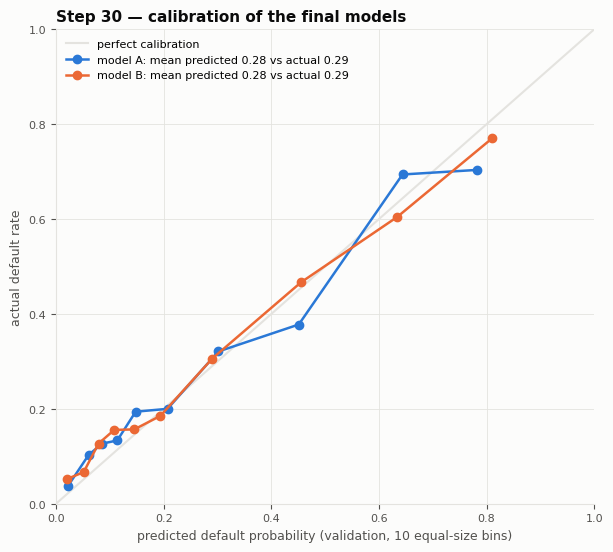

In [45]:
# Chart 3: calibration of the final models on validation
fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.plot([0, 1], [0, 1], color=GRID, linewidth=1.5, label="perfect calibration")
for color, tag in [(SERIES[0], "A"), (SERIES[1], "B")]:
    frac, mean_p = calibration_curve(y_val, final_val_p[tag], n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, "o-", color=color, linewidth=1.8, markersize=6,
            label=f"model {tag}: mean predicted {final_val_p[tag].mean():.2f} vs actual {y_val.mean():.2f}")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("predicted default probability (validation, 10 equal-size bins)")
ax.set_ylabel("actual default rate")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Step 30 — calibration of the final models", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "30_3_final_calibration.png"), dpi=130, bbox_inches="tight")
plt.show()

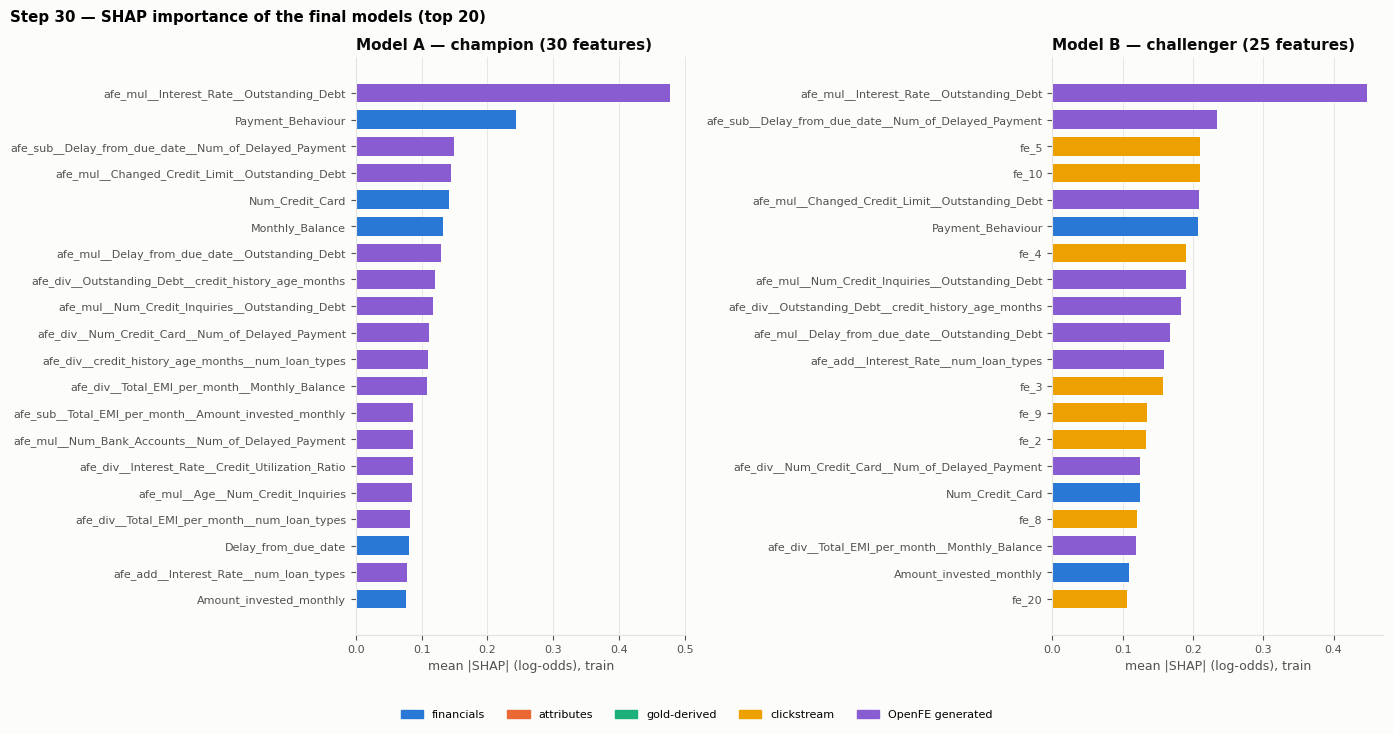

SHAP additivity check passed for both final models


model,A,B
group,,
OpenFE generated,66.1%,50.4%
clickstream,0.0%,35.9%
financials,33.9%,13.6%


In [46]:
# SHAP re-run on the final models (train rows) + chart 4
final_shap_rows = {}
for tag in FINAL:
    feats = FINAL[tag]["features"]
    sv, bias = shap_by_feature(final_models[tag], train_df, feats)
    assert np.allclose(1 / (1 + np.exp(-(sv.sum(axis=1).values + bias))),
                       final_models[tag].predict_proba(train_df[feats])[:, 1], atol=1e-4)
    imp = sv.abs().mean().sort_values(ascending=False)
    final_shap_rows[tag] = pd.DataFrame({"model": tag, "feature": imp.index, "group": [group_name(f) for f in imp.index],
                                         "mean_abs_shap": imp.values, "shap_share": imp.values / imp.sum(),
                                         "shap_rank": range(1, len(imp) + 1)})
final_shap = pd.concat(final_shap_rows.values(), ignore_index=True)
final_shap.to_csv(os.path.join(MD_DIR, "final_shap_importance.csv"), index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 7.2))
for ax, tag in zip(axes, FINAL):
    importance_panel(ax, final_shap[final_shap["model"] == tag], "mean_abs_shap", None,
                     f"Model {tag} — {FINAL[tag]['role']} ({len(FINAL[tag]['features'])} features)",
                     "mean |SHAP| (log-odds), train")
group_legend(fig)
fig.suptitle("Step 30 — SHAP importance of the final models (top 20)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(os.path.join(CHART_DIR, "30_4_final_shap_importance.png"), dpi=130, bbox_inches="tight")
plt.show()
print("SHAP additivity check passed for both final models")
display(final_shap.groupby(["model", "group"])["shap_share"].sum().unstack("model").fillna(0)
        .style.format("{:.1%}").set_caption("Share of total |SHAP| by feature group (final models)"))

In [47]:
# Save final artefacts, model cards and the sign-off record (pending user approval)
FINAL_DIR = os.path.join(MD_DIR, "final")
os.makedirs(FINAL_DIR, exist_ok=True)
cards = {}
for tag, spec in FINAL.items():
    name = f"{spec['role']}_XGB_model{tag}"
    path = os.path.join(FINAL_DIR, f"{name}.joblib")
    joblib.dump(final_models[tag], path)
    r = final_val[final_val["model"].str.contains(f"model {tag}")].iloc[0]
    cards[tag] = {
        "name": name, "role": spec["role"], "algorithm": "XGBClassifier", "xgboost_version": xgboost.__version__,
        "label": gold.LABEL_DEF, "scoring_point": "loan_start_date (as-of snapshot_date <= loan_start_date)",
        "training_rows": int(len(train_df)), "training_default_rate": round(float(train_df["label"].mean()), 4),
        "features": spec["features"], "n_features": len(spec["features"]),
        "uses_clickstream": any(f.startswith("fe_") for f in spec["features"]),
        "preprocessing": "fe.build_preprocessor(..., 'tree') — median impute + missing indicators, one-hot categoricals",
        "params": spec["params"], "class_weighting": "none",
        "operating_threshold": round(float(THRESHOLD[tag]), 4), "threshold_rule": "max F1 on validation",
        "cv_pr_auc": round(float(r["cv_pr_auc"]), 4),
        "validation": {k: round(float(r[k]), 4) for k in ["val_pr_auc", "val_roc_auc", "val_brier", "precision",
                                                           "recall", "f1", "flagged_share"]},
        "oot_evaluable": bool(r["oot_evaluable"]), "artifact": os.path.relpath(path, MD_DIR).replace("\\", "/"),
    }
    with open(os.path.join(FINAL_DIR, f"model_card_{name}.yaml"), "w", encoding="utf-8") as f:
        yaml.safe_dump(cards[tag], f, sort_keys=False)

signoff = {
    "step": 30, "version": MD_VERSION, "status": "pending approval", "approved_by": None, "approved_ts": None,
    "champion": cards["A"]["name"], "challenger": cards["B"]["name"], "baseline": "baseline_logreg_A_raw (step 24)",
    "decision_trail": {
        "24": "PR-AUC primary; min improvement +0.02 CV and > fold std; no misclassification cost; threshold = max F1 on validation",
        "25": "12 candidates (LR/RF/XGB x A_raw/A_fe/B_raw/B_fe); trees beat LR by ~0.06; clickstream +0.02-0.05",
        "26": "class weighting tested (1.0/1.57/2.46): no gain >= 0.02, worse calibration -> none",
        "27": "shortlist XGB A (champion) / XGB B (challenger); RF not carried forward; SHAP + permutation importance",
        "28": "1-SE rule; A: rule pick top25 failed validation -> user chose top30 (override recorded); B: top25",
        "29": "Optuna 60 trials/model: gains +0.008/+0.009 < 0.02 -> default settings kept",
    },
    "why_A_is_champion": "deployable (no clickstream dependency) and evaluable on OOT; B scores higher but clickstream "
                         "ended 2024-06 so B cannot score new applicants or be tested on OOT",
    "known_limitations": [
        "A features chosen after a validation check (top30 override); validation is not untouched for A",
        "threshold chosen on validation, so validation metrics at the threshold are optimistic; test/OOT give the honest view",
        "B cannot be evaluated on OOT (no clickstream after 2024-06)",
        "large SHAP effect for 1-2 credit cards (watch item); 6 direction flips vs univariate EDA (conditional effects)",
        "training outcomes up to 2024-12 overlap OOT scoring start (accepted in step 14)",
    ],
    "validation_summary": final_val.drop(columns=["tp", "fp", "fn", "tn"]).round(4).to_dict(orient="records"),
    "next": "step 31 — evaluate champion (test + OOT) and challenger (test)",
}
with open(os.path.join(FINAL_DIR, "model_selection_signoff.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(signoff, f, sort_keys=False, allow_unicode=True)

print("Saved to", FINAL_DIR)
for fn in sorted(os.listdir(FINAL_DIR)):
    print("  ", fn)

Saved to C:\Users\alber\Documents\Github\CS_611\Assignment 2\datamart\ml\model_development\v1\final
   challenger_XGB_modelB.joblib
   champion_XGB_modelA.joblib
   model_card_challenger_XGB_modelB.yaml
   model_card_champion_XGB_modelA.yaml
   model_selection_signoff.yaml
   signoff_approval.yaml


### Step 30 summary

- **Champion: XGB model A** (30 features, no clickstream) — deployable and testable on OOT.
- **Challenger: XGB model B** (25 features, with clickstream) — higher scores, but cannot score new applicants while the clickstream feed is off; in-time test only.
- Operating threshold for each = max F1 on validation; final models, model cards and the sign-off record are in `final/`.
- **Sign-off status: pending user approval** (`model_selection_signoff.yaml` → `approved_by`). Step 31 (test + OOT) runs after approval.

---

## Step 31 — Final evaluation on the held-out test set and OOT

**Final evaluation.** Test (1,347 loans, in-time 2023-01..2024-06) and OOT (3,526 loans, 2024-07..2025-01) have not been used since the split in step 14. They are used here for the signed-off models only; nothing is re-selected, re-tuned or re-thresholded after this point.

| Model | Test (in-time) | OOT (later loans) |
|---|---|---|
| Champion — XGB model A | ✓ | ✓ |
| Challenger — XGB model B | ✓ | ✗ — clickstream absent after 2024-06 (not a valid evaluation) |
| Baseline — LR__A_raw | ✓ | ✓ (reference) |

**Before evaluating:** record the approval of the step-30 sign-off.
**Reported:** PR-AUC (primary) with bootstrap 95% CI, ROC-AUC, Brier, mean predicted vs actual default rate, and precision / recall / F1 at the **step-30 thresholds** (fixed); champion vs baseline difference with paired-bootstrap CI; OOT by loan-start month; score drift (PSI train → OOT).

In [48]:
# 1. Record the approval of the step-30 sign-off (separate file, so the sign-off record stays as written)
FINAL_DIR = os.path.join(MD_DIR, "final")
APPROVAL = {"signoff_file": "final/model_selection_signoff.yaml",
            "approved_by": "albertsoh", "approved_ts": "2026-10-20",
            "how": "user instruction to proceed with step 31 after reviewing the step-30 results"}
with open(os.path.join(FINAL_DIR, "signoff_approval.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(APPROVAL, f, sort_keys=False)
print(f"Sign-off approved by {APPROVAL['approved_by']}")

# 2. Load the signed-off models from disk (not from memory) and their fixed thresholds
FINAL_MODELS = {"A": joblib.load(os.path.join(FINAL_DIR, "champion_XGB_modelA.joblib")),
                "B": joblib.load(os.path.join(FINAL_DIR, "challenger_XGB_modelB.joblib")),
                "baseline": joblib.load(os.path.join(ART_DIR, "baseline_logreg_A_raw.joblib"))}
FINAL_FEATS = {"A": FINAL["A"]["features"], "B": FINAL["B"]["features"], "baseline": A_RAW_LINEAR}
FIXED_THR = {"A": cards["A"]["operating_threshold"], "B": cards["B"]["operating_threshold"], "baseline": THRESHOLD["baseline"]}
NAMES = {"A": "champion XGB model A", "B": "challenger XGB model B", "baseline": "baseline LR__A_raw"}

# 3. Test and OOT tables
holdout, _ = build_model_table(partitions=("test", "oot"))
test_df, oot_df = holdout["test"], holdout["oot"]
print(f"test {len(test_df):,} loans (default {test_df['label'].mean():.2%}) | "
      f"OOT {len(oot_df):,} loans (default {oot_df['label'].mean():.2%})")
print("Clickstream coverage (share of loans with fe_1 present): test "
      f"{test_df['fe_1'].notna().mean():.0%}, OOT {oot_df['fe_1'].notna().mean():.0%}")

Sign-off approved by albertsoh


test 1,347 loans (default 28.88%) | OOT 3,526 loans (default 28.67%)
Clickstream coverage (share of loans with fe_1 present): test 100%, OOT 0%


In [49]:
# 4. Score and evaluate (fixed thresholds), bootstrap CIs
rng = np.random.default_rng(SEED)
N_BOOT = 1000
def boot_ci(y, p, q=None):
    # 95% CI of PR-AUC, or of the paired difference PR-AUC(p) - PR-AUC(q) when q is given
    y = np.asarray(y); n = len(y); out = []
    for _ in range(N_BOOT):
        i = rng.integers(0, n, n)
        a = average_precision_score(y[i], p[i])
        out.append(a - average_precision_score(y[i], q[i]) if q is not None else a)
    return np.percentile(out, [2.5, 97.5])

EVAL_SETS = {"validation": val_df, "test": test_df, "oot": oot_df}
holdout_p, eval_rows = {}, []
for part, d in EVAL_SETS.items():
    for tag in ["baseline", "A", "B"]:
        if tag == "B" and part == "oot":
            continue                                   # not a valid evaluation (no clickstream after 2024-06)
        p = FINAL_MODELS[tag].predict_proba(d[FINAL_FEATS[tag]])[:, 1]
        holdout_p[(part, tag)] = p
        v = evaluate(d["label"], p, threshold=FIXED_THR[tag])
        lo, hi = boot_ci(d["label"], p)
        eval_rows.append(dict(partition=part, model=NAMES[tag], loans=len(d), default_rate=d["label"].mean(),
                              pr_auc=v["pr_auc"], pr_auc_ci_low=lo, pr_auc_ci_high=hi, roc_auc=v["roc_auc"],
                              brier=v["brier"], mean_predicted=float(p.mean()), threshold=FIXED_THR[tag],
                              precision=v["precision"], recall=v["recall"], f1=v["f1"],
                              flagged_share=(v["tp"] + v["fp"]) / len(p), tp=v["tp"], fp=v["fp"], fn=v["fn"], tn=v["tn"]))
final_eval = pd.DataFrame(eval_rows)
final_eval.to_csv(os.path.join(MD_DIR, "final_evaluation.csv"), index=False)

# champion vs baseline (paired bootstrap of the PR-AUC difference) — and challenger vs champion on test
cmp_rows = []
for part in ["test", "oot"]:
    y = EVAL_SETS[part]["label"].values
    for a, b in [("A", "baseline")] + ([("B", "A")] if part == "test" else []):
        diff = average_precision_score(y, holdout_p[(part, a)]) - average_precision_score(y, holdout_p[(part, b)])
        lo, hi = boot_ci(y, holdout_p[(part, a)], holdout_p[(part, b)])
        cmp_rows.append(dict(partition=part, comparison=f"{NAMES[a]} − {NAMES[b]}", pr_auc_diff=diff,
                             ci_low=lo, ci_high=hi, significant=bool(lo > 0 or hi < 0),
                             meets_min_improvement=bool(diff >= CONTRACT["minimum_improvement"]["absolute"])))
final_cmp = pd.DataFrame(cmp_rows)
final_cmp.to_csv(os.path.join(MD_DIR, "final_comparison.csv"), index=False)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    hold_pred = pd.concat([pd.DataFrame({"loan_id": d["loan_id"], "partition": part, "label": d["label"],
                         **{f"p_{NAMES[t].split()[0]}": holdout_p.get((part, t), np.full(len(d), np.nan))
                            for t in ["baseline", "A", "B"]}})
           for part, d in EVAL_SETS.items()])
hold_pred.to_parquet(os.path.join(MD_DIR, "final_predictions_holdout.parquet"), index=False)
show_cols = ["partition", "model", "loans", "default_rate", "pr_auc", "pr_auc_ci_low", "pr_auc_ci_high", "roc_auc", "brier",
             "mean_predicted", "threshold", "precision", "recall", "f1", "flagged_share"]
display(final_eval[show_cols].style.hide(axis="index").format(
    {"default_rate": "{:.1%}", "pr_auc": "{:.3f}", "pr_auc_ci_low": "{:.3f}", "pr_auc_ci_high": "{:.3f}", "roc_auc": "{:.3f}",
     "brier": "{:.3f}", "mean_predicted": "{:.3f}", "threshold": "{:.2f}", "precision": "{:.3f}", "recall": "{:.3f}",
     "f1": "{:.3f}", "flagged_share": "{:.1%}"}))
final_cmp.style.hide(axis="index").format({"pr_auc_diff": "{:+.3f}", "ci_low": "{:+.3f}", "ci_high": "{:+.3f}"})

partition,model,loans,default_rate,pr_auc,pr_auc_ci_low,pr_auc_ci_high,roc_auc,brier,mean_predicted,threshold,precision,recall,f1,flagged_share
validation,baseline LR__A_raw,1346,28.9%,0.577,0.529,0.632,0.760,0.167,0.286,0.32,0.544,0.661,0.597,35.1%
validation,champion XGB model A,1346,28.9%,0.601,0.550,0.656,0.794,0.156,0.282,0.29,0.555,0.702,0.620,36.6%
validation,challenger XGB model B,1346,28.9%,0.647,0.597,0.695,0.805,0.151,0.279,0.31,0.587,0.679,0.629,33.4%
test,baseline LR__A_raw,1347,28.9%,0.566,0.513,0.622,0.772,0.164,0.288,0.32,0.545,0.658,0.596,34.9%
test,champion XGB model A,1347,28.9%,0.613,0.564,0.670,0.800,0.152,0.282,0.29,0.579,0.710,0.637,35.4%
test,challenger XGB model B,1347,28.9%,0.640,0.588,0.696,0.806,0.151,0.280,0.31,0.573,0.684,0.624,34.4%
oot,baseline LR__A_raw,3526,28.7%,0.542,0.510,0.575,0.762,0.168,0.288,0.32,0.538,0.648,0.588,34.5%
oot,champion XGB model A,3526,28.7%,0.619,0.587,0.656,0.807,0.152,0.279,0.29,0.575,0.699,0.631,34.9%


partition,comparison,pr_auc_diff,ci_low,ci_high,significant,meets_min_improvement
test,champion XGB model A − baseline LR__A_raw,+0.048,+0.008,+0.092,True,True
test,challenger XGB model B − champion XGB model A,+0.027,-0.007,+0.062,False,True
oot,champion XGB model A − baseline LR__A_raw,+0.077,+0.054,+0.105,True,True


In [50]:
# 5. OOT by loan-start month (champion vs baseline) + score drift (PSI train -> OOT)
manifest_dates = pd.read_csv(os.path.join(gold.SPLIT_DIR, "split_manifest.csv"), usecols=["loan_id", "loan_start_date"])
oot_m = oot_df[["loan_id", "label"]].merge(manifest_dates, on="loan_id", how="left")
assert oot_m["loan_start_date"].notna().all()
oot_m["month"] = oot_m["loan_start_date"].str[:7]
oot_m["p_A"], oot_m["p_base"] = holdout_p[("oot", "A")], holdout_p[("oot", "baseline")]
by_month = (oot_m.groupby("month")
            .apply(lambda g: pd.Series({"loans": len(g), "actual_default_rate": g["label"].mean(),
                                        "mean_predicted_A": g["p_A"].mean(),
                                        "pr_auc_A": average_precision_score(g["label"], g["p_A"]),
                                        "pr_auc_baseline": average_precision_score(g["label"], g["p_base"]),
                                        "roc_auc_A": roc_auc_score(g["label"], g["p_A"])}), include_groups=False)
            .reset_index())
by_month.to_csv(os.path.join(MD_DIR, "final_oot_by_month.csv"), index=False)

def score_psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))
p_train_A = FINAL_MODELS["A"].predict_proba(train_df[FINAL_FEATS["A"]])[:, 1]
psi_rows = [dict(model=NAMES["A"], compared="train -> " + part, psi=score_psi(p_train_A, holdout_p[(part, "A")]))
            for part in ["validation", "test", "oot"]]
psi_tbl = pd.DataFrame(psi_rows)
psi_tbl["reading"] = pd.cut(psi_tbl["psi"], [-np.inf, 0.1, 0.25, np.inf], labels=["stable", "moderate shift", "major shift"])
psi_tbl.to_csv(os.path.join(MD_DIR, "final_score_psi.csv"), index=False)
display(psi_tbl.style.hide(axis="index").format({"psi": "{:.3f}"}))
by_month.style.hide(axis="index").format({"loans": "{:,.0f}", "actual_default_rate": "{:.1%}", "mean_predicted_A": "{:.1%}",
                                          "pr_auc_A": "{:.3f}", "pr_auc_baseline": "{:.3f}", "roc_auc_A": "{:.3f}"})

model,compared,psi,reading
champion XGB model A,train -> validation,0.044,stable
champion XGB model A,train -> test,0.027,stable
champion XGB model A,train -> oot,0.025,stable


month,loans,actual_default_rate,mean_predicted_A,pr_auc_A,pr_auc_baseline,roc_auc_A
2024-07,505,30.7%,28.9%,0.647,0.557,0.808
2024-08,543,30.0%,28.3%,0.608,0.497,0.786
2024-09,493,33.1%,28.6%,0.710,0.612,0.822
2024-10,456,24.6%,26.5%,0.573,0.525,0.810
2024-11,488,28.1%,28.6%,0.627,0.554,0.827
2024-12,515,27.2%,25.4%,0.666,0.572,0.838
2025-01,526,26.8%,28.6%,0.542,0.512,0.762


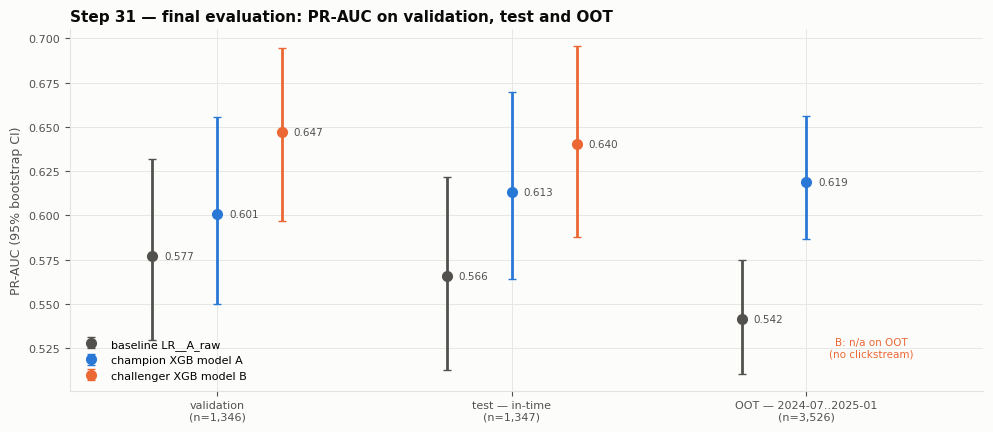

In [51]:
# Chart 1: PR-AUC with 95% CI — validation vs test vs OOT, per model
fig, ax = plt.subplots(figsize=(10, 4.4))
parts = ["validation", "test", "oot"]
M_COLORS = {"baseline LR__A_raw": INK_2, "champion XGB model A": SERIES[0], "challenger XGB model B": SERIES[1]}
for j, (name, color) in enumerate(M_COLORS.items()):
    d = final_eval[final_eval["model"] == name].set_index("partition")
    xs = [parts.index(p) + (j - 1) * 0.22 for p in d.index]
    ax.errorbar(xs, d["pr_auc"], yerr=[d["pr_auc"] - d["pr_auc_ci_low"], d["pr_auc_ci_high"] - d["pr_auc"]],
                fmt="o", color=color, capsize=3, markersize=7, label=name)
    for x, v in zip(xs, d["pr_auc"]):
        ax.text(x + 0.04, v, f"{v:.3f}", fontsize=7.5, color=INK_2, va="center")
ax.text(2 + 0.22, final_eval["pr_auc_ci_low"].min() + 0.01, "B: n/a on OOT\n(no clickstream)", fontsize=7.5,
        color=M_COLORS["challenger XGB model B"], ha="center")
ax.set_xticks(range(3), [f"validation\n(n={len(val_df):,})", f"test — in-time\n(n={len(test_df):,})",
                         f"OOT — 2024-07..2025-01\n(n={len(oot_df):,})"])
ax.set_xlim(-0.5, 2.6)
ax.set_ylabel("PR-AUC (95% bootstrap CI)")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Step 31 — final evaluation: PR-AUC on validation, test and OOT", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "31_1_final_pr_auc.png"), dpi=130, bbox_inches="tight")
plt.show()

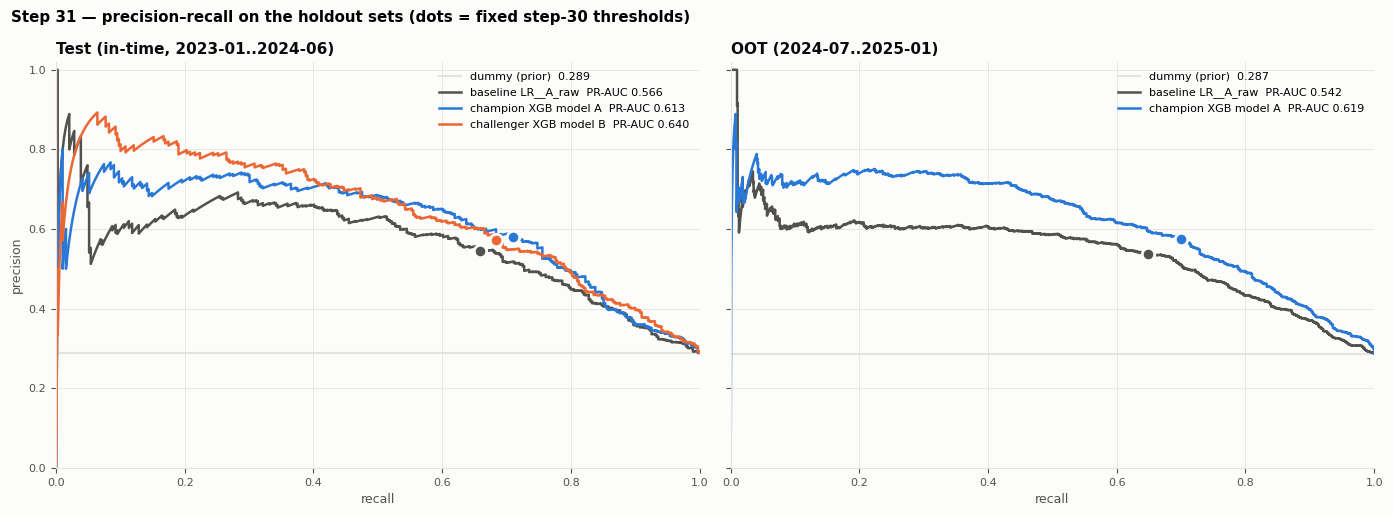

In [52]:
# Chart 2: precision-recall curves on test and OOT, operating points at the fixed thresholds
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, part in zip(axes, ["test", "oot"]):
    y = EVAL_SETS[part]["label"].values
    ax.axhline(y.mean(), color=GRID, linewidth=1.5, label=f"dummy (prior)  {y.mean():.3f}")
    for name, color in M_COLORS.items():
        tag = {v: k for k, v in NAMES.items()}[name]
        if (part, tag) not in holdout_p:
            continue
        p = holdout_p[(part, tag)]
        prec, rec, _ = precision_recall_curve(y, p)
        ax.plot(rec, prec, color=color, linewidth=1.8, label=f"{name}  PR-AUC {average_precision_score(y, p):.3f}")
        v = evaluate(y, p, threshold=FIXED_THR[tag])
        ax.scatter([v["recall"]], [v["precision"]], s=80, color=color, edgecolors=SURFACE, linewidths=2, zorder=5)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.set_xlabel("recall")
    ax.set_title({"test": "Test (in-time, 2023-01..2024-06)", "oot": "OOT (2024-07..2025-01)"}[part], loc="left")
    ax.legend(loc="upper right", fontsize=8)
axes[0].set_ylabel("precision")
fig.suptitle("Step 31 — precision–recall on the holdout sets (dots = fixed step-30 thresholds)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "31_2_holdout_pr_curves.png"), dpi=130, bbox_inches="tight")
plt.show()

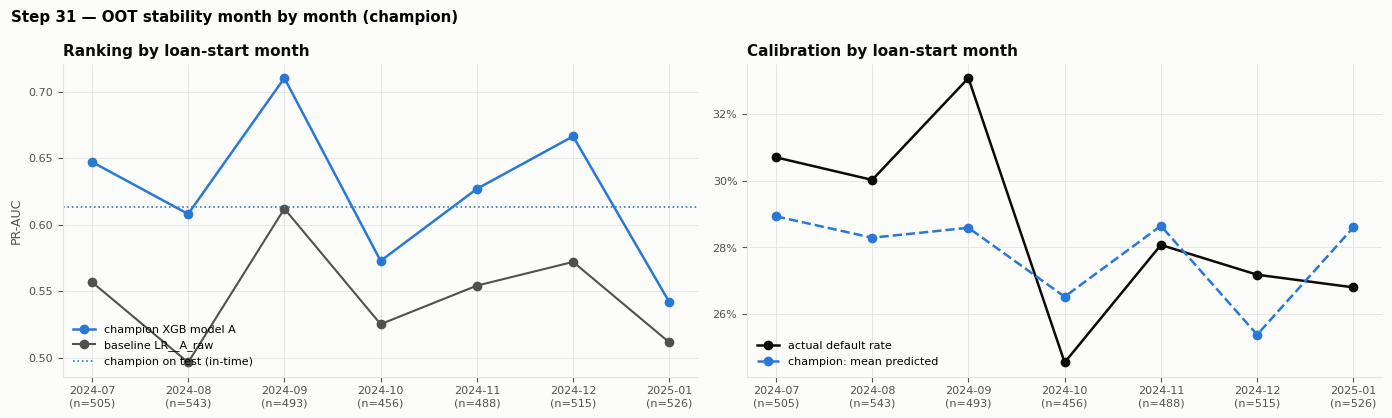

In [53]:
# Chart 3: OOT month by month — ranking (PR-AUC) and calibration (predicted vs actual default rate)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(by_month))
axes[0].plot(x, by_month["pr_auc_A"], "o-", color=SERIES[0], linewidth=1.8, label="champion XGB model A")
axes[0].plot(x, by_month["pr_auc_baseline"], "o-", color=INK_2, linewidth=1.5, label="baseline LR__A_raw")
axes[0].axhline(final_eval.query("partition == 'test' and model == 'champion XGB model A'")["pr_auc"].iloc[0],
                color=SERIES[0], linestyle=":", linewidth=1.2, label="champion on test (in-time)")
axes[0].set_ylabel("PR-AUC"); axes[0].set_title("Ranking by loan-start month", loc="left")
axes[0].legend(loc="lower left", fontsize=8)
axes[1].plot(x, by_month["actual_default_rate"], "o-", color=INK, linewidth=1.8, label="actual default rate")
axes[1].plot(x, by_month["mean_predicted_A"], "o--", color=SERIES[0], linewidth=1.8, label="champion: mean predicted")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_title("Calibration by loan-start month", loc="left")
axes[1].legend(loc="lower left", fontsize=8)
for ax in axes:
    ax.set_xticks(x, [f"{m}\n(n={n:,.0f})" for m, n in zip(by_month["month"], by_month["loans"])], fontsize=8)
fig.suptitle("Step 31 — OOT stability month by month (champion)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "31_3_oot_by_month.png"), dpi=130, bbox_inches="tight")
plt.show()

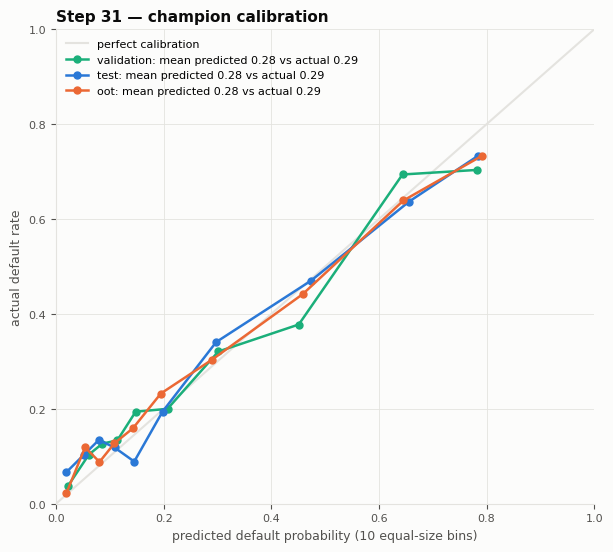

In [54]:
# Chart 4: champion calibration on validation, test and OOT
fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.plot([0, 1], [0, 1], color=GRID, linewidth=1.5, label="perfect calibration")
for part, color in [("validation", SERIES[2]), ("test", SERIES[0]), ("oot", SERIES[1])]:
    y = EVAL_SETS[part]["label"].values; p = holdout_p[(part, "A")]
    frac, mean_p = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, "o-", color=color, linewidth=1.8, markersize=5,
            label=f"{part}: mean predicted {p.mean():.2f} vs actual {y.mean():.2f}")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("predicted default probability (10 equal-size bins)"); ax.set_ylabel("actual default rate")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Step 31 — champion calibration", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "31_4_champion_calibration.png"), dpi=130, bbox_inches="tight")
plt.show()

In [55]:
# 6. Final evaluation record
ev = final_eval.set_index(["partition", "model"])
def m(part, tag, col): return round(float(ev.loc[(part, NAMES[tag]), col]), 4)
result = {
    "step": 31, "version": MD_VERSION, "evaluated_ts": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "approval": APPROVAL, "thresholds_fixed_from_step_30": {NAMES[t]: round(float(v), 4) for t, v in FIXED_THR.items()},
    "champion": {p: {k: m(p, "A", k) for k in ["pr_auc", "pr_auc_ci_low", "pr_auc_ci_high", "roc_auc", "brier",
                                                 "mean_predicted", "default_rate", "precision", "recall", "f1",
                                                 "flagged_share"]} for p in ["validation", "test", "oot"]},
    "challenger": {p: {k: m(p, "B", k) for k in ["pr_auc", "roc_auc", "brier", "precision", "recall", "f1"]}
                   for p in ["validation", "test"]},
    "baseline": {p: {k: m(p, "baseline", k) for k in ["pr_auc", "roc_auc", "brier", "f1"]} for p in ["validation", "test", "oot"]},
    "comparisons": final_cmp.round(4).to_dict(orient="records"),
    "score_psi": psi_tbl.assign(reading=psi_tbl["reading"].astype(str)).round(4).to_dict(orient="records"),
    "oot_by_month": by_month.round(4).to_dict(orient="records"),
}
with open(os.path.join(MD_DIR, "final_evaluation.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(result, f, sort_keys=False, allow_unicode=True)
print("Saved final_evaluation.yaml, final_evaluation.csv, final_comparison.csv, final_oot_by_month.csv, "
      "final_score_psi.csv, final_predictions_holdout.parquet")

Saved final_evaluation.yaml, final_evaluation.csv, final_comparison.csv, final_oot_by_month.csv, final_score_psi.csv, final_predictions_holdout.parquet


---

## Step 32 — Error and robustness analysis

**Diagnostic only:** the signed-off models, features and thresholds are **not changed** here. Findings feed monitoring (step 35) and the presentation.

| Part | Question | Data |
|---|---|---|
| A. Segment errors | Is the champion weaker or mis-calibrated for some customer groups? | OOT (main) and test |
| B. Error profiles | What do missed defaulters (FN) and false alarms (FP) look like vs correct calls? | OOT |
| C. Confident errors | Which loans were most confidently wrong, and why (SHAP)? | OOT |
| D. Input robustness | How much do noise, missing values, unseen categories and extreme values hurt? | OOT, perturbed copies |
| E. Stability | Does performance depend on the random seed or the exact threshold? | retrain with 5 seeds; threshold ± 0.1 |
| F. Challenger without clickstream | What happens to model B when its clickstream inputs are missing (as for every loan after 2024-06)? | OOT |

Segments are flagged when **n ≥ 100** and ROC-AUC is **> 0.05 below** the overall value, or the calibration gap (mean predicted − actual default rate) exceeds **± 5 points**.

In [56]:
CH, fA, thrA = FINAL_MODELS["A"], FINAL_FEATS["A"], FIXED_THR["A"]
pA = {"test": holdout_p[("test", "A")], "oot": holdout_p[("oot", "A")]}
INC_EDGES = train_df["Annual_Income"].quantile([0.2, 0.4, 0.6, 0.8]).values          # quintile edges from train
INVALID_COLS = [c for c in train_df.columns if c.endswith("_invalid")]

def segments(d):
    age = d["Age"]
    inc = d["Annual_Income"]
    cards = d["Num_Credit_Card"]
    return {
        "Credit_Mix": d["Credit_Mix"].fillna("Missing").astype(str),
        "Payment_of_Min_Amount": d["Payment_of_Min_Amount"].fillna("Missing").astype(str),
        "Payment_Behaviour": d["Payment_Behaviour"].fillna("Missing").astype(str),
        "Occupation": d["Occupation"].fillna("Missing").astype(str),
        "Age band": pd.Series(np.select([age.isna(), age < 25, age < 35, age < 45], ["Missing", "<25", "25-34", "35-44"],
                                        "45+"), index=d.index),
        "Income quintile (train edges)": pd.Series(np.where(inc.isna(), "Missing",
                                                            np.char.add("Q", (np.searchsorted(INC_EDGES, inc.fillna(0)) + 1).astype(str))),
                                                   index=d.index),
        "Num_Credit_Card": pd.Series(np.select([cards.isna(), cards <= 2, cards <= 5], ["Missing", "1-2", "3-5"], "6+"),
                                     index=d.index),
        "Input quality": pd.Series(np.where(d[fA].isna().any(axis=1) | (d[INVALID_COLS] == 1).any(axis=1),
                                            "has missing/invalid inputs", "complete inputs"), index=d.index),
    }

def seg_metrics(y, p, thr):
    y, p = np.asarray(y), np.asarray(p)
    pred = p >= thr
    tp, fp = int((pred & (y == 1)).sum()), int((pred & (y == 0)).sum())
    fn, tn = int((~pred & (y == 1)).sum()), int((~pred & (y == 0)).sum())
    both = 0 < y.sum() < len(y)
    return dict(n=len(y), defaults=int(y.sum()), default_rate=y.mean(), mean_predicted=p.mean(),
                calibration_gap=p.mean() - y.mean(), pr_auc=average_precision_score(y, p) if both else np.nan,
                roc_auc=roc_auc_score(y, p) if both else np.nan, precision=tp / max(tp + fp, 1),
                recall=tp / max(tp + fn, 1), false_alarm_rate=fp / max(fp + tn, 1), flagged_share=(tp + fp) / len(y))

seg_rows = []
for part, d in [("oot", oot_df), ("test", test_df)]:
    y, p = d["label"].values, pA[part]
    overall = seg_metrics(y, p, thrA)
    seg_rows.append(dict(partition=part, variable="(overall)", level="all", **overall))
    for var, lab in segments(d).items():
        for level in sorted(lab.unique()):
            m = lab.values == level
            seg_rows.append(dict(partition=part, variable=var, level=level, **seg_metrics(y[m], p[m], thrA)))
seg = pd.DataFrame(seg_rows)
ov = seg[seg["variable"] == "(overall)"].set_index("partition")
seg["flag_weak_ranking"] = (seg["n"] >= 100) & (seg["roc_auc"] < seg["partition"].map(ov["roc_auc"]) - 0.05)
seg["flag_miscalibrated"] = (seg["n"] >= 100) & (seg["calibration_gap"].abs() > 0.05)
seg.to_csv(os.path.join(MD_DIR, "error_segments.csv"), index=False)
flagged = seg[(seg["variable"] != "(overall)") & (seg["flag_weak_ranking"] | seg["flag_miscalibrated"])]
print(f"Flagged segments (n >= 100): {len(flagged)}")
fmt_seg = {"default_rate": "{:.1%}", "mean_predicted": "{:.1%}", "calibration_gap": "{:+.1%}", "pr_auc": "{:.3f}",
           "roc_auc": "{:.3f}", "precision": "{:.2f}", "recall": "{:.2f}", "false_alarm_rate": "{:.2f}",
           "flagged_share": "{:.0%}"}
display(flagged.drop(columns=["defaults"]).style.hide(axis="index").format(fmt_seg)
        .set_caption("Flagged segments (weak ranking or calibration gap > 5 points)"))
seg[seg["partition"] == "oot"].drop(columns=["partition", "defaults", "flag_weak_ranking", "flag_miscalibrated"]) \
    .style.hide(axis="index").format(fmt_seg).set_caption("All OOT segments — champion at threshold %.2f" % thrA)

Flagged segments (n >= 100): 16


partition,variable,level,n,default_rate,mean_predicted,calibration_gap,pr_auc,roc_auc,precision,recall,false_alarm_rate,flagged_share,flag_weak_ranking,flag_miscalibrated
oot,Credit_Mix,Bad,671,56.5%,53.7%,-2.8%,0.713,0.681,0.61,0.91,0.75,84%,True,False
oot,Credit_Mix,Good,846,14.7%,14.1%,-0.5%,0.382,0.732,0.44,0.30,0.07,10%,True,False
oot,Payment_of_Min_Amount,No,1261,14.0%,13.2%,-0.7%,0.342,0.694,0.42,0.23,0.05,8%,True,False
oot,Occupation,Manager,218,29.8%,24.5%,-5.4%,0.663,0.797,0.64,0.68,0.16,32%,False,True
oot,Occupation,Media_Manager,214,26.6%,26.5%,-0.1%,0.568,0.750,0.51,0.63,0.22,33%,True,False
oot,Age band,45+,596,17.3%,16.9%,-0.4%,0.462,0.742,0.48,0.39,0.09,14%,True,False
oot,Income quintile (train edges),Q4,708,34.7%,29.6%,-5.1%,0.757,0.854,0.68,0.77,0.19,40%,False,True
oot,Income quintile (train edges),Q5,714,16.0%,14.0%,-2.0%,0.396,0.713,0.44,0.28,0.07,10%,True,False
test,Credit_Mix,Bad,254,60.2%,55.0%,-5.2%,0.727,0.683,0.65,0.93,0.76,86%,True,True
test,Credit_Mix,Good,319,16.3%,14.4%,-1.9%,0.377,0.724,0.47,0.35,0.07,12%,True,False


variable,level,n,default_rate,mean_predicted,calibration_gap,pr_auc,roc_auc,precision,recall,false_alarm_rate,flagged_share
(overall),all,3526,28.7%,27.9%,-0.8%,0.619,0.807,0.58,0.70,0.21,35%
Credit_Mix,Bad,671,56.5%,53.7%,-2.8%,0.713,0.681,0.61,0.91,0.75,84%
Credit_Mix,Good,846,14.7%,14.1%,-0.5%,0.382,0.732,0.44,0.30,0.07,10%
Credit_Mix,Missing,715,27.3%,29.1%,+1.9%,0.581,0.793,0.52,0.71,0.24,37%
Credit_Mix,Standard,1294,24.2%,22.8%,-1.4%,0.562,0.788,0.59,0.60,0.13,24%
Payment_of_Min_Amount,Missing,369,27.1%,26.6%,-0.5%,0.589,0.812,0.59,0.73,0.19,34%
Payment_of_Min_Amount,No,1261,14.0%,13.2%,-0.7%,0.342,0.694,0.42,0.23,0.05,8%
Payment_of_Min_Amount,Yes,1896,38.8%,37.9%,-0.9%,0.662,0.791,0.59,0.81,0.36,53%
Payment_Behaviour,High_spent_Large_value_payments,477,22.6%,21.2%,-1.4%,0.523,0.794,0.51,0.57,0.16,25%
Payment_Behaviour,High_spent_Medium_value_payments,613,24.3%,22.5%,-1.8%,0.622,0.807,0.57,0.60,0.15,26%


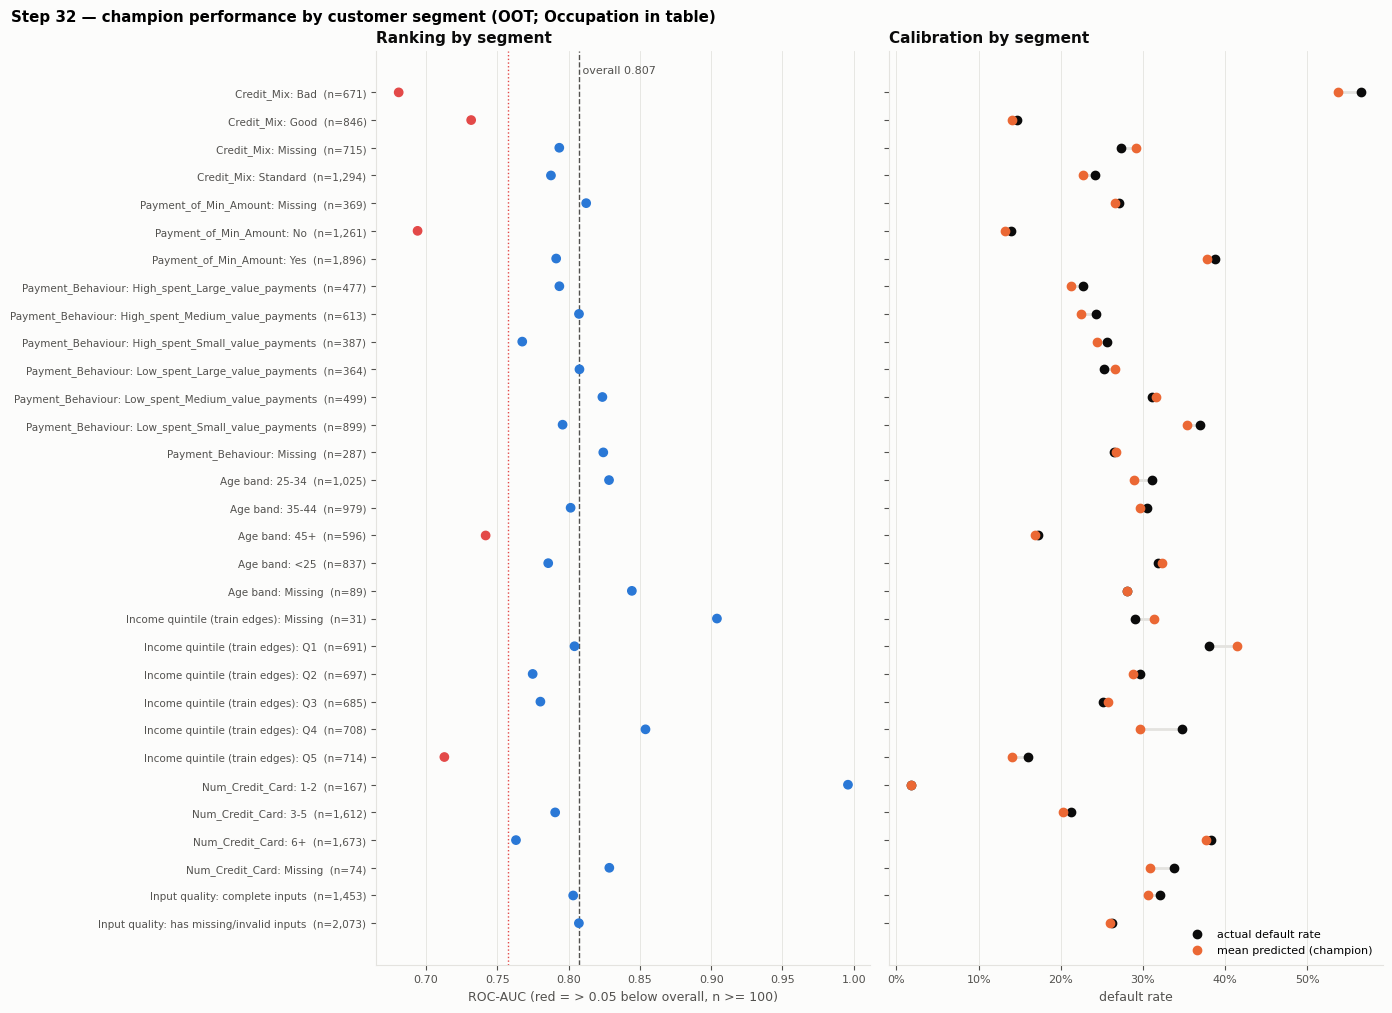

In [57]:
# Chart 1: OOT segment performance — ranking (ROC-AUC) and calibration (predicted vs actual default rate)
s = seg[(seg["partition"] == "oot") & (seg["variable"] != "(overall)") & (seg["variable"] != "Occupation")].copy()
s["label"] = s["variable"] + ": " + s["level"] + "  (n=" + s["n"].map("{:,}".format) + ")"
s = s.iloc[::-1].reset_index(drop=True)
y = np.arange(len(s))
fig, axes = plt.subplots(1, 2, figsize=(14, 0.28 * len(s) + 1.6), sharey=True)
roc_all = ov.loc["oot", "roc_auc"]
col = np.where(s["flag_weak_ranking"], "#e34948", SERIES[0])
axes[0].scatter(s["roc_auc"], y, s=36, color=col, zorder=3)
axes[0].axvline(roc_all, color=INK_2, linestyle="--", linewidth=1)
axes[0].axvline(roc_all - 0.05, color="#e34948", linestyle=":", linewidth=1)
axes[0].text(roc_all, len(s) - 0.3, f" overall {roc_all:.3f}", fontsize=8, color=INK_2)
axes[0].set_xlabel("ROC-AUC (red = > 0.05 below overall, n >= 100)")
axes[0].set_yticks(y, s["label"], fontsize=7.5)
axes[0].set_title("Ranking by segment", loc="left")
axes[1].hlines(y, s["default_rate"], s["mean_predicted"], color=GRID, linewidth=2)
axes[1].scatter(s["default_rate"], y, s=36, color=INK, zorder=3, label="actual default rate")
axes[1].scatter(s["mean_predicted"], y, s=36, color=SERIES[1], zorder=3, label="mean predicted (champion)")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_xlabel("default rate")
axes[1].set_title("Calibration by segment", loc="left")
axes[1].legend(loc="lower right", fontsize=8)
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle("Step 32 — champion performance by customer segment (OOT; Occupation in table)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "32_1_segment_performance.png"), dpi=130, bbox_inches="tight")
plt.show()

TN: correct good loan    1993
TP: caught defaulter      707
FP: false alarm           522
FN: missed defaulter      304


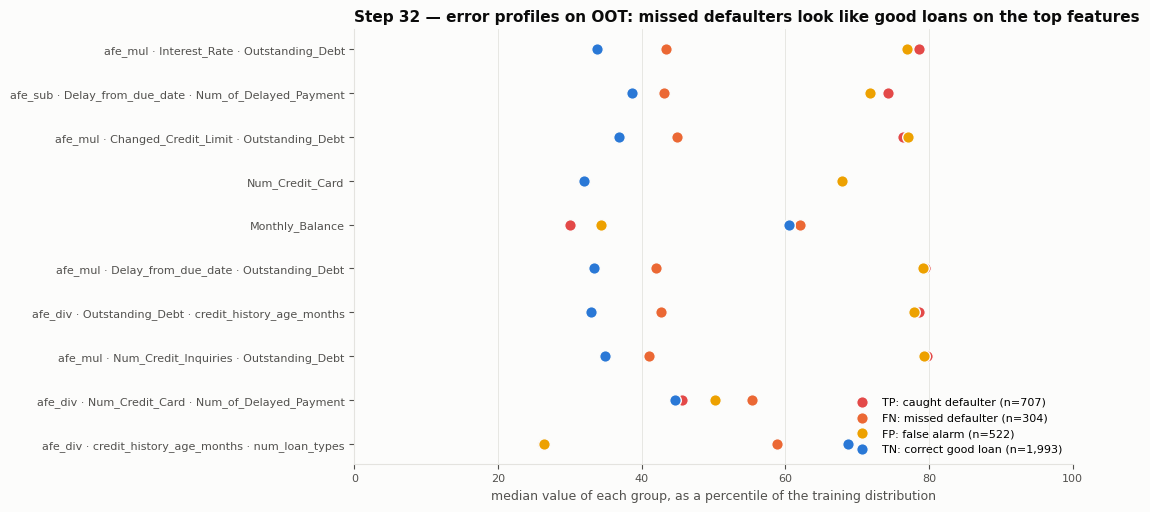

In [58]:
# B. Error profiles on OOT: where do TP / FN / FP / TN sit on the top features (percentile within train)?
y_oot = oot_df["label"].values
pred_oot = pA["oot"] >= thrA
outcome = np.select([pred_oot & (y_oot == 1), ~pred_oot & (y_oot == 1), pred_oot & (y_oot == 0)],
                    ["TP: caught defaulter", "FN: missed defaulter", "FP: false alarm"], "TN: correct good loan")
top_num = [f for f in final_shap[final_shap["model"] == "A"]["feature"] if f not in CAT][:10]
prof_rows = []
for f in top_num:
    tr_vals = train_df[f].dropna().values
    for o in ["TP: caught defaulter", "FN: missed defaulter", "FP: false alarm", "TN: correct good loan"]:
        med = np.nanmedian(oot_df.loc[outcome == o, f])
        prof_rows.append(dict(feature=f, outcome=o, n=int((outcome == o).sum()), median=med,
                              train_percentile=100 * (tr_vals < med).mean()))
prof = pd.DataFrame(prof_rows)
prof.to_csv(os.path.join(MD_DIR, "error_profiles.csv"), index=False)
print(pd.Series(outcome).value_counts().to_string())

O_COLORS = {"TP: caught defaulter": "#e34948", "FN: missed defaulter": SERIES[1], "FP: false alarm": SERIES[3],
            "TN: correct good loan": SERIES[0]}
fig, ax = plt.subplots(figsize=(11, 5.2))
yy = np.arange(len(top_num))[::-1]
for o, c in O_COLORS.items():
    d = prof[prof["outcome"] == o].set_index("feature").loc[top_num]
    ax.scatter(d["train_percentile"], yy, s=70, color=c, label=f"{o} (n={int(d['n'].iloc[0]):,})", zorder=3,
               edgecolors=SURFACE, linewidths=1)
ax.set_yticks(yy, [textwrap.shorten(f.replace("__", " · "), 55) for f in top_num], fontsize=8)
ax.set_xlim(0, 100)
ax.set_xlabel("median value of each group, as a percentile of the training distribution")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
ax.set_title("Step 32 — error profiles on OOT: missed defaulters look like good loans on the top features",
             loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "32_2_error_profiles.png"), dpi=130, bbox_inches="tight")
plt.show()

In [59]:
# C. Most confident errors on OOT, with their top-3 SHAP drivers
sv_oot, _ = shap_by_feature(CH, oot_df, fA)
def drivers(i, sign):
    s = sv_oot.iloc[i]
    s = s[s * sign > 0].sort_values(ascending=sign < 0) if sign else s
    return "; ".join(f"{f} ({v:+.2f})" for f, v in s.head(3).items())
fn_idx = np.where(outcome == "FN: missed defaulter")[0]
fp_idx = np.where(outcome == "FP: false alarm")[0]
conf = pd.concat([
    pd.DataFrame({"type": "missed defaulter (lowest score)", "loan_id": oot_df["loan_id"].values[i], "p": pA["oot"][i],
                  "main reasons score was low": drivers(i, -1)} for i in fn_idx[np.argsort(pA["oot"][fn_idx])[:10]]),
    pd.DataFrame({"type": "false alarm (highest score)", "loan_id": oot_df["loan_id"].values[i], "p": pA["oot"][i],
                  "main reasons score was high": drivers(i, 1)} for i in fp_idx[np.argsort(-pA["oot"][fp_idx])[:10]]),
], ignore_index=True)
conf.to_csv(os.path.join(MD_DIR, "confident_errors.csv"), index=False)
# how often each feature is a top-3 'wrong-direction' driver among all FN (pushing risk down) and FP (pushing risk up)
top_wrong = pd.concat([sv_oot.iloc[fn_idx].apply(lambda r: r.nsmallest(3).index.tolist(), axis=1).explode()
                       .value_counts().head(5).rename("FN: share of missed defaulters") / len(fn_idx),
                       sv_oot.iloc[fp_idx].apply(lambda r: r.nlargest(3).index.tolist(), axis=1).explode()
                       .value_counts().head(5).rename("FP: share of false alarms") / len(fp_idx)], axis=1)
display(top_wrong.style.format("{:.0%}", na_rep="").set_caption("Features most often among the top-3 drivers of errors"))
conf.style.hide(axis="index").format({"p": "{:.3f}"}).set_caption("10 most confident errors of each kind (OOT)")

,FN: share of missed defaulters,FP: share of false alarms
afe_mul__Interest_Rate__Outstanding_Debt,83%,74%
Payment_Behaviour,42%,40%
afe_div__credit_history_age_months__num_loan_types,17%,
afe_div__Outstanding_Debt__credit_history_age_months,15%,
afe_mul__Age__Num_Credit_Inquiries,13%,
afe_sub__Delay_from_due_date__Num_of_Delayed_Payment,,33%
afe_mul__Changed_Credit_Limit__Outstanding_Debt,,30%
afe_mul__Num_Credit_Inquiries__Outstanding_Debt,,20%


type,loan_id,p,main reasons score was low,main reasons score was high
missed defaulter (lowest score),CUS_0xbfef_2025_01_01,0.014,afe_div__Total_EMI_per_month__num_loan_types (-0.92); afe_div__Total_EMI_per_month__Monthly_Balance (-0.59); afe_mul__Interest_Rate__Outstanding_Debt (-0.36),nan
missed defaulter (lowest score),CUS_0x58d6_2024_11_01,0.019,afe_sub__Total_EMI_per_month__Amount_invested_monthly (-1.23); afe_mul__Interest_Rate__Outstanding_Debt (-0.45); afe_div__Num_Credit_Card__Num_of_Delayed_Payment (-0.23),nan
missed defaulter (lowest score),CUS_0xa26b_2025_01_01,0.023,afe_div__Total_EMI_per_month__Monthly_Balance (-0.55); afe_div__Total_EMI_per_month__num_loan_types (-0.36); Monthly_Balance (-0.31),nan
missed defaulter (lowest score),CUS_0x1a57_2024_08_01,0.024,afe_div__Total_EMI_per_month__Monthly_Balance (-0.55); afe_mul__Interest_Rate__Outstanding_Debt (-0.48); Monthly_Balance (-0.26),nan
missed defaulter (lowest score),CUS_0x6244_2025_01_01,0.026,afe_mul__Interest_Rate__Outstanding_Debt (-0.51); afe_div__Outstanding_Debt__credit_history_age_months (-0.37); afe_div__credit_history_age_months__num_loan_types (-0.27),nan
missed defaulter (lowest score),CUS_0x6938_2024_08_01,0.029,afe_div__Total_EMI_per_month__Monthly_Balance (-0.49); afe_div__Total_EMI_per_month__num_loan_types (-0.34); Amount_invested_monthly (-0.30),nan
missed defaulter (lowest score),CUS_0x855f_2024_07_01,0.030,afe_sub__Total_EMI_per_month__Amount_invested_monthly (-1.02); afe_div__Total_EMI_per_month__Monthly_Balance (-0.61); afe_mul__Interest_Rate__Outstanding_Debt (-0.39),nan
missed defaulter (lowest score),CUS_0x351d_2024_11_01,0.034,afe_mul__Interest_Rate__Outstanding_Debt (-0.32); afe_div__Outstanding_Debt__credit_history_age_months (-0.31); afe_div__credit_history_age_months__num_loan_types (-0.30),nan
missed defaulter (lowest score),CUS_0x9466_2024_09_01,0.039,afe_mul__Interest_Rate__Outstanding_Debt (-0.49); afe_sub__Total_EMI_per_month__Amount_invested_monthly (-0.41); afe_div__credit_history_age_months__num_loan_types (-0.23),nan
missed defaulter (lowest score),CUS_0x6ed7_2024_12_01,0.039,afe_div__Total_EMI_per_month__num_loan_types (-1.56); afe_div__Annual_Income__Total_EMI_per_month (-0.69); Payment_Behaviour (-0.38),nan


In [60]:
# D. Input robustness on OOT (perturbed copies; model untouched)
num_cols = [c for c in fA if c not in CAT and c not in BINARY]
base_auc = average_precision_score(y_oot, pA["oot"])
def run_perturb(kind, level, reps=5):
    out = []
    for r in range(reps):
        g = np.random.default_rng(SEED + r)
        X = oot_df[fA].copy()
        if kind == "noise":                                  # multiplicative noise on numeric inputs
            for c in num_cols:
                X[c] = X[c] * (1 + g.normal(0, level, len(X)))
        elif kind == "missing":                              # random cells blanked across all model inputs
            mask = g.random(X.shape) < level
            X = X.mask(mask)
        p = CH.predict_proba(X)[:, 1]
        out.append(dict(pr_auc=average_precision_score(y_oot, p), mean_abs_change=np.abs(p - pA["oot"]).mean(),
                        decision_flip_rate=((p >= thrA) != (pA["oot"] >= thrA)).mean()))
    o = pd.DataFrame(out).mean()
    return dict(test=kind, level=level, pr_auc=o["pr_auc"], pr_auc_change=o["pr_auc"] - base_auc,
                mean_abs_change_in_p=o["mean_abs_change"], decision_flip_rate=o["decision_flip_rate"])
pert = pd.DataFrame([run_perturb("noise", s) for s in [0.0, 0.05, 0.10, 0.20, 0.30]] +
                    [run_perturb("missing", m) for m in [0.0, 0.05, 0.10, 0.20, 0.30]])
pert.to_csv(os.path.join(MD_DIR, "robustness_perturbation.csv"), index=False)

# one feature missing for every loan (e.g. a source field breaks)
one_rows = []
for f in final_shap[final_shap["model"] == "A"]["feature"].head(10):
    X = oot_df[fA].copy(); X[f] = np.nan
    p = CH.predict_proba(X)[:, 1]
    one_rows.append(dict(feature=f, pr_auc=average_precision_score(y_oot, p),
                         pr_auc_change=average_precision_score(y_oot, p) - base_auc,
                         decision_flip_rate=((p >= thrA) != (pA["oot"] >= thrA)).mean()))
one_missing = pd.DataFrame(one_rows).sort_values("pr_auc_change")
one_missing.to_csv(os.path.join(MD_DIR, "robustness_feature_missing.csv"), index=False)

# functional stress tests (pass / fail)
def valid(p): return bool(np.all(np.isfinite(p)) and np.all((p > 0) & (p < 1)))
X0 = oot_df[fA].head(200).copy()
p0 = CH.predict_proba(X0)[:, 1]
tests = []
def stress(name, fn):
    try:
        ok, note = fn()
    except Exception as e:                                   # a crash is a failed test
        ok, note = False, f"error: {type(e).__name__}: {e}"
    tests.append(dict(test=name, passed=bool(ok), note=note))
stress("all inputs missing -> valid probability", lambda: (valid(CH.predict_proba(X0.head(1).mask(np.ones((1, len(fA)), bool)))[:, 1]),
                                                           "row of NaN scored"))
def unseen():
    X = X0.copy()
    for c in [c for c in fA if c in CAT]:
        X[c] = "UNSEEN_CATEGORY"
    return valid(CH.predict_proba(X)[:, 1]), f"unseen value in {[c for c in fA if c in CAT]}"
stress("unseen category values -> valid probability", unseen)
def extreme():
    X = X0.copy()
    for c in num_cols:
        X[c] = X[c] * 100
    return valid(CH.predict_proba(X)[:, 1]), "numeric inputs x100"
stress("extreme numeric values -> valid probability", extreme)
stress("column order shuffled -> identical predictions",
       lambda: (np.allclose(CH.predict_proba(X0[list(reversed(fA))])[:, 1], p0), "reversed column order"))
stress("extra unused columns -> identical predictions",
       lambda: (np.allclose(CH.predict_proba(oot_df.head(200))[:, 1], p0), "full Gold row passed in"))
stress("deterministic (same input twice)", lambda: (np.array_equal(CH.predict_proba(X0)[:, 1], p0), "repeat call"))
stress("single-row = batch predictions",
       lambda: (np.allclose([CH.predict_proba(X0.iloc[[i]])[:, 1][0] for i in range(20)], p0[:20]), "20 rows one by one"))
def missing_col():
    try:
        CH.predict_proba(X0.drop(columns=[fA[0]]))
        return False, "missing column was silently accepted"
    except Exception as e:
        return True, f"rejected with {type(e).__name__} (good: schema errors surface)"
stress("required column absent -> clear error (not silent)", missing_col)
stress_tbl = pd.DataFrame(tests)
stress_tbl.to_csv(os.path.join(MD_DIR, "robustness_stress_tests.csv"), index=False)
display(stress_tbl.style.hide(axis="index").set_caption("Functional stress tests"))
display(one_missing.style.hide(axis="index").format({"pr_auc": "{:.3f}", "pr_auc_change": "{:+.3f}",
                                                      "decision_flip_rate": "{:.1%}"})
        .set_caption("One feature missing for every OOT loan"))
pert.style.hide(axis="index").format({"level": "{:.0%}", "pr_auc": "{:.3f}", "pr_auc_change": "{:+.3f}",
                                      "mean_abs_change_in_p": "{:.3f}", "decision_flip_rate": "{:.1%}"}) \
    .set_caption("Noise / random-missing perturbation (mean of 5 repeats)")

test,passed,note
all inputs missing -> valid probability,True,row of NaN scored
unseen category values -> valid probability,True,"unseen value in ['Payment_Behaviour', 'Credit_Mix']"
extreme numeric values -> valid probability,True,numeric inputs x100
column order shuffled -> identical predictions,True,reversed column order
extra unused columns -> identical predictions,True,full Gold row passed in
deterministic (same input twice),True,repeat call
single-row = batch predictions,True,20 rows one by one
required column absent -> clear error (not silent),True,rejected with ValueError (good: schema errors surface)


feature,pr_auc,pr_auc_change,decision_flip_rate
afe_mul__Interest_Rate__Outstanding_Debt,0.577,-0.042,5.0%
afe_mul__Changed_Credit_Limit__Outstanding_Debt,0.588,-0.030,3.9%
Payment_Behaviour,0.605,-0.014,3.9%
afe_div__Outstanding_Debt__credit_history_age_months,0.608,-0.011,3.1%
afe_sub__Delay_from_due_date__Num_of_Delayed_Payment,0.613,-0.006,2.3%
afe_mul__Delay_from_due_date__Outstanding_Debt,0.615,-0.004,1.8%
Num_Credit_Card,0.617,-0.001,1.2%
afe_div__Num_Credit_Card__Num_of_Delayed_Payment,0.619,-0.000,2.4%
Monthly_Balance,0.619,+0.000,4.2%
afe_mul__Num_Credit_Inquiries__Outstanding_Debt,0.622,+0.003,2.1%


test,level,pr_auc,pr_auc_change,mean_abs_change_in_p,decision_flip_rate
noise,0%,0.619,+0.000,0.000,0.0%
noise,5%,0.615,-0.004,0.036,4.1%
noise,10%,0.615,-0.004,0.048,5.6%
noise,20%,0.607,-0.011,0.068,8.2%
noise,30%,0.588,-0.031,0.085,10.7%
missing,0%,0.619,+0.000,0.000,0.0%
missing,5%,0.613,-0.006,0.024,2.5%
missing,10%,0.606,-0.013,0.040,4.7%
missing,20%,0.594,-0.025,0.065,7.6%
missing,30%,0.572,-0.047,0.085,10.3%


In [61]:
# E. Stability: retrain with 5 seeds (same data, features, settings) + threshold sensitivity on OOT
seed_rows = []
for sd in range(5):
    params = dict(FINAL["A"]["params"])
    m = Pipeline([("pre", fe.build_preprocessor(fA, "tree", CAT, BINARY, FLAGGED)),
                  ("model", XGBClassifier(**params, tree_method="hist", eval_metric="aucpr", n_jobs=-1, random_state=sd))])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m.fit(train_df[fA], train_df["label"])
    row = dict(seed=sd)
    for part, d in [("test", test_df), ("oot", oot_df)]:
        p = m.predict_proba(d[fA])[:, 1]
        row[f"{part}_pr_auc"] = average_precision_score(d["label"], p)
        row[f"{part}_decision_agreement"] = ((p >= thrA) == (pA[part] >= thrA)).mean()
    seed_rows.append(row)
seeds = pd.DataFrame(seed_rows)
seeds.to_csv(os.path.join(MD_DIR, "robustness_seed_stability.csv"), index=False)

thr_rows = []
for t in np.round(np.arange(thrA - 0.10, thrA + 0.1001, 0.02), 3):
    v = evaluate(y_oot, pA["oot"], threshold=t)
    thr_rows.append(dict(threshold=t, precision=v["precision"], recall=v["recall"], f1=v["f1"],
                         flagged_share=(v["tp"] + v["fp"]) / len(y_oot)))
thr_sens = pd.DataFrame(thr_rows)
thr_sens.to_csv(os.path.join(MD_DIR, "robustness_threshold_sensitivity.csv"), index=False)

# F. Challenger B with clickstream missing (OOT reality)
pB_oot = FINAL_MODELS["B"].predict_proba(oot_df[FINAL_FEATS["B"]])[:, 1]
vB = evaluate(y_oot, pB_oot, threshold=FIXED_THR["B"])
b_test = final_eval.query("partition=='test' and model=='challenger XGB model B'").iloc[0]
b_rows = pd.DataFrame([
    dict(model="challenger B — test (clickstream present)", pr_auc=b_test["pr_auc"], mean_predicted=b_test["mean_predicted"],
         flagged_share=b_test["flagged_share"]),
    dict(model="challenger B — OOT (clickstream missing)", pr_auc=vB["pr_auc"], mean_predicted=pB_oot.mean(),
         flagged_share=(vB["tp"] + vB["fp"]) / len(y_oot)),
    dict(model="champion A — OOT", pr_auc=base_auc, mean_predicted=pA["oot"].mean(),
         flagged_share=(pA["oot"] >= thrA).mean()),
])
b_rows.to_csv(os.path.join(MD_DIR, "robustness_challenger_without_clickstream.csv"), index=False)
display(seeds.style.hide(axis="index").format("{:.3f}", subset=["test_pr_auc", "oot_pr_auc"])
        .format("{:.1%}", subset=["test_decision_agreement", "oot_decision_agreement"])
        .set_caption("Seed stability (retrained 5 times)"))
display(b_rows.style.hide(axis="index").format({"pr_auc": "{:.3f}", "mean_predicted": "{:.3f}", "flagged_share": "{:.0%}"},
                                               na_rep="—").set_caption("Challenger B when clickstream is missing"))
thr_sens.style.hide(axis="index").format({"threshold": "{:.2f}", "precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}",
                                          "flagged_share": "{:.0%}"}).set_caption("Threshold sensitivity (OOT, champion)")

seed,test_pr_auc,test_decision_agreement,oot_pr_auc,oot_decision_agreement
0,0.606,96.1%,0.622,95.9%
1,0.621,96.9%,0.626,96.1%
2,0.619,96.3%,0.623,96.0%
3,0.615,97.0%,0.619,95.8%
4,0.610,96.4%,0.619,95.9%


model,pr_auc,mean_predicted,flagged_share
challenger B — test (clickstream present),0.640,0.280,34%
challenger B — OOT (clickstream missing),0.610,0.279,33%
champion A — OOT,0.619,0.279,35%


threshold,precision,recall,f1,flagged_share
0.19,0.494,0.792,0.609,46%
0.21,0.514,0.767,0.616,43%
0.23,0.529,0.747,0.619,40%
0.25,0.543,0.729,0.622,38%
0.27,0.562,0.714,0.629,36%
0.29,0.575,0.698,0.631,35%
0.31,0.583,0.682,0.629,34%
0.33,0.589,0.664,0.624,32%
0.35,0.597,0.647,0.621,31%
0.37,0.607,0.630,0.618,30%


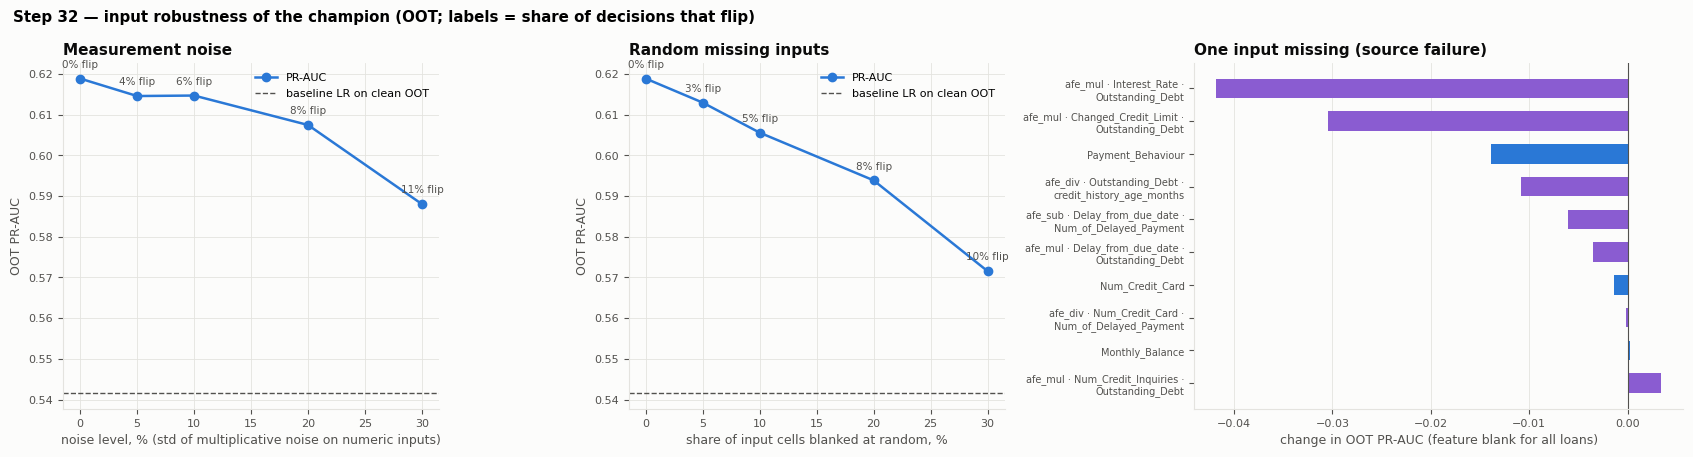

In [62]:
# Chart 3: robustness — noise, random missing, one feature missing
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, kind, xlabel in [(axes[0], "noise", "noise level (std of multiplicative noise on numeric inputs)"),
                         (axes[1], "missing", "share of input cells blanked at random")]:
    d = pert[pert["test"] == kind]
    ax.plot(d["level"] * 100, d["pr_auc"], "o-", color=SERIES[0], linewidth=1.8, label="PR-AUC")
    ax.axhline(final_eval.query("partition=='oot' and model=='baseline LR__A_raw'")["pr_auc"].iloc[0], color=INK_2,
               linestyle="--", linewidth=1, label="baseline LR on clean OOT")
    for x_, f_ in zip(d["level"] * 100, d["decision_flip_rate"]):
        ax.annotate(f"{f_:.0%} flip", (x_, d.set_index("level").loc[x_ / 100, "pr_auc"]), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=7.5, color=INK_2)
    ax.set_xlabel(xlabel.replace("level", "level, %") if kind == "noise" else xlabel + ", %")
    ax.set_ylabel("OOT PR-AUC"); ax.legend(loc="upper right", fontsize=8)
    ax.set_title({"noise": "Measurement noise", "missing": "Random missing inputs"}[kind], loc="left")
d = one_missing.iloc[::-1]
axes[2].barh([textwrap.fill(f.replace("__", " · "), 36) for f in d["feature"]], d["pr_auc_change"],
             color=[GROUP_COLORS[group_name(f)] for f in d["feature"]], height=0.6)
axes[2].axvline(0, color=INK_2, linewidth=0.8)
axes[2].set_xlabel("change in OOT PR-AUC (feature blank for all loans)")
axes[2].tick_params(axis="y", labelsize=7); axes[2].grid(axis="y", visible=False)
axes[2].set_title("One input missing (source failure)", loc="left")
fig.suptitle("Step 32 — input robustness of the champion (OOT; labels = share of decisions that flip)", x=0.01,
             ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "32_3_input_robustness.png"), dpi=130, bbox_inches="tight")
plt.show()

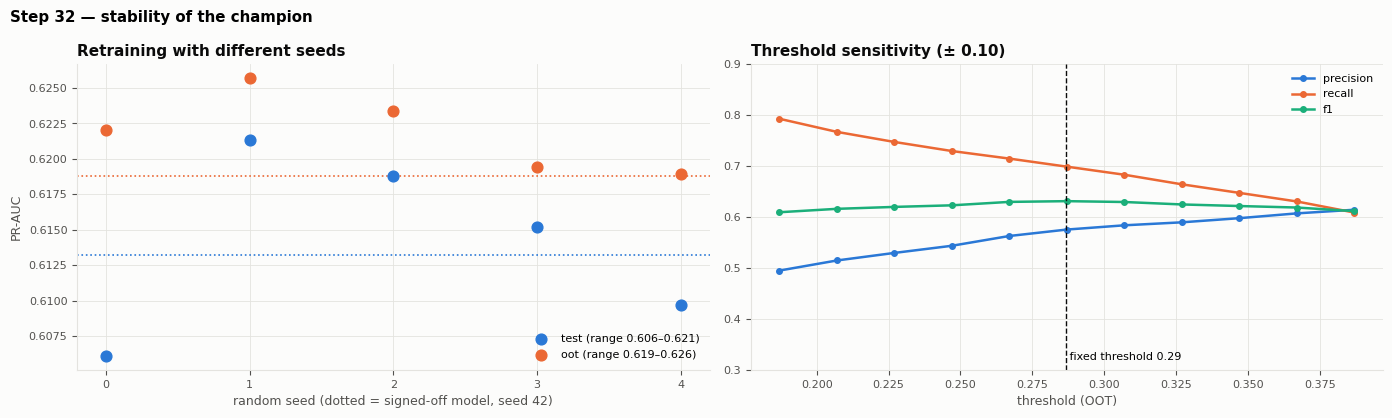

In [63]:
# Chart 4: stability — seeds and threshold sensitivity
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for part, c in [("test", SERIES[0]), ("oot", SERIES[1])]:
    axes[0].scatter(seeds["seed"], seeds[f"{part}_pr_auc"], s=60, color=c, label=f"{part} (range "
                    f"{seeds[f'{part}_pr_auc'].min():.3f}–{seeds[f'{part}_pr_auc'].max():.3f})", zorder=3)
    axes[0].axhline(final_eval.query(f"partition=='{part}' and model=='champion XGB model A'")["pr_auc"].iloc[0],
                    color=c, linestyle=":", linewidth=1.2)
axes[0].set_xticks(range(5)); axes[0].set_xlabel("random seed (dotted = signed-off model, seed 42)")
axes[0].set_ylabel("PR-AUC"); axes[0].legend(loc="lower right", fontsize=8)
axes[0].set_title("Retraining with different seeds", loc="left")
for col_, c in [("precision", SERIES[0]), ("recall", SERIES[1]), ("f1", SERIES[2])]:
    axes[1].plot(thr_sens["threshold"], thr_sens[col_], "o-", color=c, linewidth=1.8, markersize=4, label=col_)
axes[1].axvline(thrA, color=INK, linestyle="--", linewidth=1)
axes[1].text(thrA, 0.32, f" fixed threshold {thrA:.2f}", fontsize=8)
axes[1].set_xlabel("threshold (OOT)"); axes[1].set_ylim(0.3, 0.9)
axes[1].legend(loc="upper right", fontsize=8)
axes[1].set_title("Threshold sensitivity (± 0.10)", loc="left")
fig.suptitle("Step 32 — stability of the champion", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "32_4_stability.png"), dpi=130, bbox_inches="tight")
plt.show()

In [64]:
# Summary record
noise10 = pert[(pert["test"] == "noise") & (np.isclose(pert["level"], 0.10))].iloc[0]
miss10 = pert[(pert["test"] == "missing") & (np.isclose(pert["level"], 0.10))].iloc[0]
summary = {
    "step": 32, "version": MD_VERSION, "models_changed": False,
    "segments": {"flagged_count": int(len(flagged)),
                 "flagged": flagged[["partition", "variable", "level", "n", "roc_auc", "calibration_gap",
                                     "flag_weak_ranking", "flag_miscalibrated"]].round(4).to_dict(orient="records")},
    "error_counts_oot": pd.Series(outcome).value_counts().to_dict(),
    "robustness": {"noise_10pct": {"pr_auc_change": round(float(noise10["pr_auc_change"]), 4),
                                   "decision_flip_rate": round(float(noise10["decision_flip_rate"]), 4)},
                   "random_missing_10pct": {"pr_auc_change": round(float(miss10["pr_auc_change"]), 4),
                                            "decision_flip_rate": round(float(miss10["decision_flip_rate"]), 4)},
                   "worst_single_feature_missing": one_missing.iloc[0][["feature", "pr_auc_change"]].to_dict(),
                   "stress_tests_passed": f"{int(stress_tbl['passed'].sum())}/{len(stress_tbl)}"},
    "stability": {"seed_oot_pr_auc_range": [round(float(seeds["oot_pr_auc"].min()), 4),
                                            round(float(seeds["oot_pr_auc"].max()), 4)],
                  "seed_oot_decision_agreement_min": round(float(seeds["oot_decision_agreement"].min()), 4),
                  "f1_range_threshold_pm_0_10": [round(float(thr_sens["f1"].min()), 4), round(float(thr_sens["f1"].max()), 4)]},
    "challenger_without_clickstream_oot_pr_auc": round(float(vB["pr_auc"]), 4),
}
with open(os.path.join(MD_DIR, "error_robustness_summary.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(summary, f, sort_keys=False, allow_unicode=True, default_flow_style=False)
print(yaml.safe_dump(summary["robustness"], sort_keys=False))
print(yaml.safe_dump(summary["stability"], sort_keys=False))

noise_10pct:
  pr_auc_change: -0.0042
  decision_flip_rate: 0.0565
random_missing_10pct:
  pr_auc_change: -0.0133
  decision_flip_rate: 0.0469
worst_single_feature_missing:
  feature: afe_mul__Interest_Rate__Outstanding_Debt
  pr_auc_change: -0.041795330712099954
stress_tests_passed: 8/8

seed_oot_pr_auc_range:
- 0.6189
- 0.6257
seed_oot_decision_agreement_min: 0.9583
f1_range_threshold_pm_0_10:
- 0.6089
- 0.6306

